In [1]:
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as pl #importa o pacote de plotagem
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 400
import seaborn as sns
import numpy as np
import plotly.express as px

In [26]:
df_estat_bovino = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_doenças_país.parquet')
df_estat_bovino_sudeste = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_doenças_sudeste.parquet')
df_estat_bovino_se_infecto = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_doenças_SE_infecto.parquet')
df_estat_bovino_abate = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_bubalinos_abate_país.parquet')
df_estat_bovino_abate_sudeste = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_bubalinos_abate_se.parquet')
print(df_estat_bovino.head())
print(df_estat_bovino_sudeste.head())
print(df_estat_bovino_se_infecto.head())
print(df_estat_bovino_abate.head())
print(df_estat_bovino_abate_sudeste.head())

   MES_ANO UF_PROCEDENCIA ESPECIE                    DIAGNOSTICO  \
0  12/2025             RO  Bovino                     septicemia   
1  01/2023             BA  Bovino           morto (no pré abate)   
2  01/2023             RS  Bovino      artrite (uma articulação)   
3  01/2024             MS  Bovino  tuberculose (notificação sif)   
4  01/2025             RS  Bovino          parto recente (fêmea)   

   NUMERO_ANIMAIS_ACOMETIDOS  
0                          1  
1                          1  
2                          1  
3                          1  
4                          1  
   MES_ANO UF_PROCEDENCIA ESPECIE  \
0  12/2021             SP  Bovino   
1  09/2023             SP  Bovino   
2  08/2021             SP  Bovino   
3  08/2023             SP  Bovino   
4  09/2022             SP  Bovino   

                                     DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  
0  material especificado de risco (inutilização)                      45077  
1  material especificado d

Análise estatística de doenças sudeste

In [27]:
df_estat_bovino_sudeste.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6477 entries, 0 to 6476
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   MES_ANO                    6477 non-null   object
 1   UF_PROCEDENCIA             6477 non-null   object
 2   ESPECIE                    6477 non-null   object
 3   DIAGNOSTICO                6477 non-null   object
 4   NUMERO_ANIMAIS_ACOMETIDOS  6477 non-null   int64 
dtypes: int64(1), object(4)
memory usage: 253.1+ KB


In [28]:
df_estat_bovino_sudeste.describe()

,NUMERO_ANIMAIS_ACOMETIDOS
count,6477.000000
mean,661.784005
std,3434.573020
min,1.000000
25%,1.000000
50%,6.000000
75%,61.000000
max,45077.000000


In [30]:
#CONFERINDO O VALOR MÁXIMO DO DESCRIBE
df_estat_bovino_sudeste_max = df_estat_bovino_sudeste[['UF_PROCEDENCIA','DIAGNOSTICO','NUMERO_ANIMAIS_ACOMETIDOS']].max()
print(df_estat_bovino_sudeste_max)

UF_PROCEDENCIA                              SP
DIAGNOSTICO                  útero com feto(s)
NUMERO_ANIMAIS_ACOMETIDOS                45077
dtype: object


In [65]:
#CONFERINDO O VALOR MÁXIMO DO DESCRIBE
df_estat_bovino_sudeste_min = df_estat_bovino_sudeste[['UF_PROCEDENCIA','DIAGNOSTICO','NUMERO_ANIMAIS_ACOMETIDOS']].min()
print(df_estat_bovino_sudeste_min)

UF_PROCEDENCIA                                                      ES
DIAGNOSTICO                  aborto enzoótico das ovelhas (confirmado)
NUMERO_ANIMAIS_ACOMETIDOS                                            1
dtype: object


In [85]:
df_estat_bovino_sudeste_aeo = df_estat_bovino_sudeste[(df_estat_bovino_sudeste['DIAGNOSTICO'].isin(['material especificado de risco (inutilização)']))]
df_estat_bovino_sudeste_sum = df_estat_bovino_sudeste_aeo.groupby(['UF_PROCEDENCIA','DIAGNOSTICO'])['NUMERO_ANIMAIS_ACOMETIDOS'].sum()
print(df_estat_bovino_sudeste_sum)

UF_PROCEDENCIA  DIAGNOSTICO                                  
ES              material especificado de risco (inutilização)      30082
MG              material especificado de risco (inutilização)     917083
RJ              material especificado de risco (inutilização)      15152
SP              material especificado de risco (inutilização)    1756132
Name: NUMERO_ANIMAIS_ACOMETIDOS, dtype: int64


In [86]:
#adequando o formato da coluna de data para extrair o ano
df_estat_bovino_sudeste["MES_ANO"] = pd.to_datetime(df_estat_bovino_sudeste["MES_ANO"], format="%m/%Y", errors='coerce')
df_estat_bovino_sudeste["ANO"] = df_estat_bovino_sudeste["MES_ANO"].dt.year
print(df_estat_bovino_sudeste.head(10))

     MES_ANO UF_PROCEDENCIA ESPECIE  \
0 2021-12-01             SP  Bovino   
1 2023-09-01             SP  Bovino   
2 2021-08-01             SP  Bovino   
3 2023-08-01             SP  Bovino   
4 2022-09-01             SP  Bovino   
5 2023-12-01             SP  Bovino   
6 2022-12-01             SP  Bovino   
7 2024-04-01             SP  Bovino   
8 2023-02-01             SP  Bovino   
9 2023-10-01             SP  Bovino   

                                     DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  \
0  material especificado de risco (inutilização)                      45077   
1  material especificado de risco (inutilização)                      39842   
2  material especificado de risco (inutilização)                      39043   
3  material especificado de risco (inutilização)                      38687   
4  material especificado de risco (inutilização)                      37827   
5  material especificado de risco (inutilização)                      37436   
6  material espec

In [34]:
#Realizando o resumo por ano, estado de procedência e diagnóstico
variaveis = ["ANO","UF_PROCEDENCIA", "DIAGNOSTICO"]

for var in variaveis:
    resumo = (
        df_estat_bovino_sudeste.groupby(var, as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
          .sum()
          .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
    )
    
    resumo["percentual"] = (
        resumo["NUMERO_ANIMAIS_ACOMETIDOS"] / resumo["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
    )
    
    print(f"\nResumo por {var}")
    display(resumo.head(20))


Resumo por ANO


,ANO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
2,2023,1041601,24.300277
1,2022,945925,22.068181
3,2024,745041,17.381610
0,2021,742176,17.314771
4,2025,662984,15.467242
5,2026,148648,3.467919



Resumo por UF_PROCEDENCIA


,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS,percentual
3,SP,2848023,66.443627
1,MG,1310993,30.585121
0,ES,95247,2.222087
2,RJ,32112,0.749165



Resumo por DIAGNOSTICO


,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
94,material especificado de risco (inutilização),2718449,63.420699
14,alteração restrita,651247,15.193421
48,contaminação gastrointestinal e biliar,600921,14.019329
49,contaminação não gastrointestinal,98640,2.301245
81,lesão inflamatória,64212,1.498049
66,fasciolose hepática (notificação sif),28104,0.655659
3,abscesso (mamíferos),19188,0.447651
38,cisticercose bovina,17481,0.407827
103,parasitose não zoonótica,16247,0.379038
24,aspiração de líquido,12529,0.292298


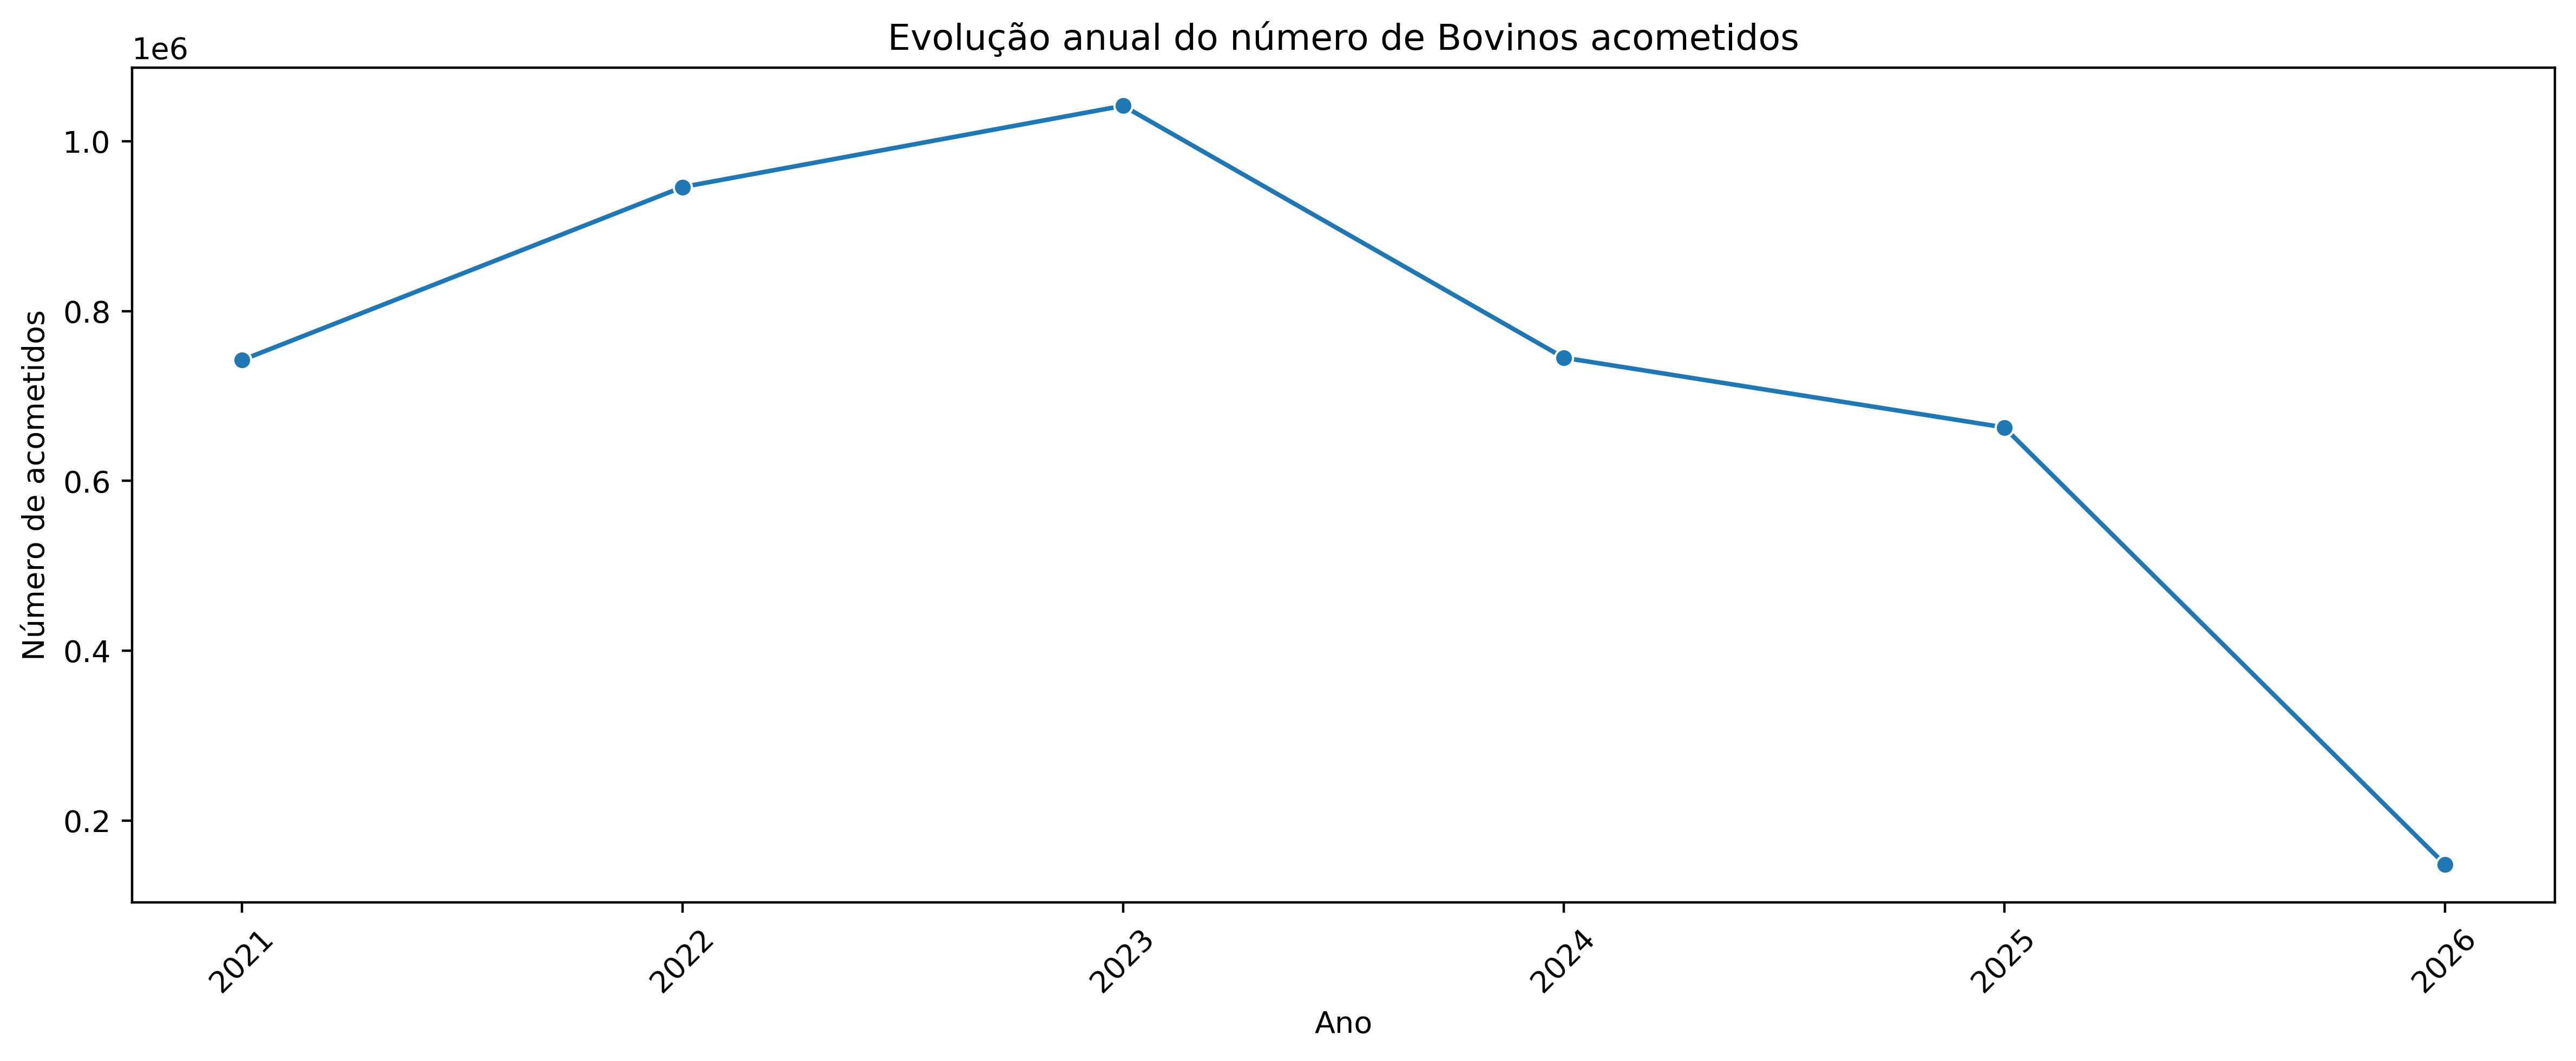

In [35]:
#criando a série anual do número de acometidos por ano
serie_anual = (
   df_estat_bovino_sudeste.groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("ANO")
)

pl.figure(figsize=(12, 5))
sns.lineplot(
    data=serie_anual,
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    marker="o"
)

pl.title("Evolução anual do número de Bovinos acometidos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.xticks(rotation=45)
pl.tight_layout()
pl.show()

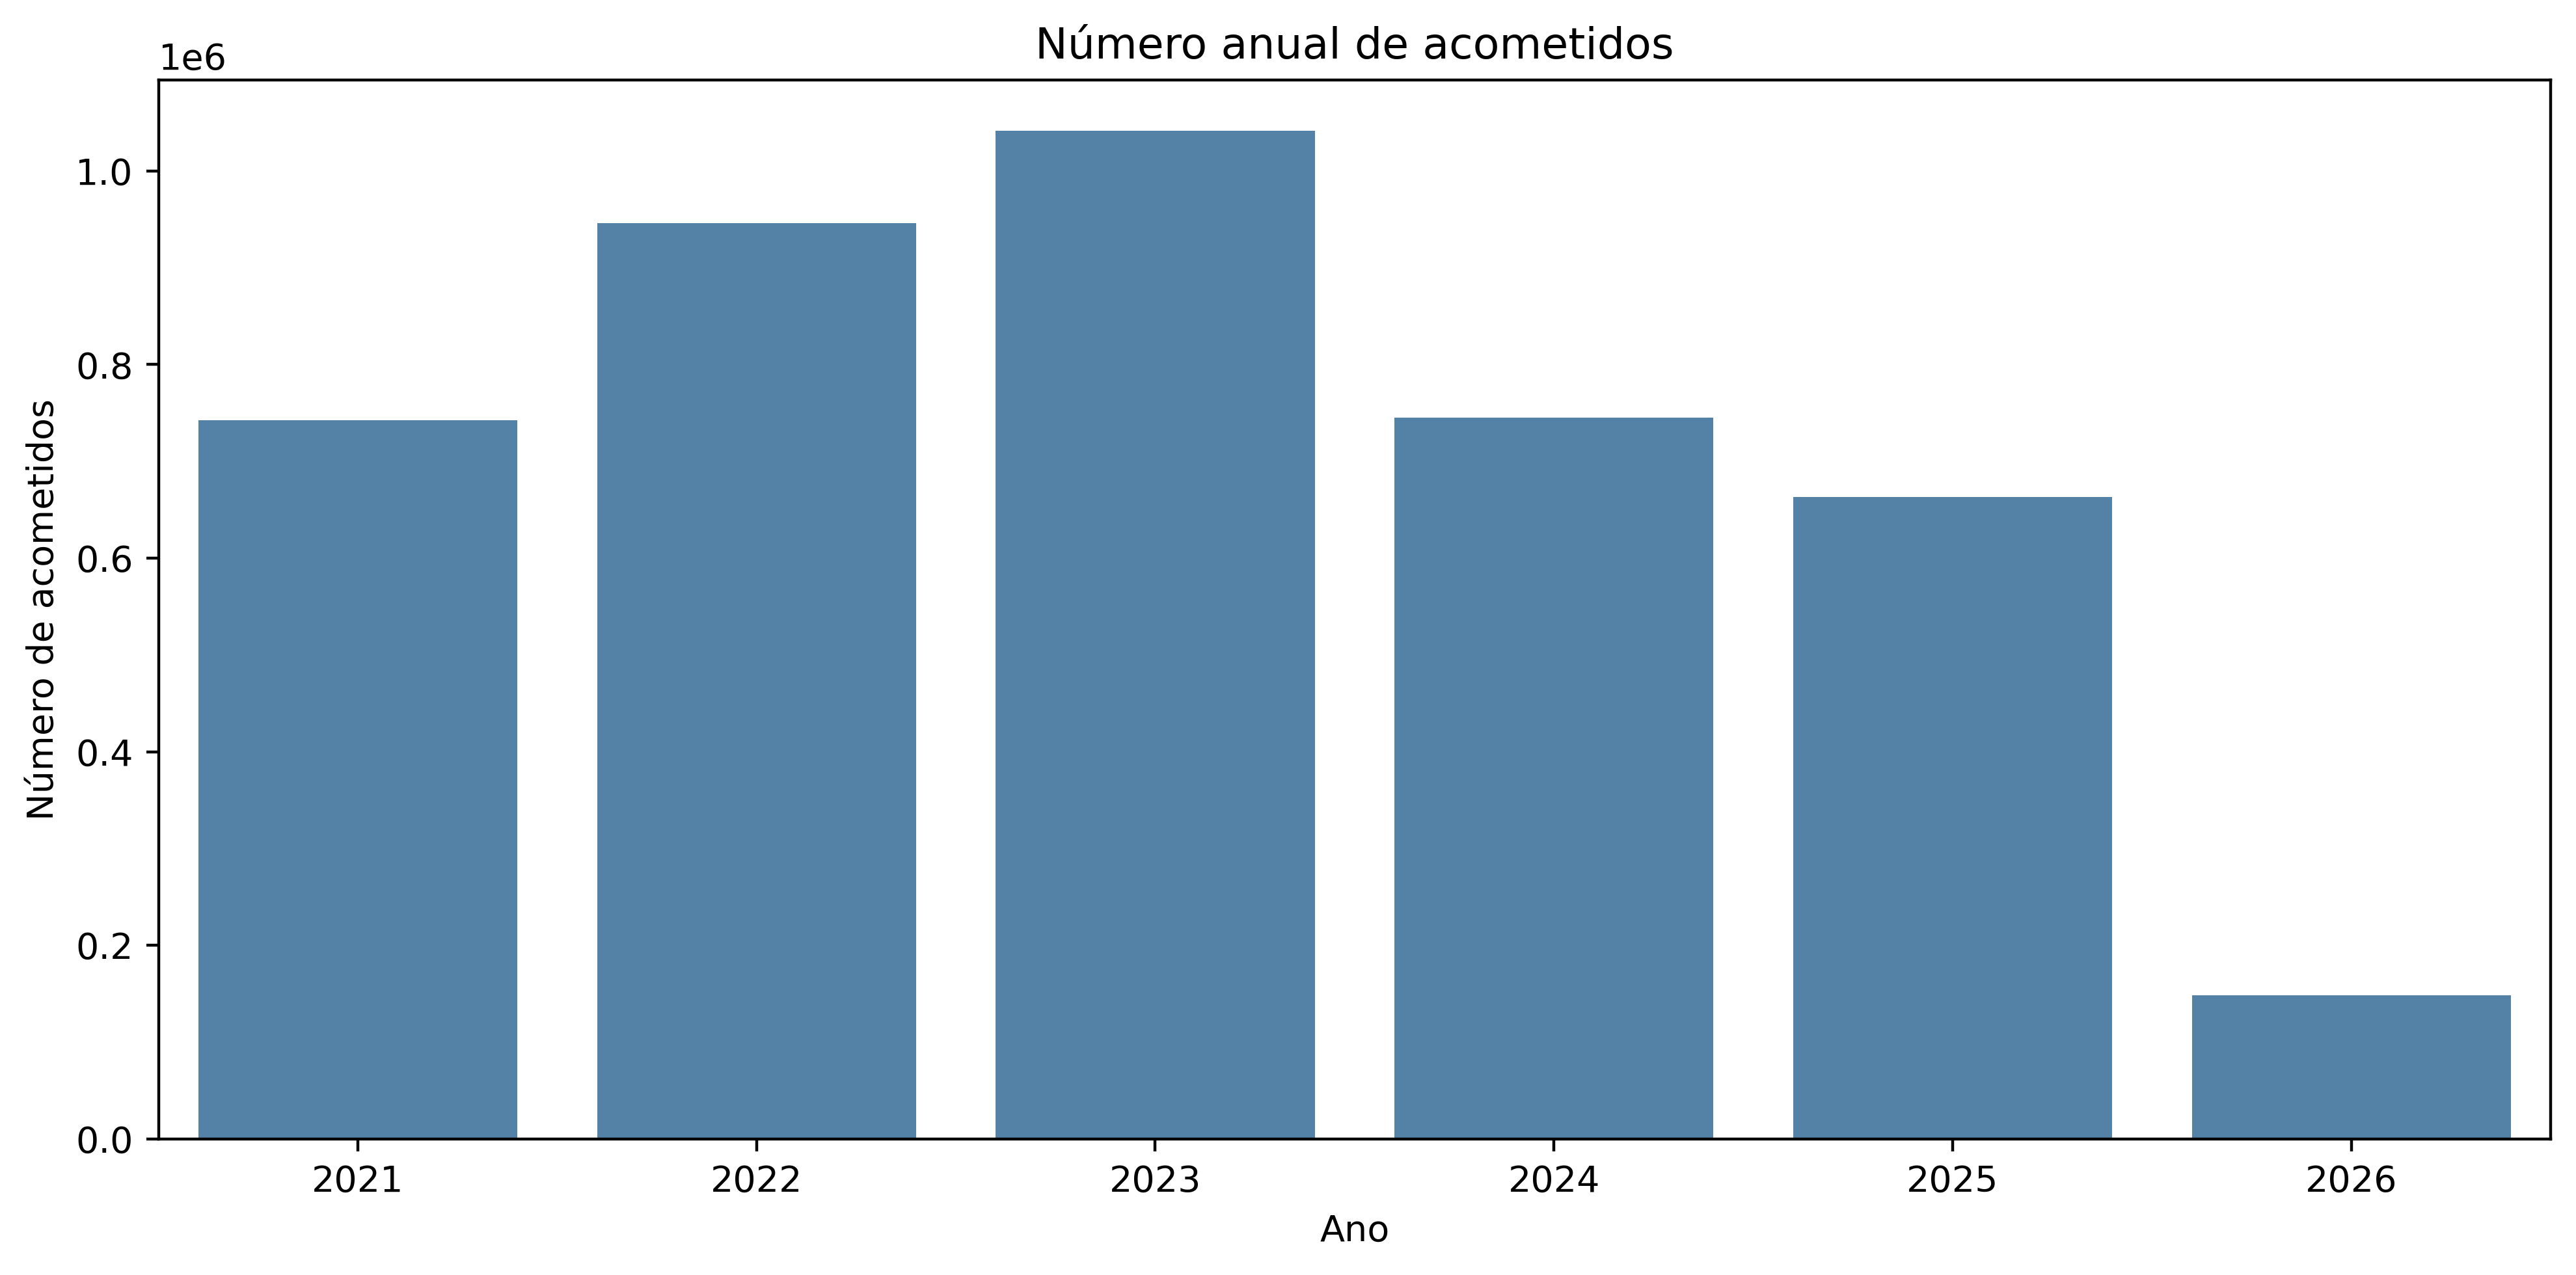

In [36]:
#criando o gráfico de barras do número anual de acometidos
pl.figure(figsize=(10, 5))

sns.barplot(
    data = (
    df_estat_bovino_sudeste.groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("ANO")
                        ),
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    color="steelblue"
)

pl.title("Número anual de acometidos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.tight_layout()
pl.show()

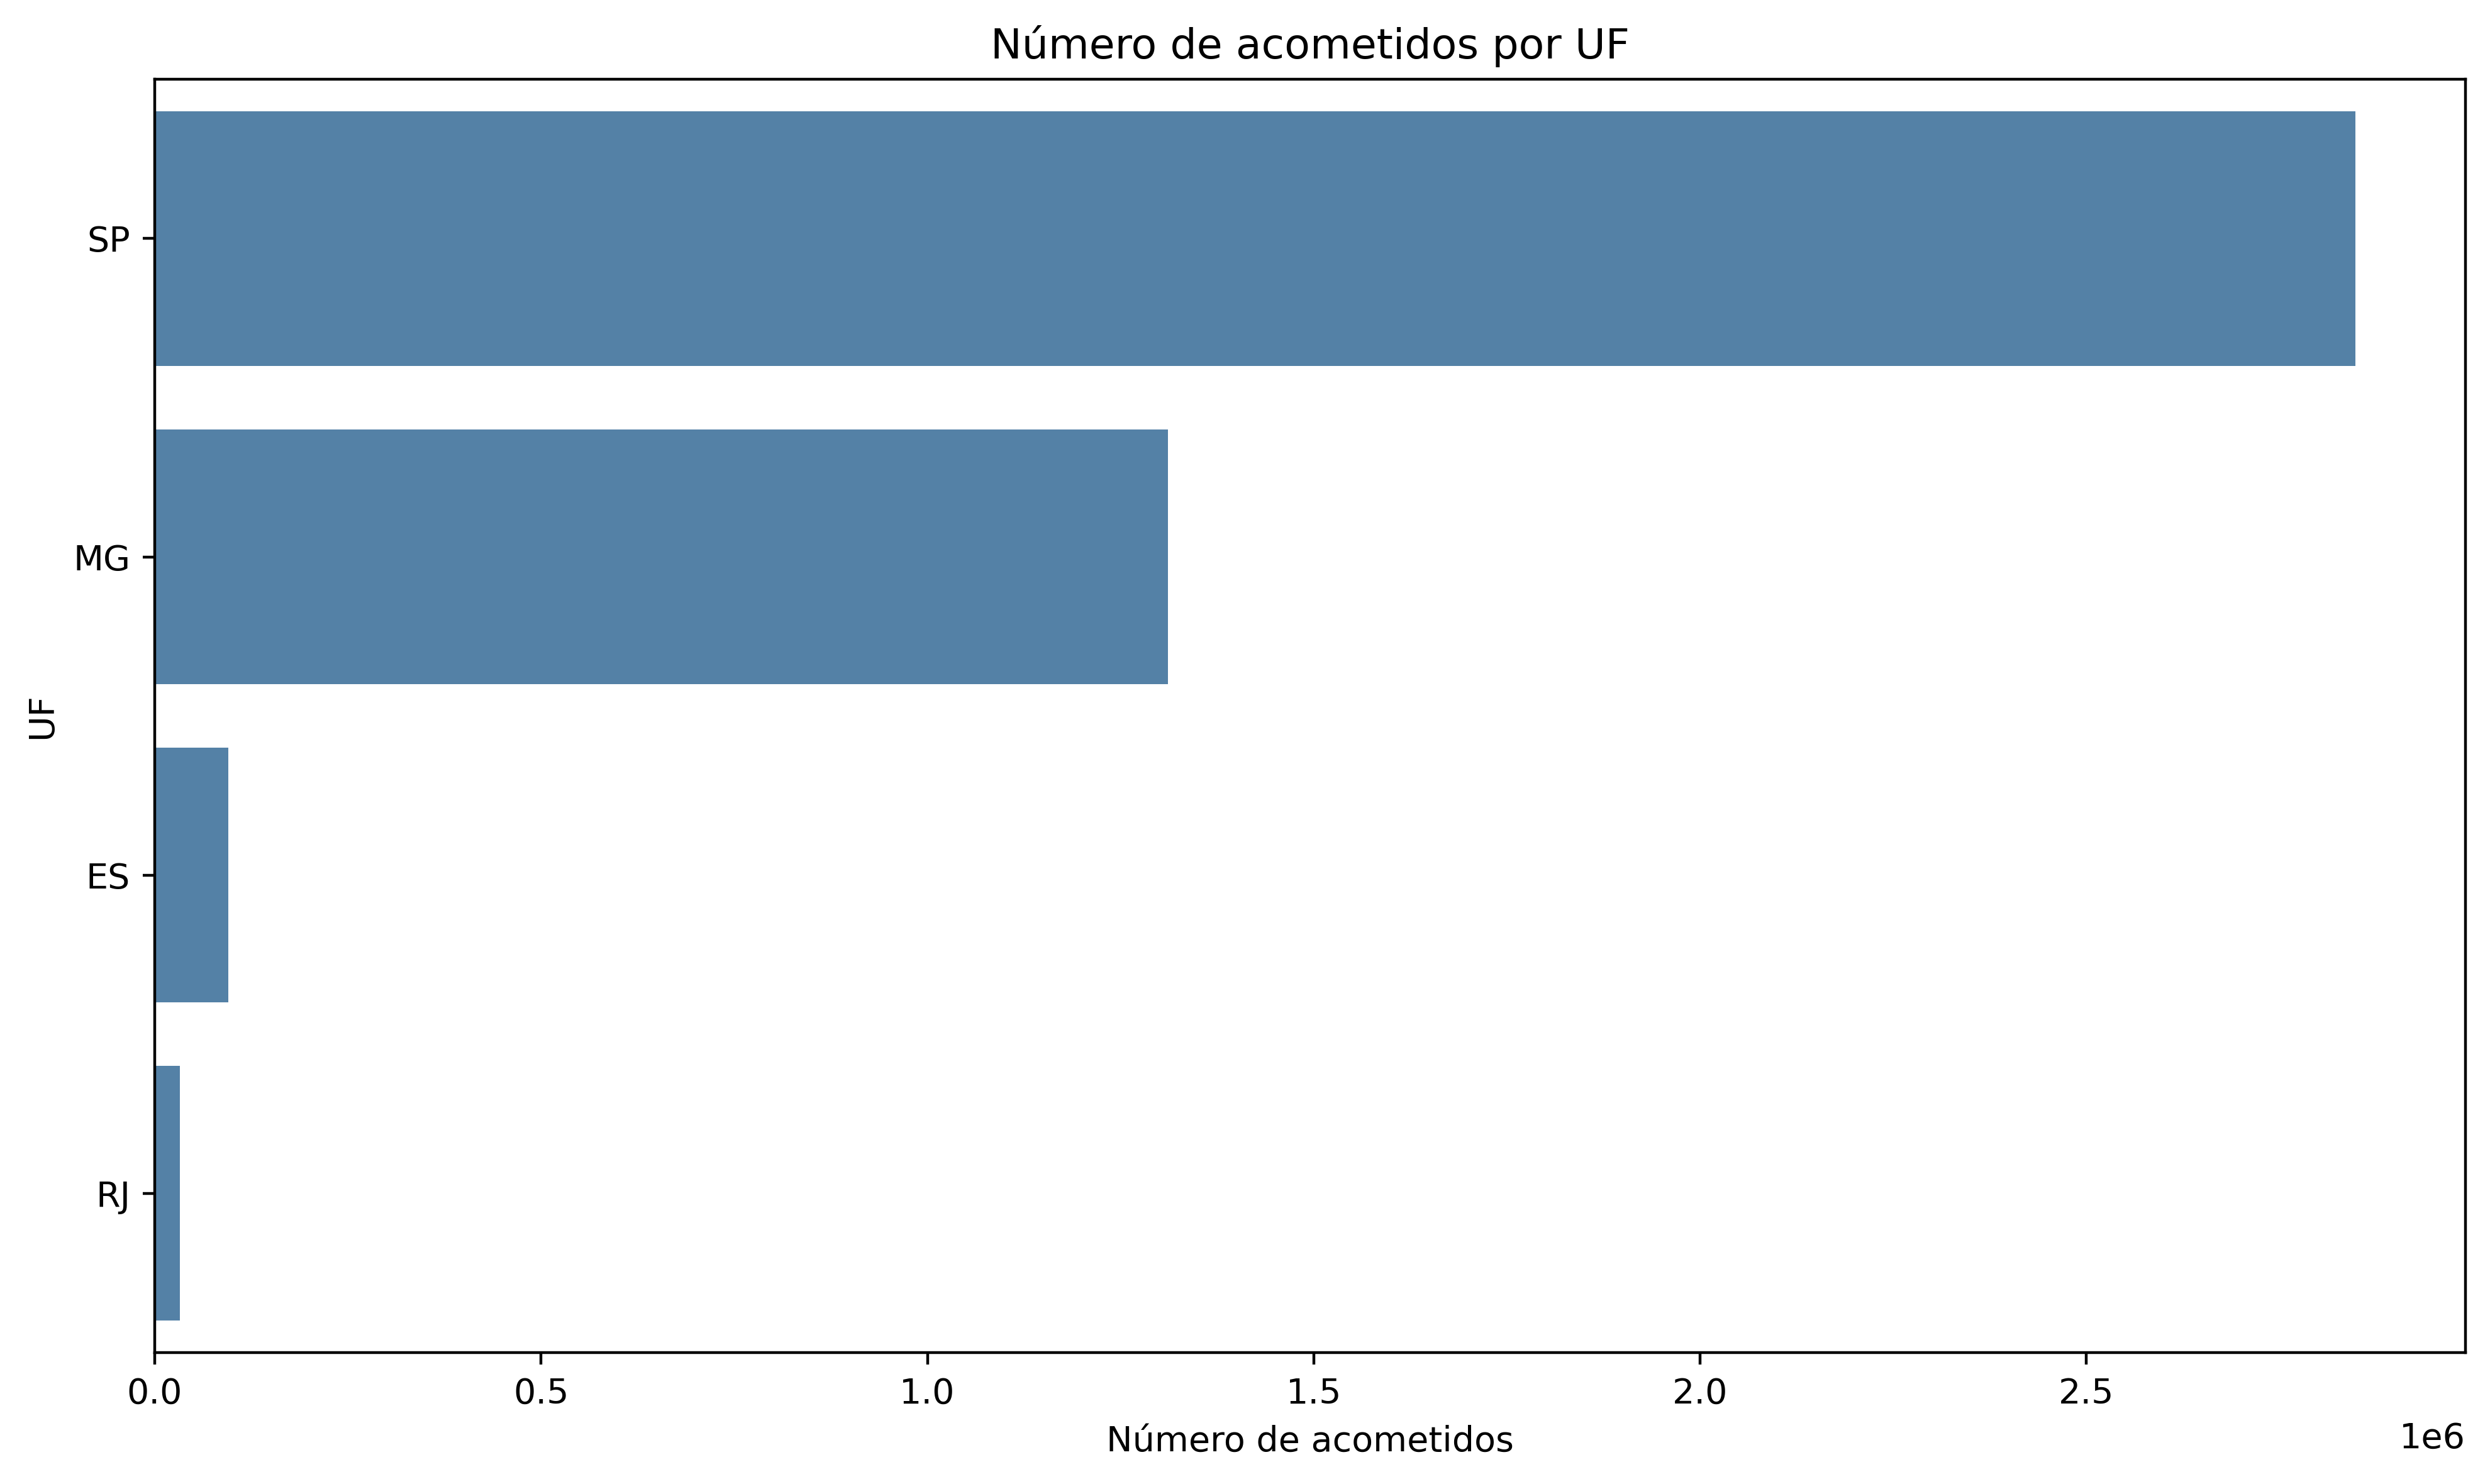

In [37]:
#realiza o ranking por estado de procedência
ranking_uf = (
    df_estat_bovino_sudeste.groupby("UF_PROCEDENCIA", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

pl.figure(figsize=(10, 6))
sns.barplot(
    data=ranking_uf,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de acometidos por UF")
pl.xlabel("Número de acometidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()

In [60]:
#criando a tabela cruzada entre estado de procedência e diagnóstico
tabela_uf_diagnostico = pd.pivot_table(
    df_estat_bovino_sudeste,
    values="NUMERO_ANIMAIS_ACOMETIDOS",
    index="UF_PROCEDENCIA",
    columns="DIAGNOSTICO",
    aggfunc="sum",
    fill_value= 0
)

tabela_uf_diagnostico

DIAGNOSTICO,aborto enzoótico das ovelhas (confirmado),aborto recente (fêmea),abscesso,abscesso (mamíferos),acrobustite,actinobacilose (ruminantes),actinomicose (já notificado),actinomicose (notificação sif),aderencias,aderência de pleura (purulenta),...,tuberculose (já notificado),tuberculose (notificação sif),tuberculose (reagente já notificado),tuberculose (reagente notificação sif),tuberculose aviária (notificação sif),tuberculose calcificada,tuberculose caseosa,uronefrose,verminose,útero com feto(s)
UF_PROCEDENCIA,,,,,,,,,,,,,,,,,,,,,
ES,0,0,45,980,0,7,2,5,0,5,...,108,33,0,0,0,0,0,0,0,0
MG,0,14,116,4355,20,7,11,251,1,126,...,365,301,20,11,1,0,0,7,24,5
RJ,0,0,0,238,0,3,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
SP,39,2,109,13615,29,9,24,33,19,182,...,1,306,0,1,0,4,1,16,0,6


In [100]:
#Analisando o ranking por estado de procedência
ranking_uf = (
    df_estat_bovino_sudeste.groupby("UF_PROCEDENCIA", as_index=False)
        ["NUMERO_ANIMAIS_ACOMETIDOS"].sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_uf

,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS
3,SP,2848023
1,MG,1310993
0,ES,95247
2,RJ,32112


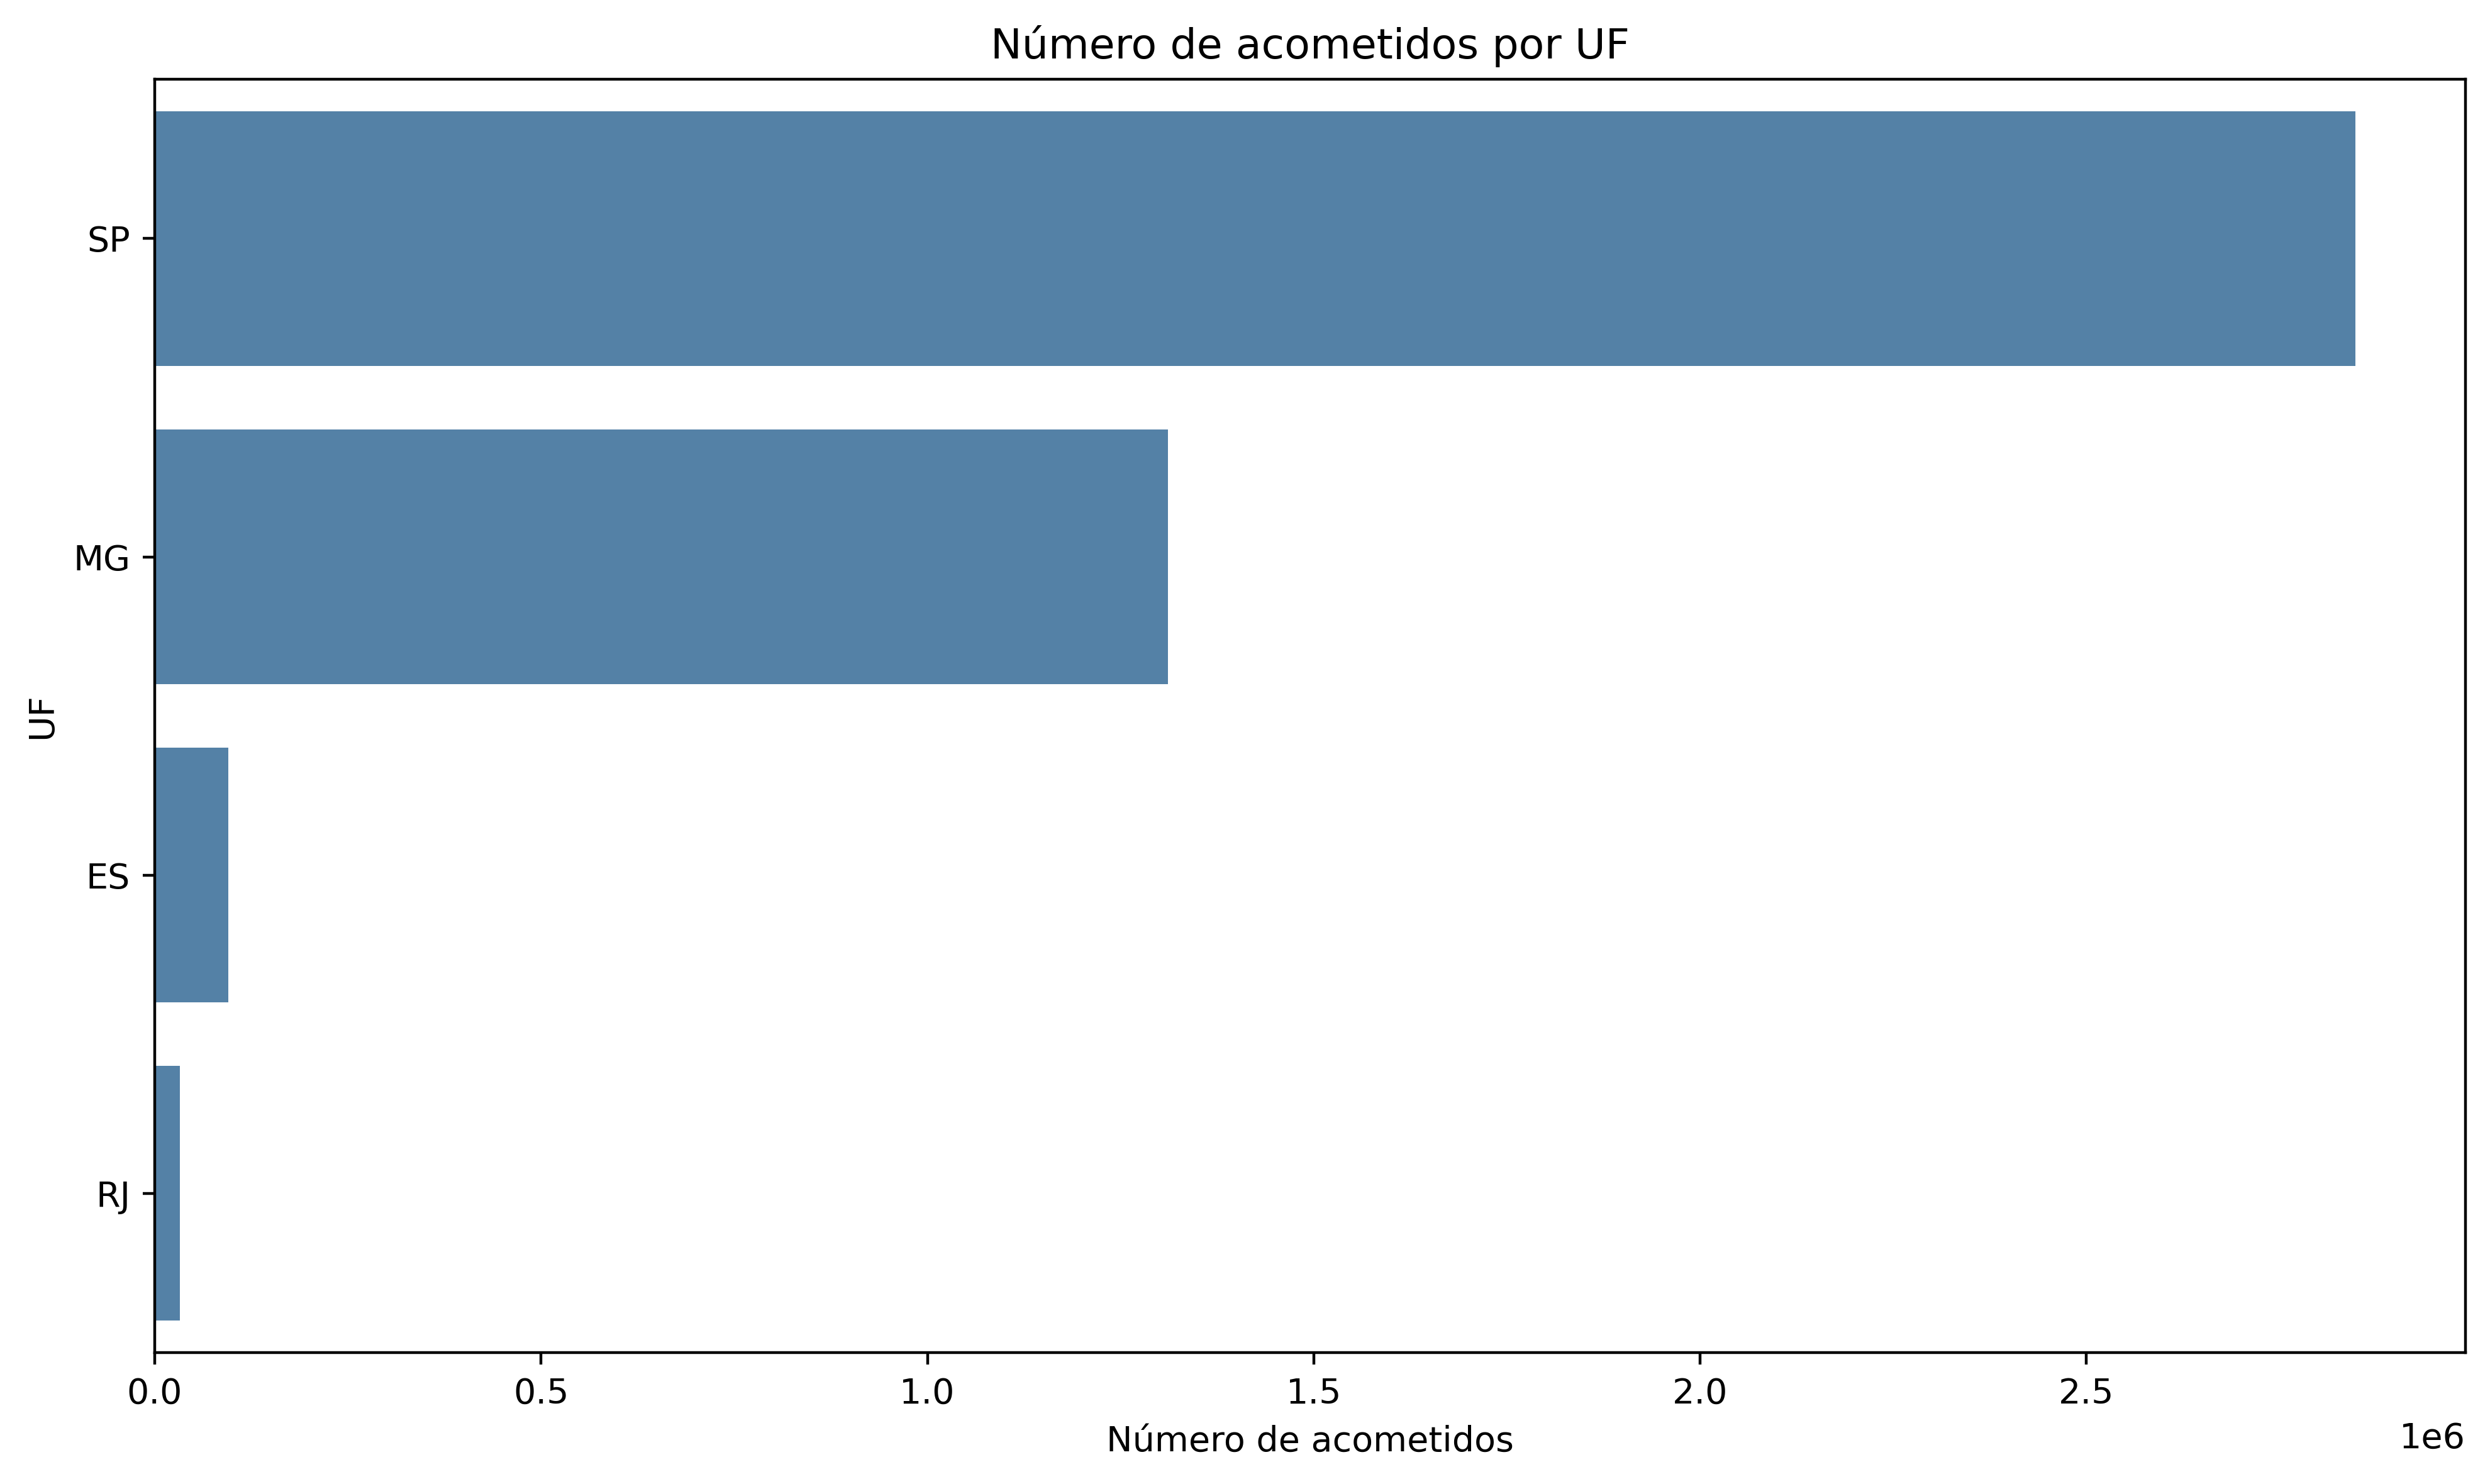

In [101]:
#Criando o gráfico de barras do número de acometidos por UF
pl.figure(figsize=(10, 6))

sns.barplot(
    data=ranking_uf,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de acometidos por UF")
pl.xlabel("Número de acometidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()

In [102]:
ranking_uf["percentual"] = (
    ranking_uf["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_uf["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_uf

,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS,percentual
3,SP,2848023,66.443627
1,MG,1310993,30.585121
0,ES,95247,2.222087
2,RJ,32112,0.749165


In [ ]:
ranking_diagnostico = (
    df_estat_bovino_sudeste.groupby("DIAGNOSTICO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"].sum().sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_diagnostico

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS
94,material especificado de risco (inutilização),2718449
14,alteração restrita,651247
48,contaminação gastrointestinal e biliar,600921
49,contaminação não gastrointestinal,98640
81,lesão inflamatória,64212
...,...,...
67,febre q (notificação sif),1
121,septicemia hemorrágica bovina (já notificado),1
55,enterotoxemia (notificação sif),1
109,pleurite,1


In [44]:
ranking_diagnostico["percentual"] = (
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_diagnostico

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
94,material especificado de risco (inutilização),2718449,63.420699
14,alteração restrita,651247,15.193421
48,contaminação gastrointestinal e biliar,600921,14.019329
49,contaminação não gastrointestinal,98640,2.301245
81,lesão inflamatória,64212,1.498049
...,...,...,...
67,febre q (notificação sif),1,0.000023
121,septicemia hemorrágica bovina (já notificado),1,0.000023
55,enterotoxemia (notificação sif),1,0.000023
109,pleurite,1,0.000023


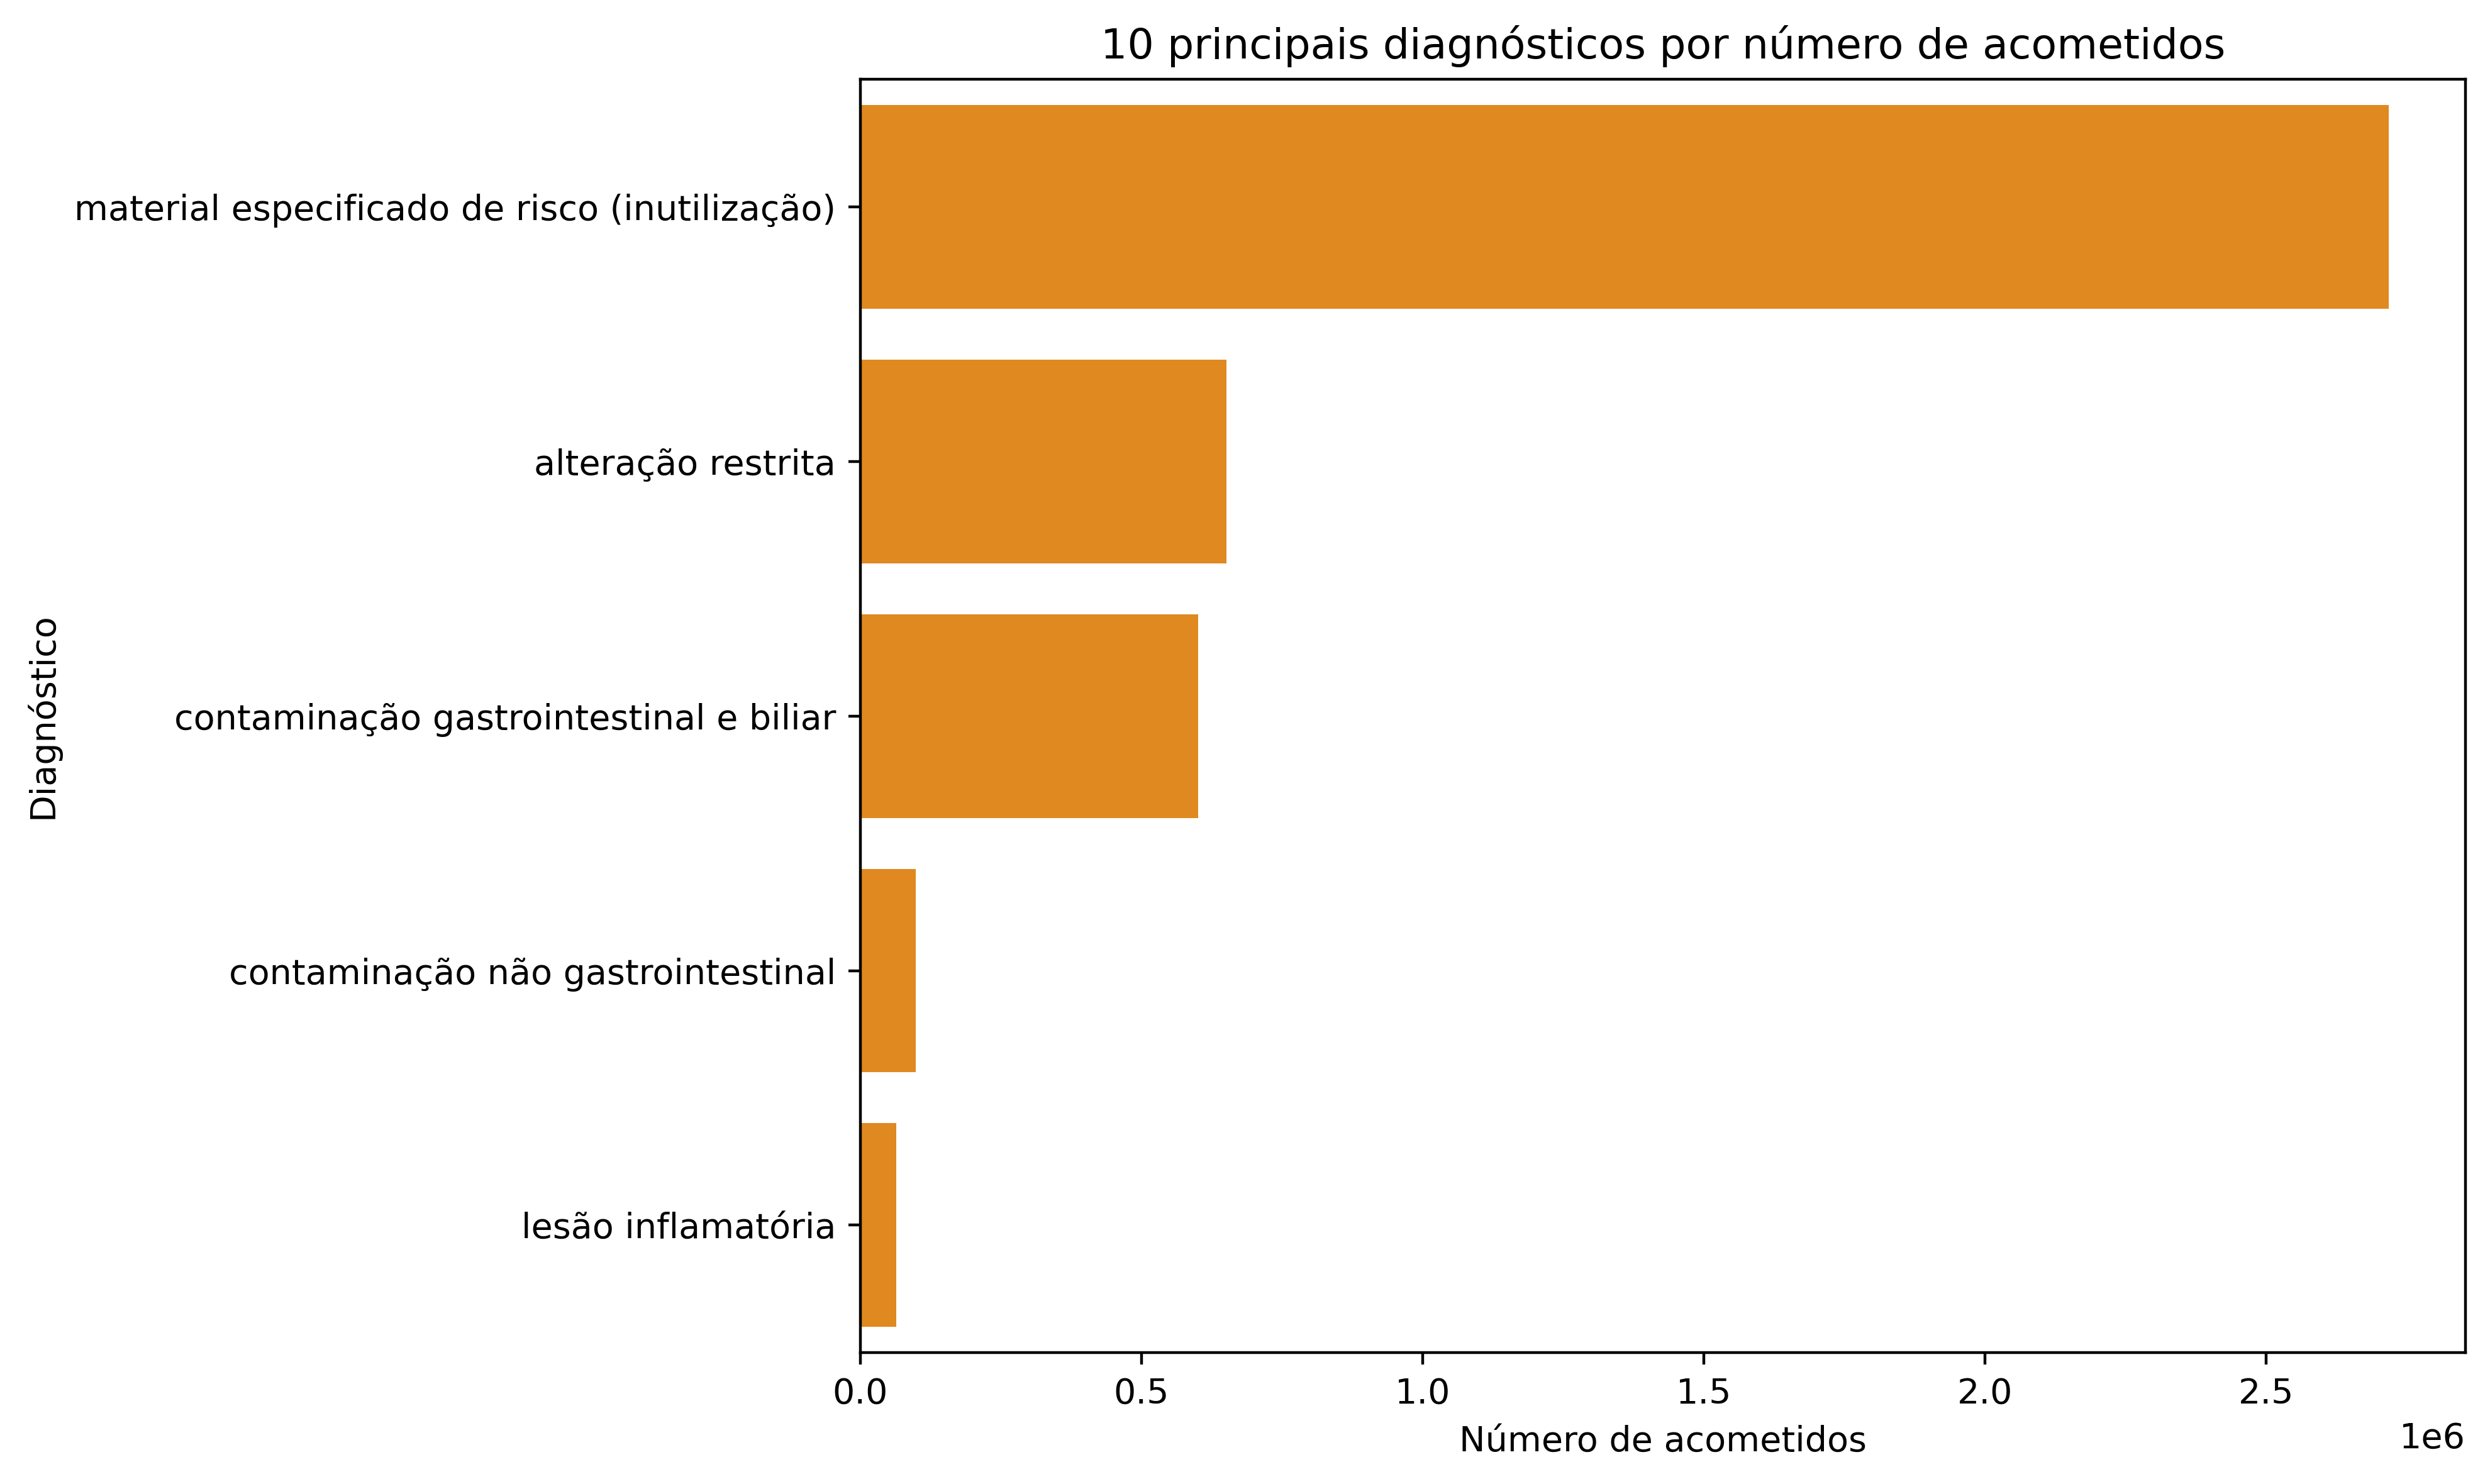

In [45]:
top10_diagnostico = ranking_diagnostico.head(5)

pl.figure(figsize=(10, 6))

sns.barplot(
    data=top10_diagnostico,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="DIAGNOSTICO",
    color="darkorange"
)

pl.title("10 principais diagnósticos por número de acometidos")
pl.xlabel("Número de acometidos")
pl.ylabel("Diagnóstico")
pl.tight_layout()
pl.show()

In [46]:
diagnostico_ano = (
    df_estat_bovino_sudeste.groupby(["ANO", "DIAGNOSTICO"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values(["ANO", "NUMERO_ANIMAIS_ACOMETIDOS"], ascending=[True, False])
)

diagnostico_ano

,ANO,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS
75,2021,material especificado de risco (inutilização),528194
39,2021,contaminação gastrointestinal e biliar,90711
12,2021,alteração restrita,54305
64,2021,lesão inflamatória,18665
40,2021,contaminação não gastrointestinal,10569
...,...,...,...
427,2026,hipotermia (detectada no ante mortem),2
417,2026,edema generalizado,1
423,2026,febre q (notificação sif),1
426,2026,gordura amarela,1


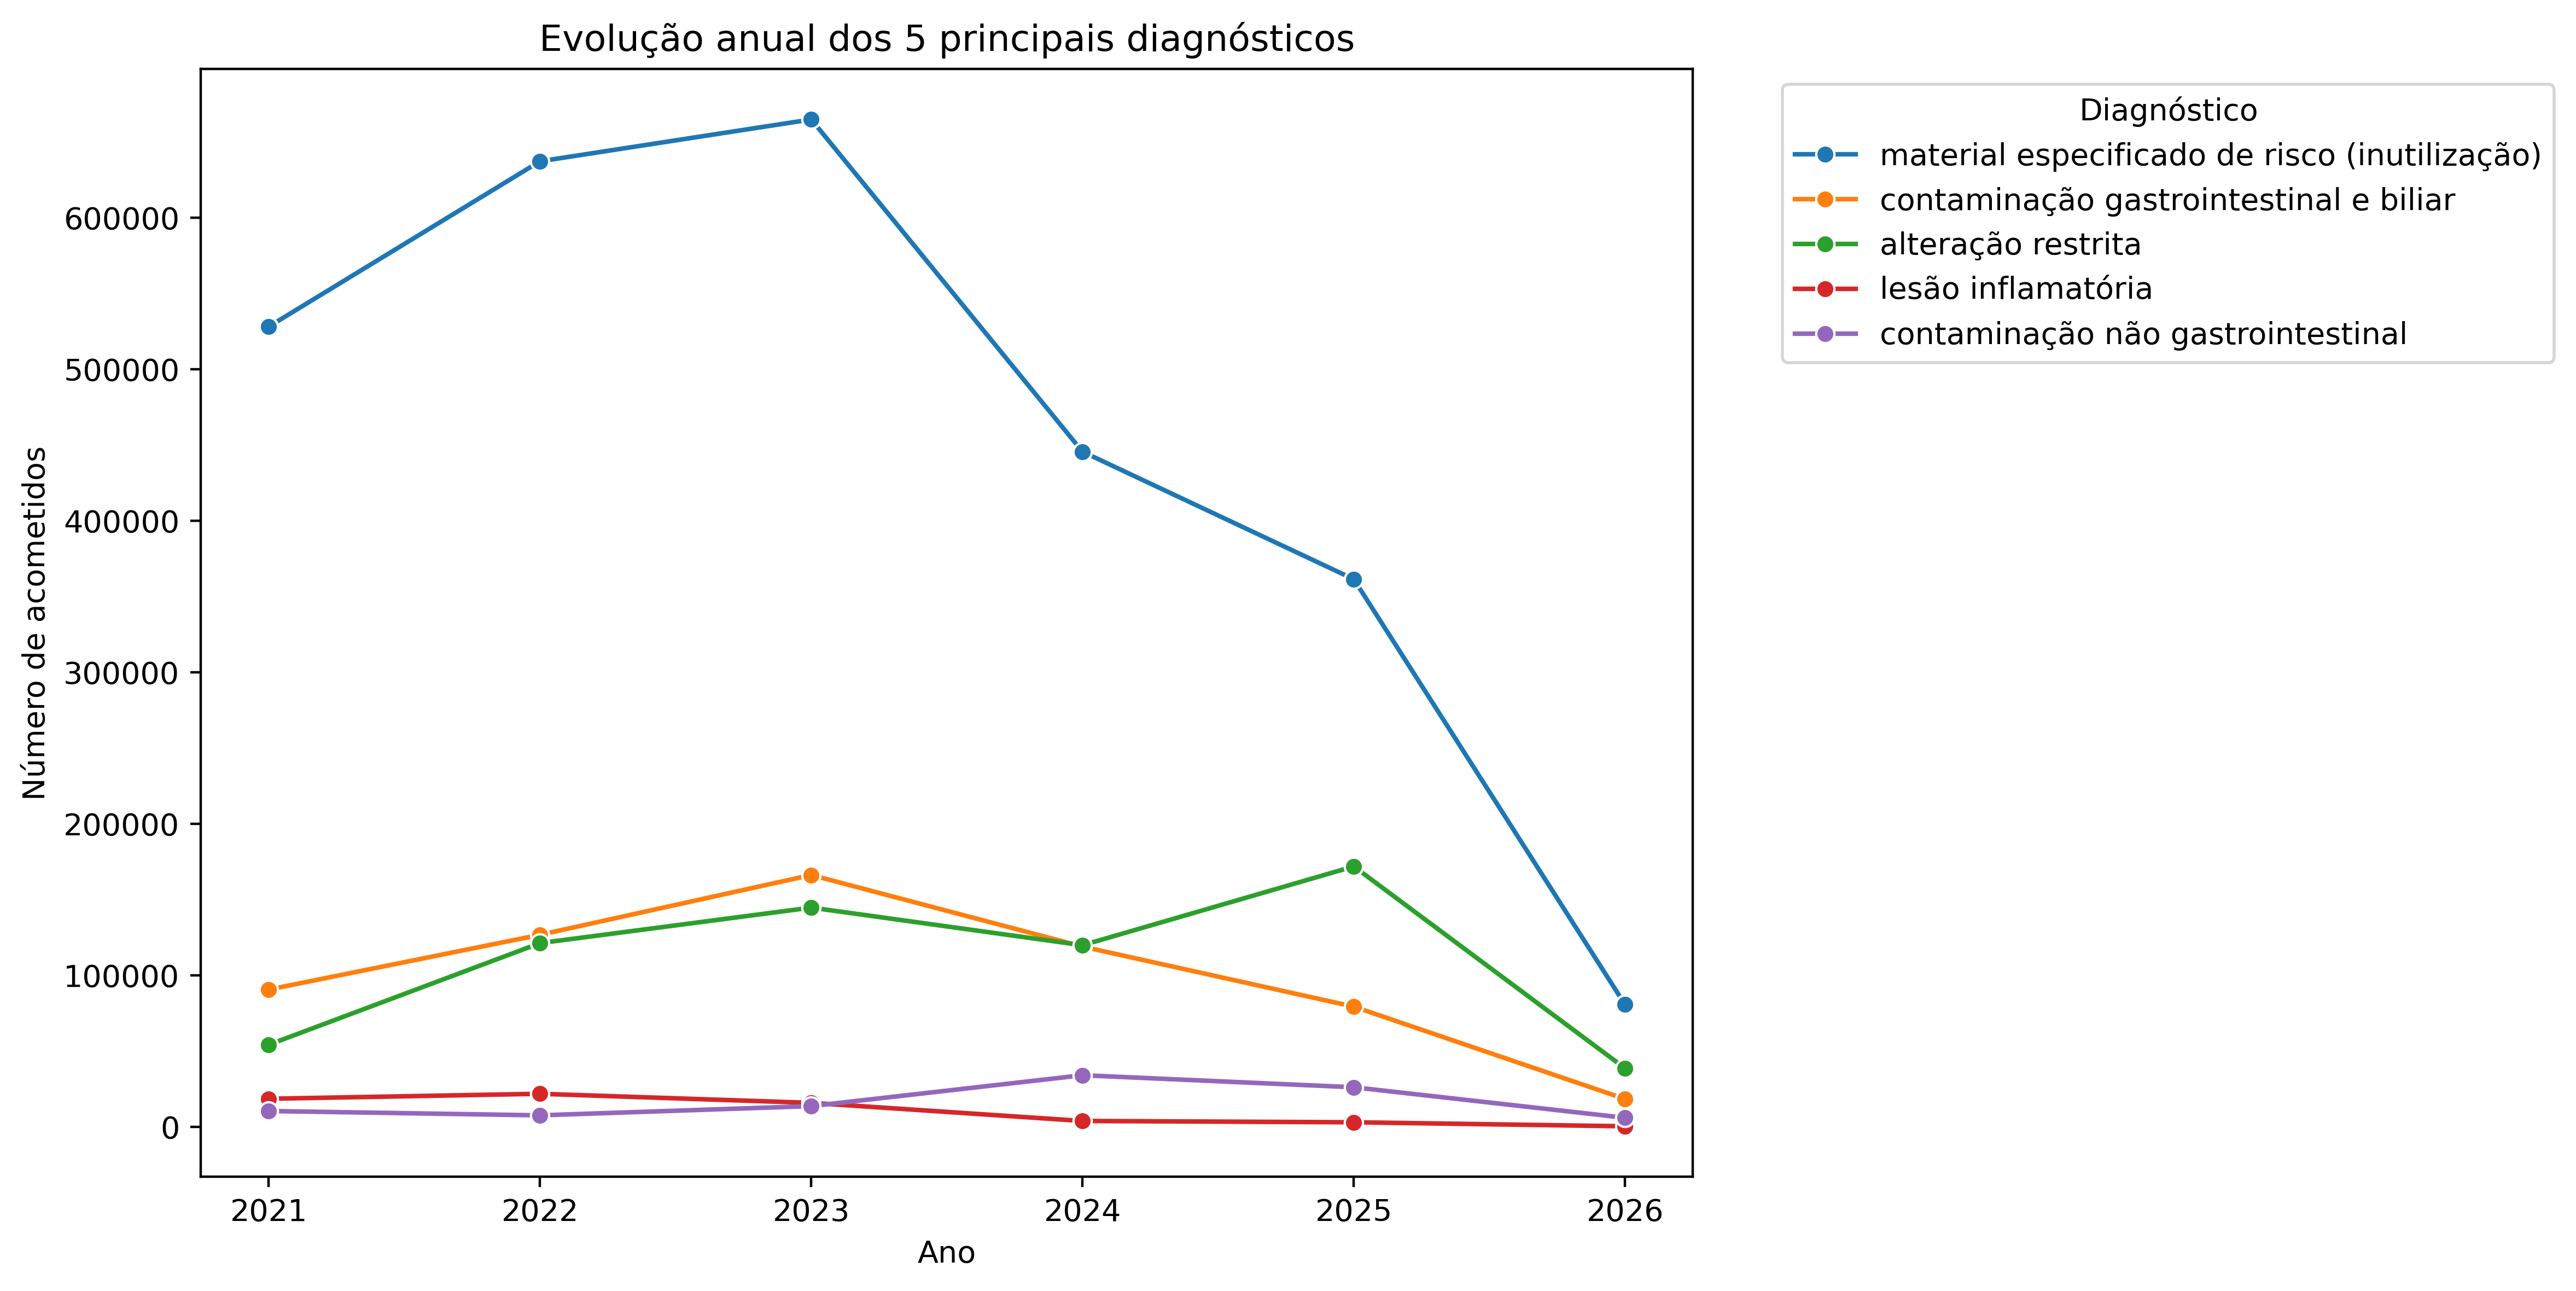

In [47]:
top5_diag = (
    df_estat_bovino_sudeste.groupby("DIAGNOSTICO")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values(ascending=False)
      .head(5)
      .index
)

diagnostico_ano_top5 = diagnostico_ano[
    diagnostico_ano["DIAGNOSTICO"].isin(top5_diag)
]

pl.figure(figsize=(12, 6))

sns.lineplot(
    data=diagnostico_ano_top5,
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    hue="DIAGNOSTICO",
    marker="o"
)

pl.title("Evolução anual dos 5 principais diagnósticos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.xticks(sorted(diagnostico_ano_top5["ANO"].unique()))
pl.legend(title="Diagnóstico", bbox_to_anchor=(1.05, 1), loc="upper left")
pl.tight_layout()
pl.show()

In [48]:
media = df_estat_bovino_sudeste["NUMERO_ANIMAIS_ACOMETIDOS"].mean()
mediana = df_estat_bovino_sudeste["NUMERO_ANIMAIS_ACOMETIDOS"].median()
desvio_padrao = df_estat_bovino_sudeste["NUMERO_ANIMAIS_ACOMETIDOS"].std()
variancia = df_estat_bovino_sudeste["NUMERO_ANIMAIS_ACOMETIDOS"].var()
coef_variacao = desvio_padrao / media * 100
print(f"Média: {media:.2f}")
print(f"Mediana: {mediana:.2f}")
print(f"Desvio Padrão: {desvio_padrao:.2f}")
print(f"Variância: {variancia:.2f}")
print(f"Coeficiente de Variação: {coef_variacao:.2f}%")

Média: 661.78
Mediana: 6.00
Desvio Padrão: 3434.57
Variância: 11796291.83
Coeficiente de Variação: 518.99%


In [49]:
assimetria = df_estat_bovino_sudeste["NUMERO_ANIMAIS_ACOMETIDOS"].skew()
curtose = df_estat_bovino_sudeste["NUMERO_ANIMAIS_ACOMETIDOS"].kurtosis()
print(f"Assimetria: {assimetria:.2f}")
print(f"Curtose: {curtose:.2f}")

Assimetria: 7.59
Curtose: 64.40


In [50]:
minimo = df_estat_bovino_sudeste["NUMERO_ANIMAIS_ACOMETIDOS"].min()
maximo = df_estat_bovino_sudeste["NUMERO_ANIMAIS_ACOMETIDOS"].max()
amplitude = maximo - minimo

q1 = df_estat_bovino_sudeste["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.25)
q3 = df_estat_bovino_sudeste["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.75)
iqr = q3 - q1
print(f"Valor mínimo: {minimo}")
print(f"Valor máximo: {maximo}")
print(f"Amplitude: {amplitude}")
print(f"Q1: {q1}")
print(f"Q3: {q3}")
print(f"IQR: {iqr}")

Valor mínimo: 1
Valor máximo: 45077
Amplitude: 45076
Q1: 1.0
Q3: 61.0
IQR: 60.0


In [51]:
q1 = df_estat_bovino_sudeste["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.25)
q3 = df_estat_bovino_sudeste["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.75)
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = df_estat_bovino_sudeste[
    (df_estat_bovino_sudeste["NUMERO_ANIMAIS_ACOMETIDOS"] < limite_inferior) |
    (df_estat_bovino_sudeste["NUMERO_ANIMAIS_ACOMETIDOS"] > limite_superior)
]

print(f"Outliers encontrados:\n{outliers}")

Outliers encontrados:
        MES_ANO UF_PROCEDENCIA ESPECIE  \
0    2021-12-01             SP  Bovino   
1    2023-09-01             SP  Bovino   
2    2021-08-01             SP  Bovino   
3    2023-08-01             SP  Bovino   
4    2022-09-01             SP  Bovino   
...         ...            ...     ...   
1091 2023-03-01             SP  Bovino   
1092 2022-07-01             SP  Bovino   
1093 2021-08-01             MG  Bovino   
1094 2024-12-01             RJ  Bovino   
1095 2022-10-01             SP  Bovino   

                                        DIAGNOSTICO  \
0     material especificado de risco (inutilização)   
1     material especificado de risco (inutilização)   
2     material especificado de risco (inutilização)   
3     material especificado de risco (inutilização)   
4     material especificado de risco (inutilização)   
...                                             ...   
1091                            cisticercose bovina   
1092              contaminação nã

In [52]:
desc_por_uf = (
      df_estat_bovino_sudeste.groupby("UF_PROCEDENCIA")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .agg(["count", "sum", "mean", "median", "std", "min", "max"])
      .sort_values("sum", ascending=False)
)

desc_por_uf

,count,sum,mean,median,std,min,max
UF_PROCEDENCIA,,,,,,,
SP,2244,2848023,1269.172460,10.0,5077.188725,1,45077
MG,2634,1310993,497.719438,3.0,2546.814100,1,30669
ES,1057,95247,90.110691,7.0,216.536765,1,1667
RJ,542,32112,59.247232,10.0,88.809240,1,455


In [53]:
desc_por_diagnostico = (
    df_estat_bovino_sudeste.groupby("DIAGNOSTICO")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .agg(["count", "sum", "mean", "median", "std", "min", "max"])
      .sort_values("sum", ascending=False)
)
desc_por_diagnostico

,count,sum,mean,median,std,min,max
DIAGNOSTICO,,,,,,,
material especificado de risco (inutilização),248,2718449,10961.487903,1836.0,12803.251065,1,45077
alteração restrita,247,651247,2636.627530,881.0,3683.350793,12,14992
contaminação gastrointestinal e biliar,247,600921,2432.878543,908.0,2992.928779,1,12259
contaminação não gastrointestinal,233,98640,423.347639,113.0,607.794809,1,3820
lesão inflamatória,213,64212,301.464789,128.0,455.690948,1,2188
...,...,...,...,...,...,...,...
febre q (notificação sif),1,1,1.000000,1.0,NaN,1,1
septicemia hemorrágica bovina (já notificado),1,1,1.000000,1.0,NaN,1,1
enterotoxemia (notificação sif),1,1,1.000000,1.0,NaN,1,1


In [54]:
ranking_diagnostico = (
    df_estat_bovino_sudeste.groupby("DIAGNOSTICO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_diagnostico["percentual"] = (
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_diagnostico["percentual_acumulado"] = ranking_diagnostico["percentual"].cumsum()

ranking_diagnostico

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual,percentual_acumulado
94,material especificado de risco (inutilização),2718449,63.420699,63.420699
14,alteração restrita,651247,15.193421,78.614120
48,contaminação gastrointestinal e biliar,600921,14.019329,92.633449
49,contaminação não gastrointestinal,98640,2.301245,94.934694
81,lesão inflamatória,64212,1.498049,96.432743
...,...,...,...,...
67,febre q (notificação sif),1,0.000023,99.999907
121,septicemia hemorrágica bovina (já notificado),1,0.000023,99.999930
55,enterotoxemia (notificação sif),1,0.000023,99.999953
109,pleurite,1,0.000023,99.999977


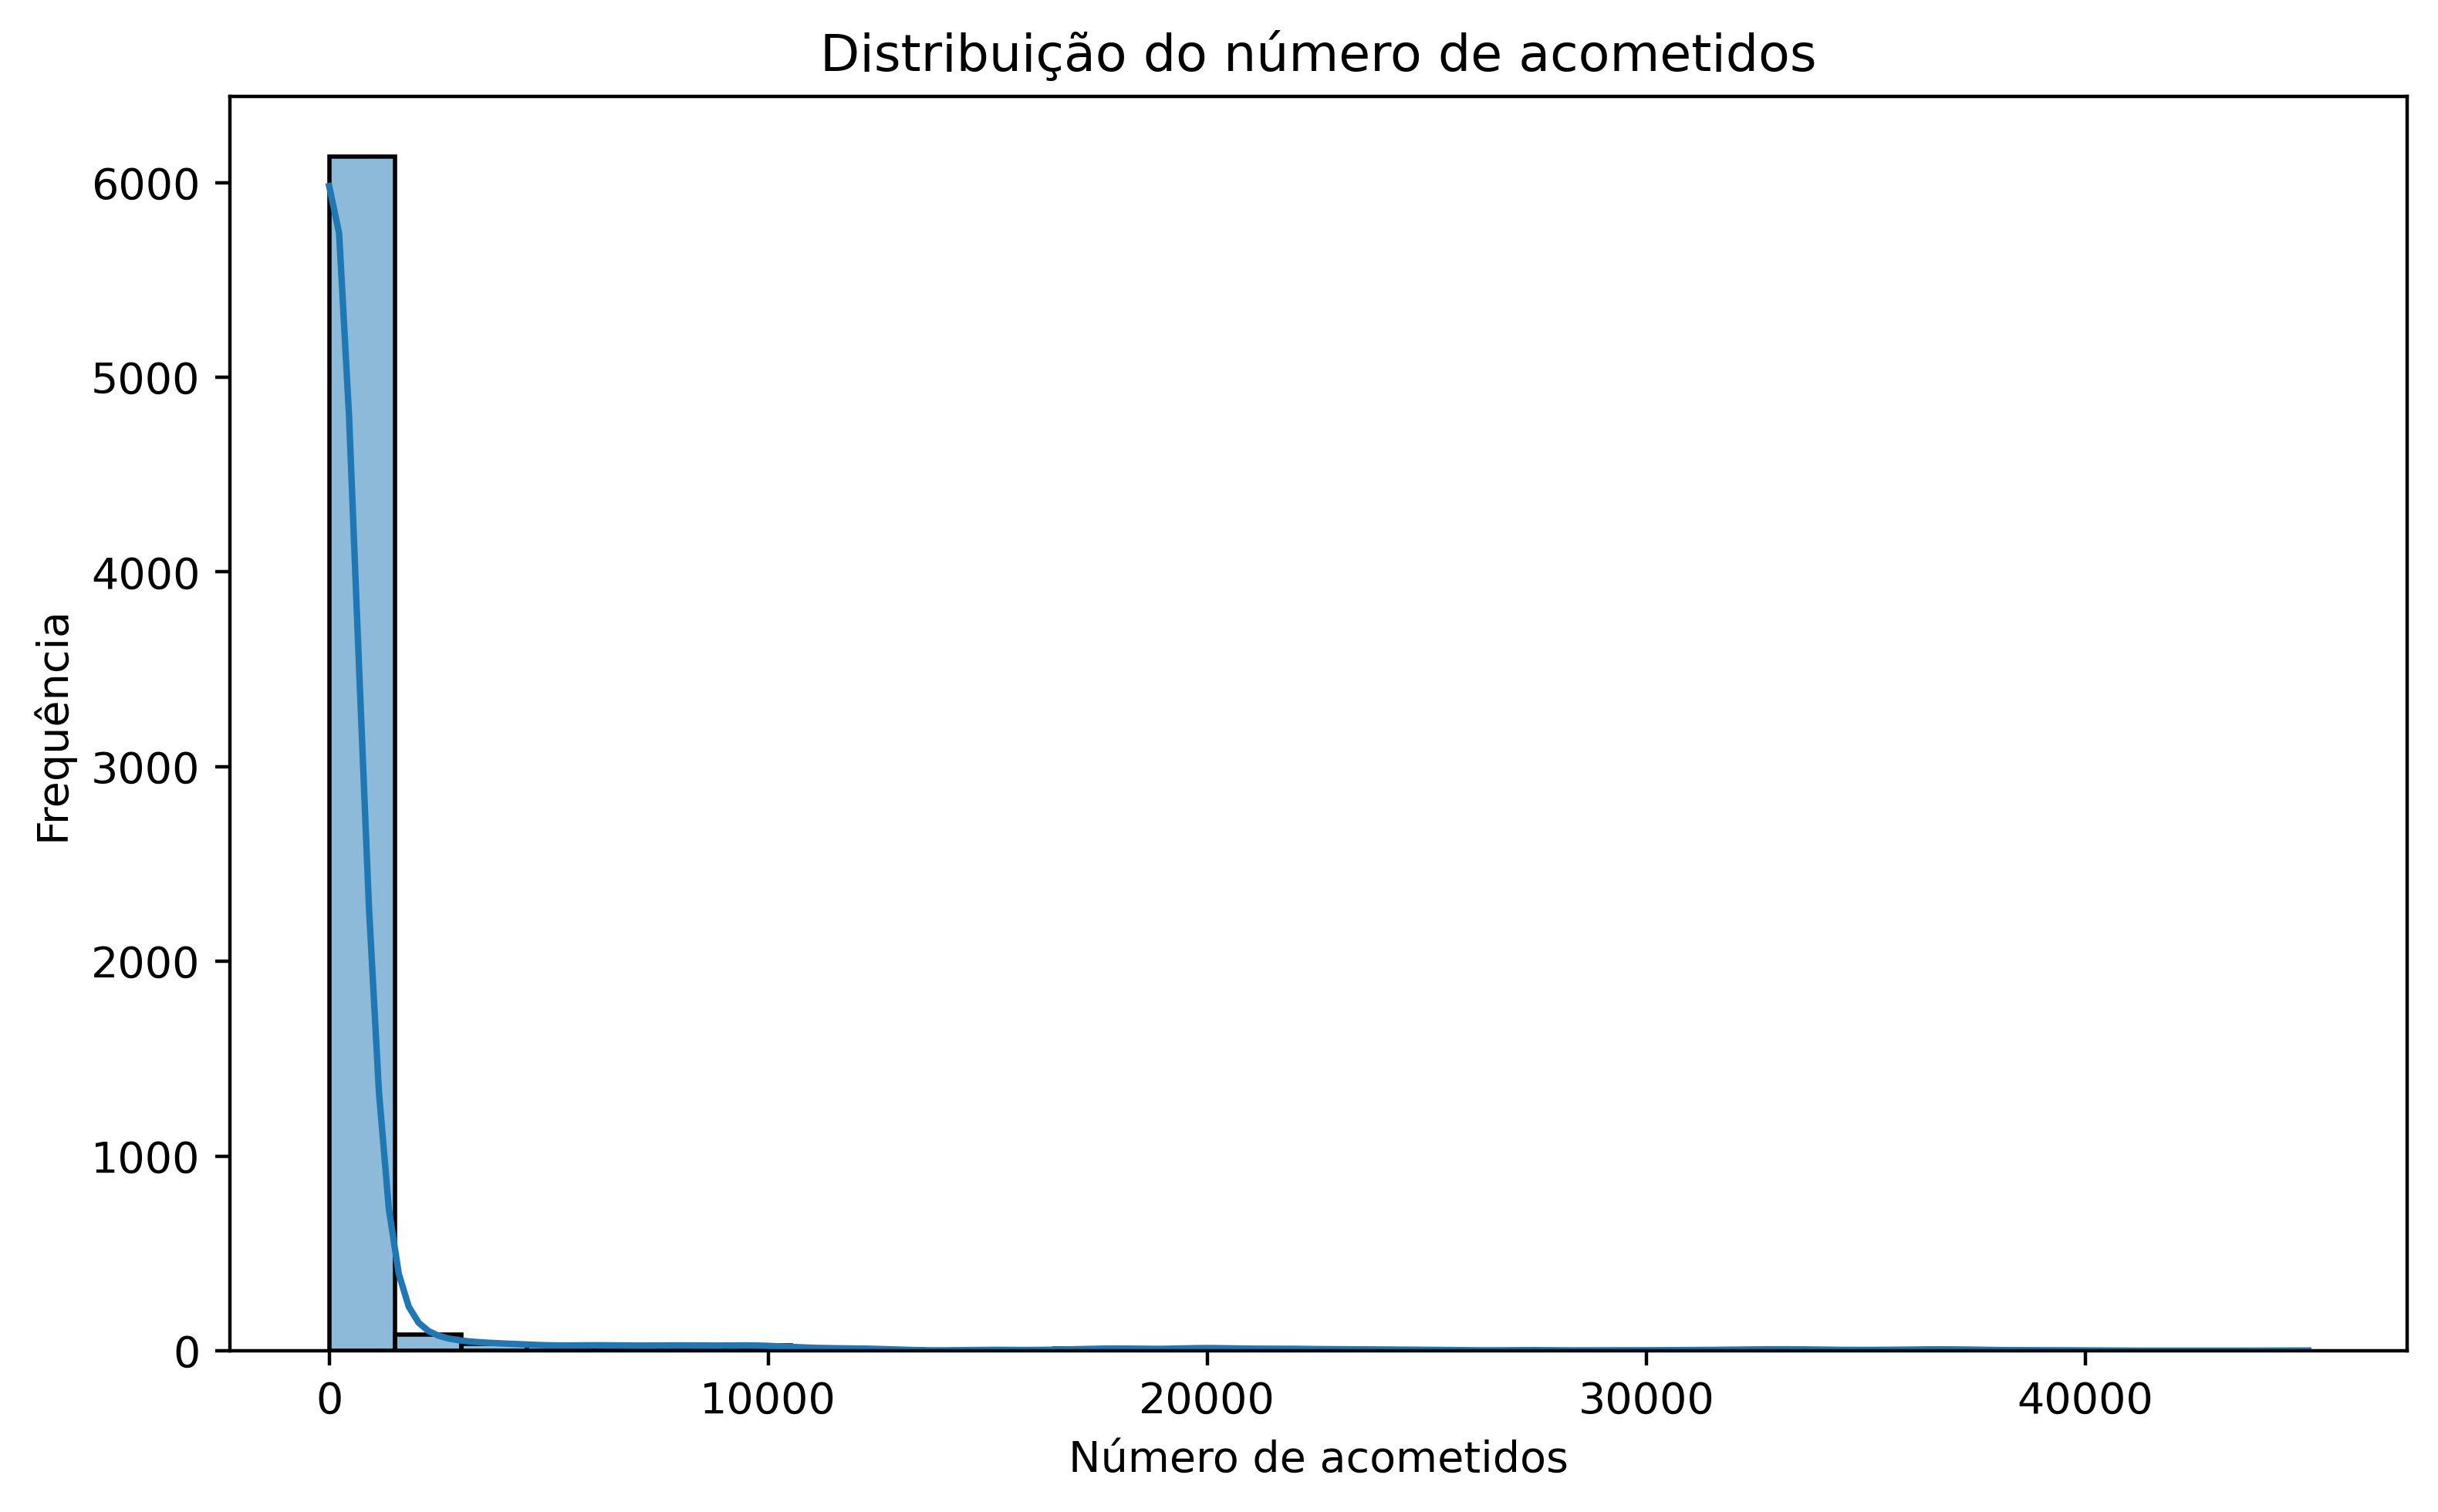

In [55]:
pl.figure(figsize=(8, 5))

sns.histplot(
    data=df_estat_bovino_sudeste,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    bins=30,
    kde=True
)

pl.title("Distribuição do número de acometidos")
pl.xlabel("Número de acometidos")
pl.ylabel("Frequência")
pl.tight_layout()
pl.show()


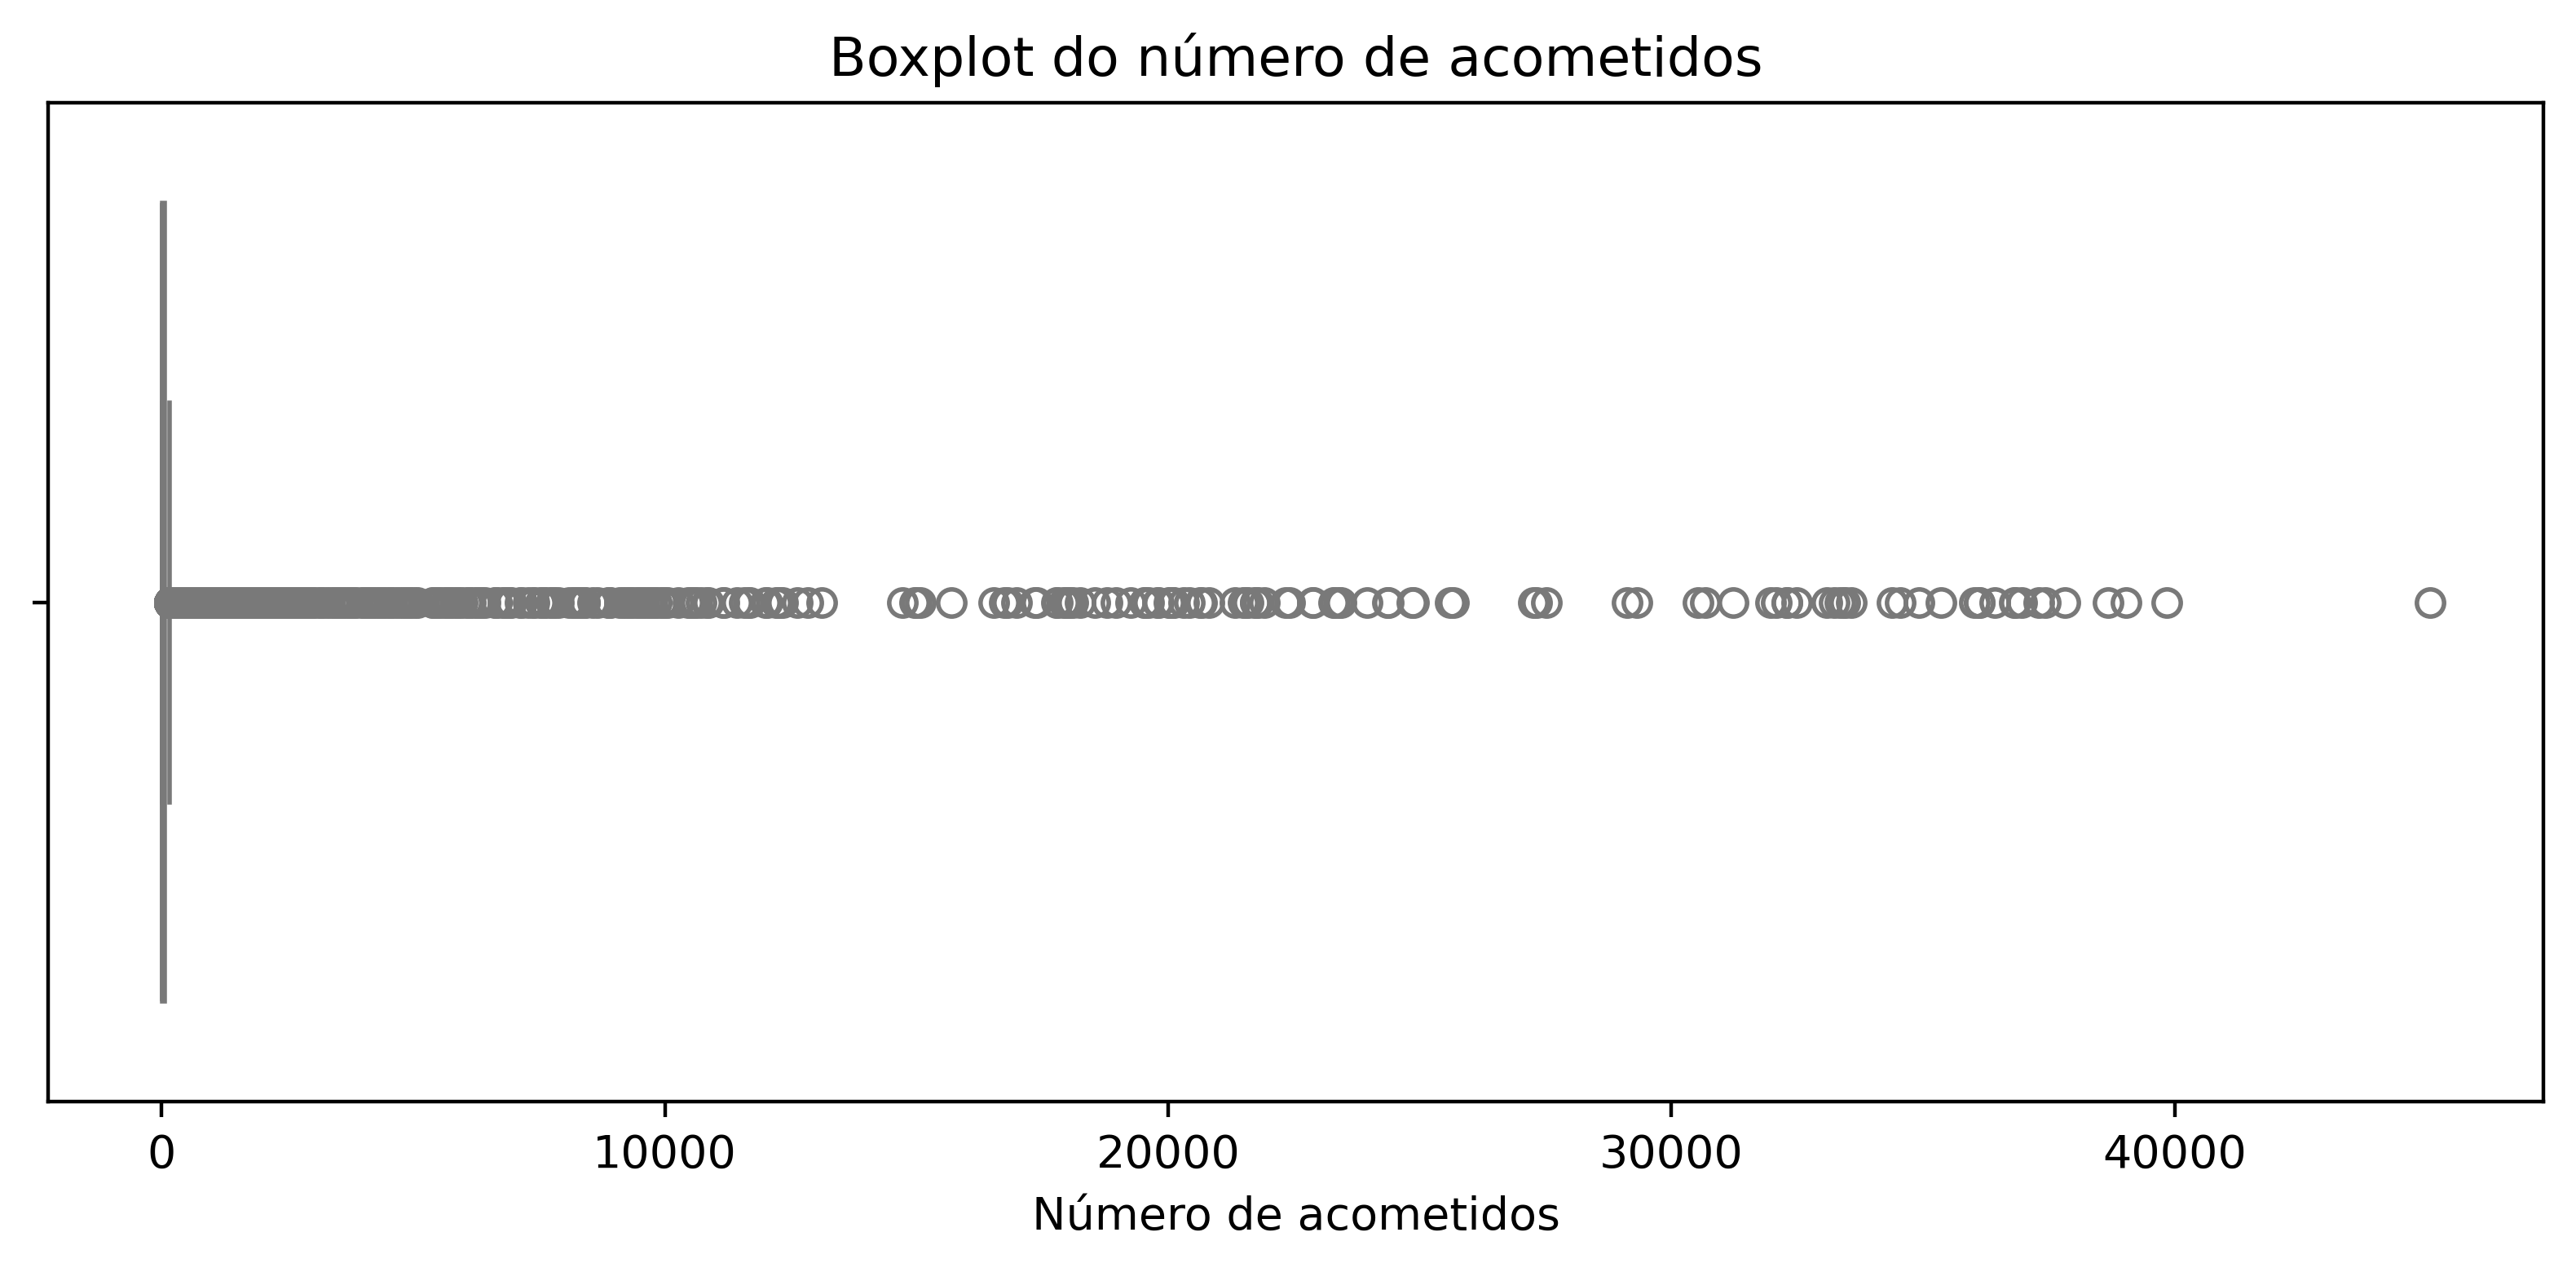

In [56]:
pl.figure(figsize=(8, 4))

sns.boxplot(
    data=df_estat_bovino_sudeste,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    color="lightblue"
)

pl.title("Boxplot do número de acometidos")
pl.xlabel("Número de acometidos")
pl.tight_layout()
pl.show()

Estatística bovinos doenças infecciosas

In [87]:
df_estat_bovino_se_infecto.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1248 entries, 0 to 1247
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   MES_ANO                    1248 non-null   object
 1   UF_PROCEDENCIA             1248 non-null   object
 2   ESPECIE                    1248 non-null   object
 3   DIAGNOSTICO                1248 non-null   object
 4   NUMERO_ANIMAIS_ACOMETIDOS  1248 non-null   int64 
dtypes: int64(1), object(4)
memory usage: 48.9+ KB


In [88]:
df_estat_bovino_se_infecto.describe()

,NUMERO_ANIMAIS_ACOMETIDOS
count,1248.000000
mean,21.071314
std,64.022855
min,1.000000
25%,1.000000
50%,3.000000
75%,10.000000
max,682.000000


In [89]:
#adequando o formato da coluna de data para extrair o ano
df_estat_bovino_se_infecto["MES_ANO"] = pd.to_datetime(df_estat_bovino_se_infecto["MES_ANO"], format="%m/%Y", errors='coerce')
df_estat_bovino_se_infecto["ANO"] = df_estat_bovino_se_infecto["MES_ANO"].dt.year
print(df_estat_bovino_se_infecto.head(10))

     MES_ANO UF_PROCEDENCIA ESPECIE           DIAGNOSTICO  \
0 2023-06-01             SP  Bovino  abscesso (mamíferos)   
1 2023-05-01             SP  Bovino  abscesso (mamíferos)   
2 2023-04-01             SP  Bovino  abscesso (mamíferos)   
3 2023-07-01             SP  Bovino  abscesso (mamíferos)   
4 2021-11-01             SP  Bovino  abscesso (mamíferos)   
5 2022-04-01             SP  Bovino  abscesso (mamíferos)   
6 2021-11-01             MG  Bovino  abscesso (mamíferos)   
7 2021-08-01             SP  Bovino  abscesso (mamíferos)   
8 2021-07-01             SP  Bovino  abscesso (mamíferos)   
9 2021-12-01             SP  Bovino  abscesso (mamíferos)   

   NUMERO_ANIMAIS_ACOMETIDOS   ANO  
0                        682  2023  
1                        575  2023  
2                        480  2023  
3                        460  2023  
4                        428  2021  
5                        422  2022  
6                        422  2021  
7                        417  20

In [90]:
#Realizando o resumo por ano, estado de procedência e diagnóstico
variaveis = ["ANO","UF_PROCEDENCIA", "DIAGNOSTICO"]

for var in variaveis:
    resumo = (
        df_estat_bovino_se_infecto.groupby(var, as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
          .sum()
          .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
    )
    
    resumo["percentual"] = (
        resumo["NUMERO_ANIMAIS_ACOMETIDOS"] / resumo["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
    )
    
    print(f"\nResumo por {var}")
    display(resumo.head(20))


Resumo por ANO


,ANO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
0,2021,8278,31.478876
2,2023,7584,28.839792
1,2022,6017,22.880937
3,2024,1969,7.487546
4,2025,1952,7.422900
5,2026,497,1.889949



Resumo por UF_PROCEDENCIA


,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS,percentual
3,SP,16908,64.296308
1,MG,7642,29.060349
0,ES,1478,5.620413
2,RJ,269,1.022930



Resumo por DIAGNOSTICO


,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
1,abscesso (mamíferos),19188,72.966498
18,lesões tuberculósicas,2472,9.400312
38,síndrome hemorrágica (suspeito),893,3.395825
42,tuberculose (notificação sif),640,2.433738
35,septicemia,632,2.403316
7,bronquite,559,2.125718
41,tuberculose (já notificado),474,1.802487
5,actinomicose (notificação sif),289,1.098985
0,abscesso,270,1.026733
22,linfadenite caseosa (notificação sif),251,0.954481


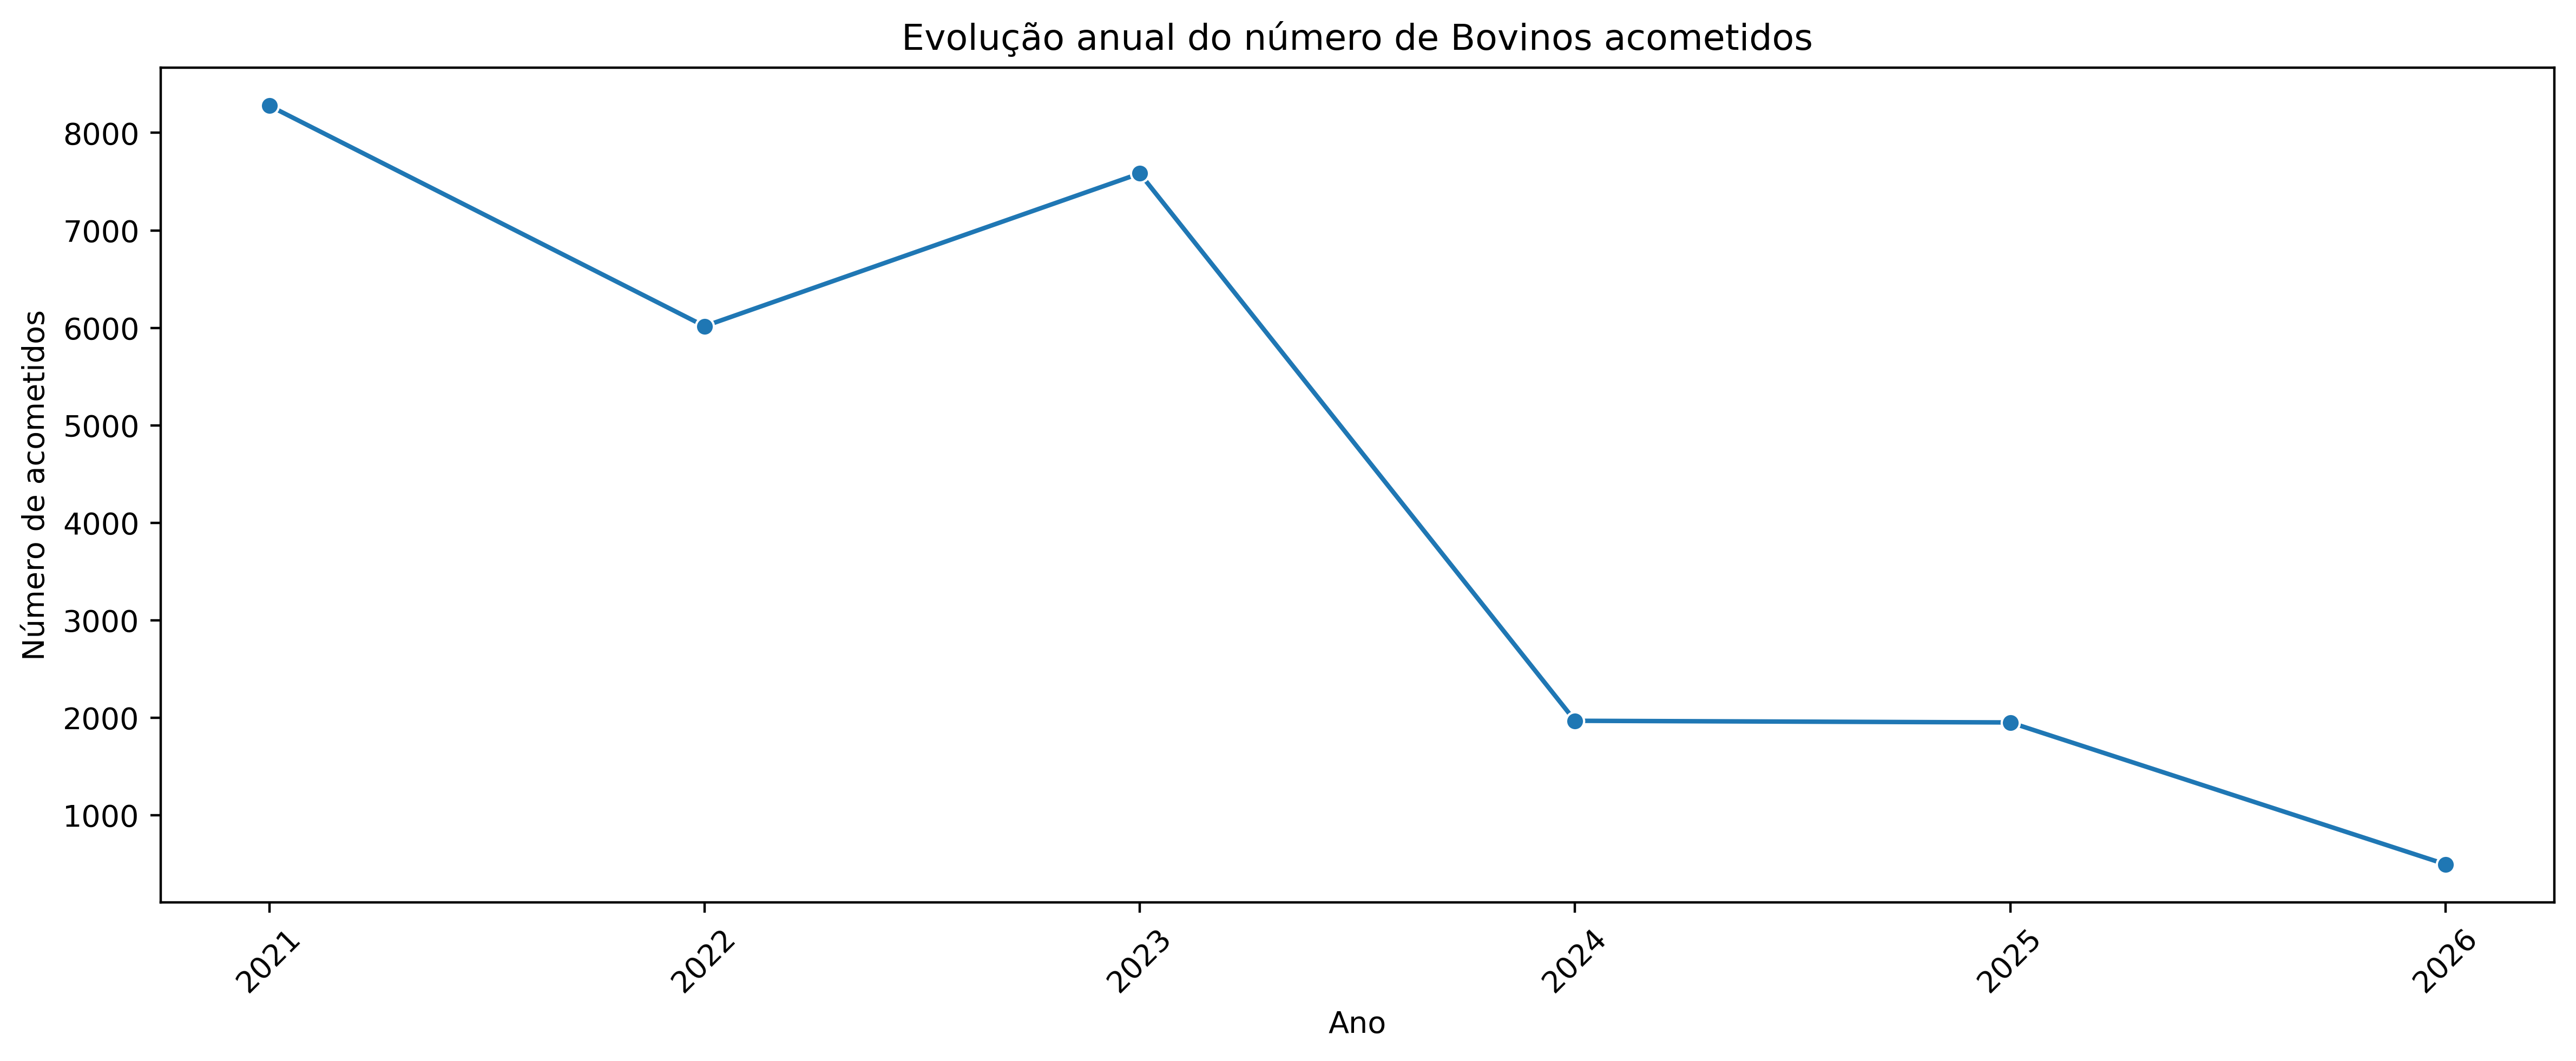

In [91]:
#criando a série anual do número de acometidos por ano
serie_anual = (
   df_estat_bovino_se_infecto.groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("ANO")
)

pl.figure(figsize=(12, 5))
sns.lineplot(
    data=serie_anual,
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    marker="o"
)

pl.title("Evolução anual do número de Bovinos acometidos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.xticks(rotation=45)
pl.tight_layout()
pl.show()

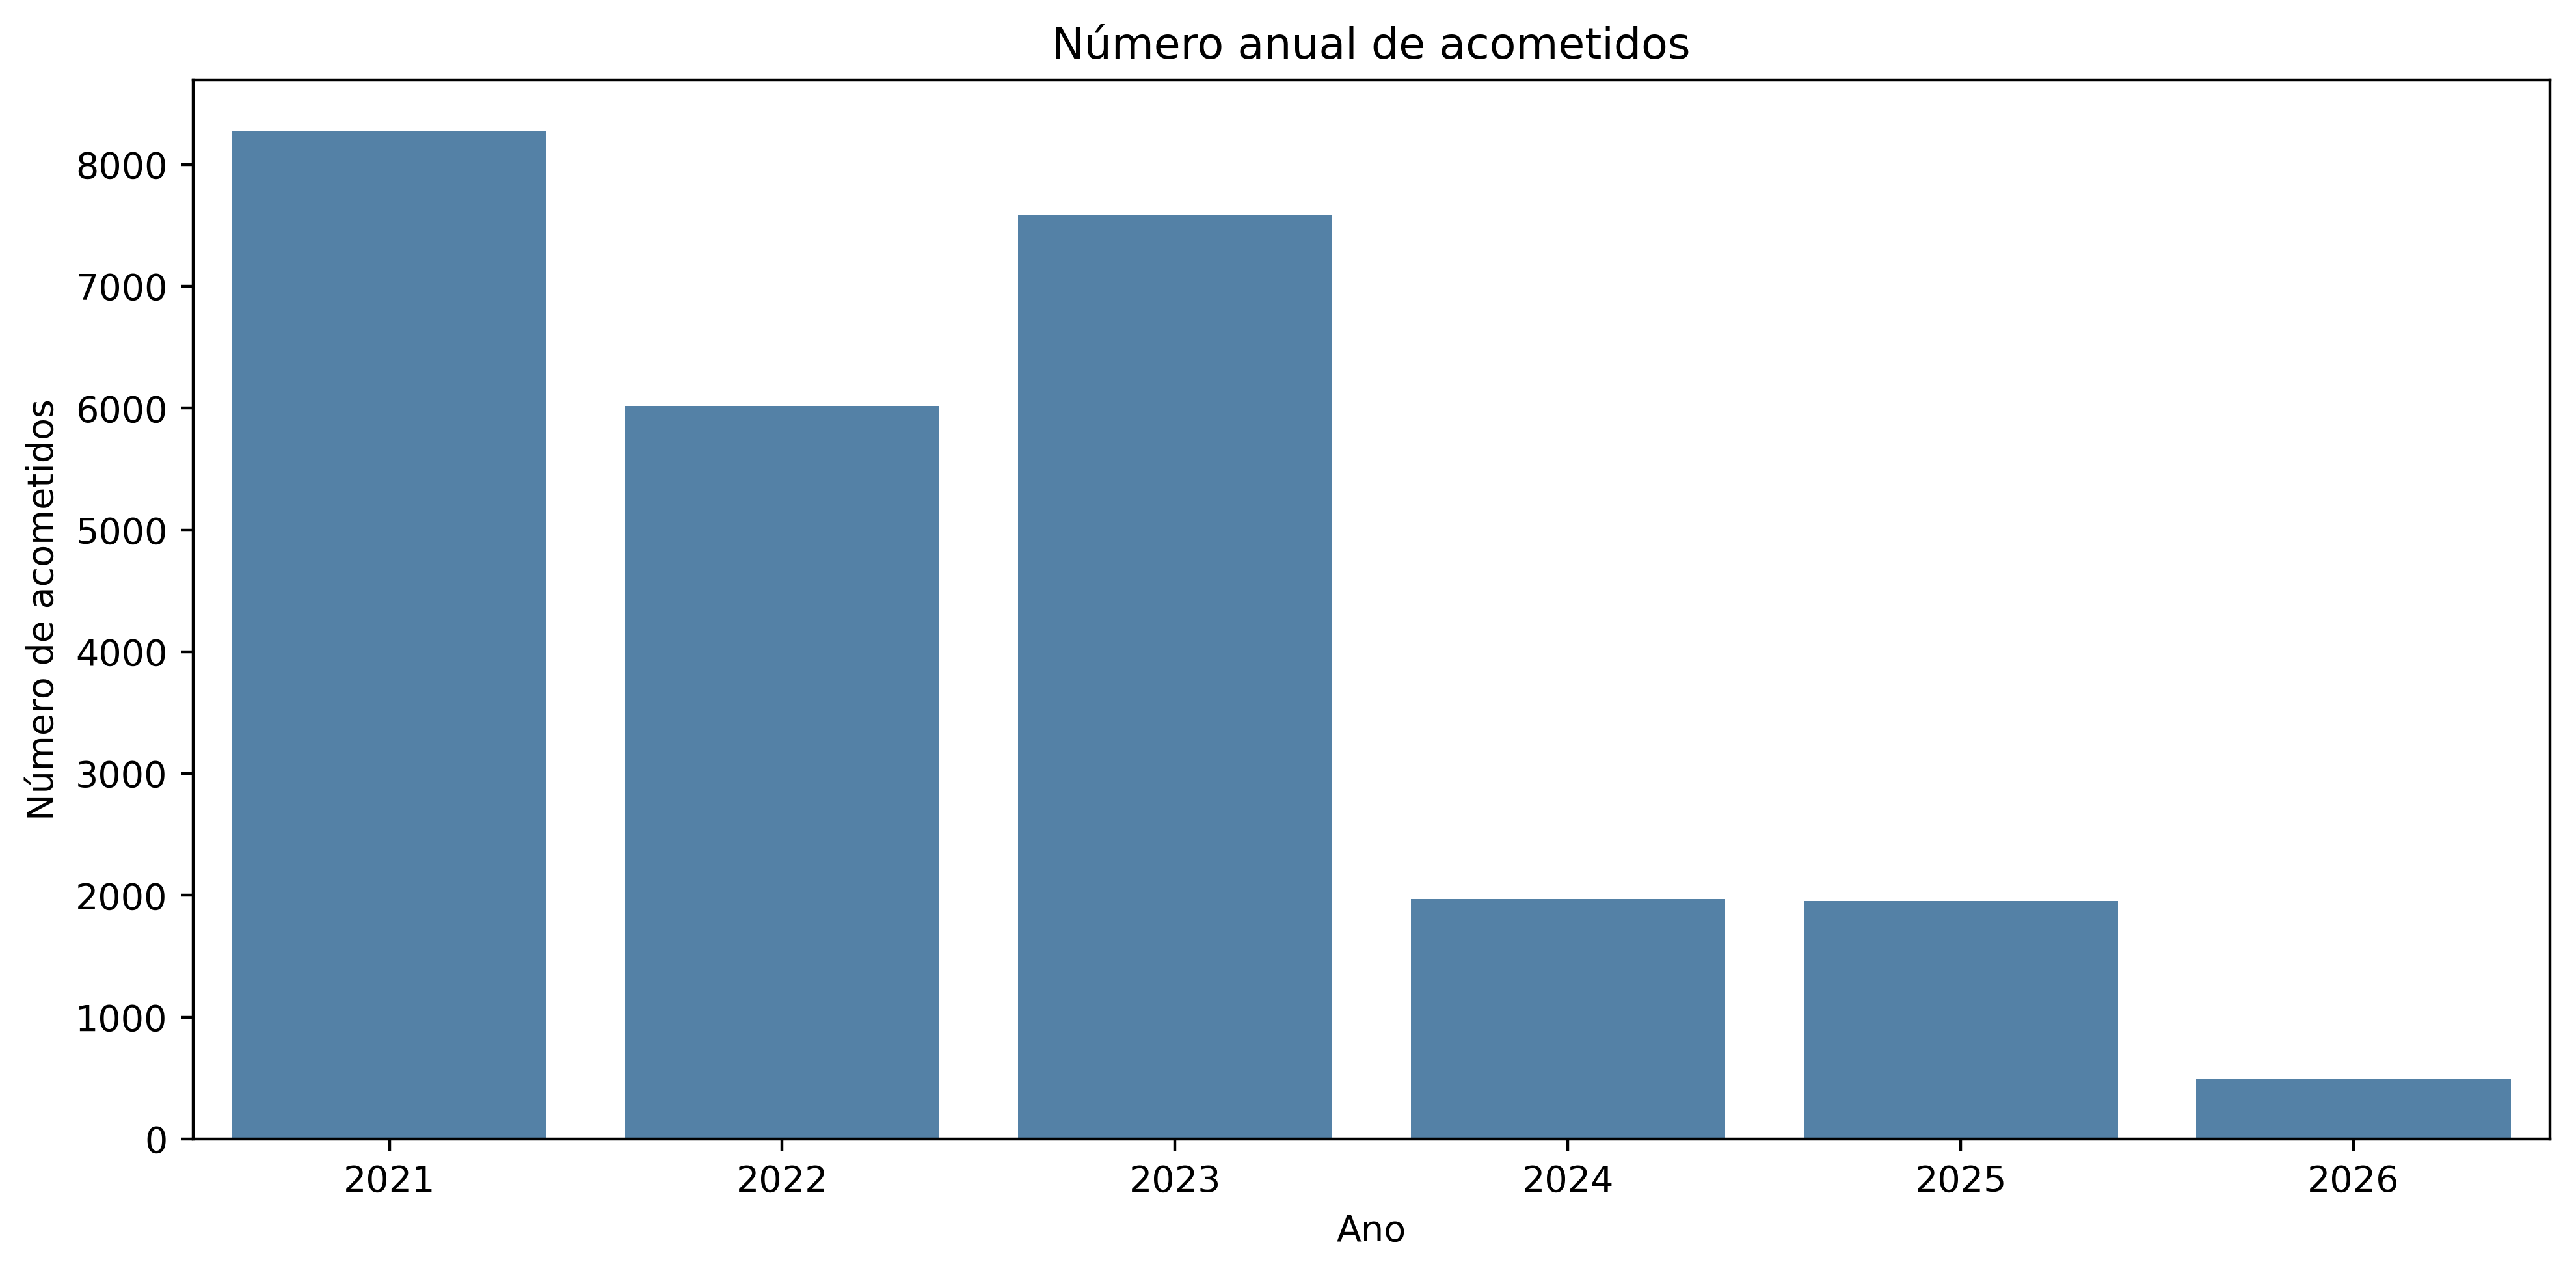

In [93]:
#criando o gráfico de barras do número anual de acometidos
pl.figure(figsize=(10, 5))

sns.barplot(
    data = (
    df_estat_bovino_se_infecto.groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("ANO")
                        ),
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    color="steelblue"
)

pl.title("Número anual de acometidos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.tight_layout()
pl.show()

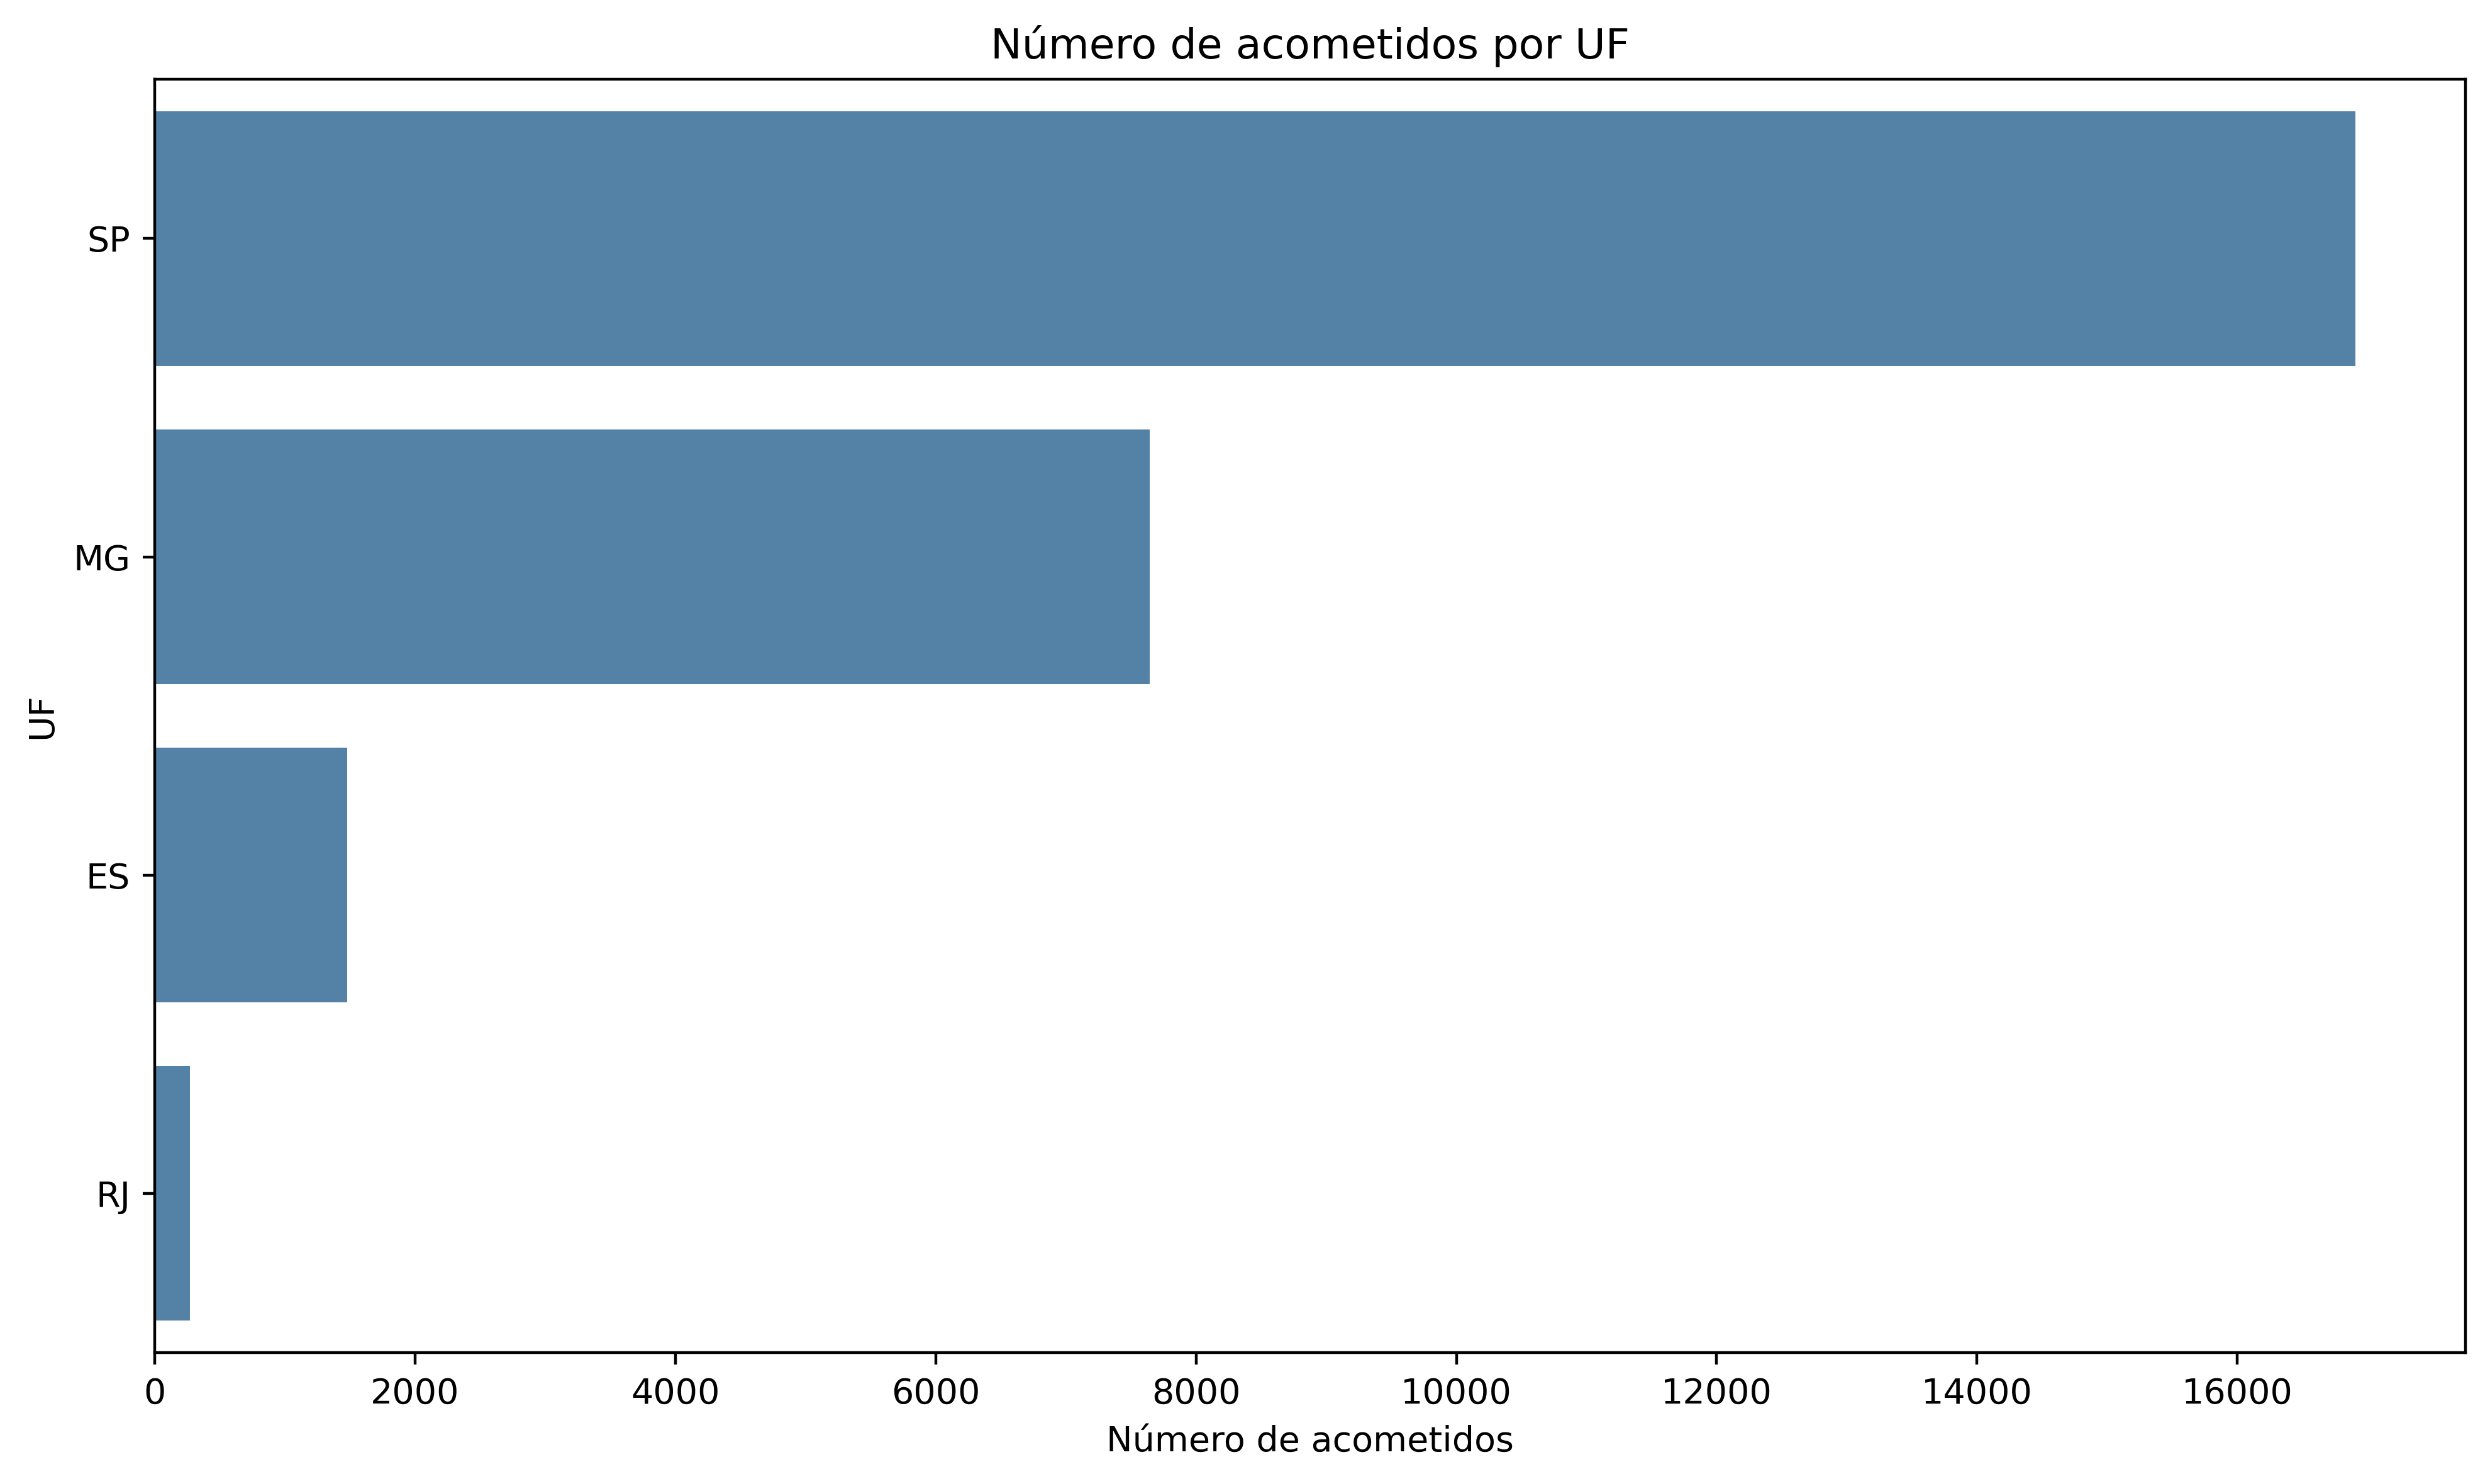

In [92]:
#realiza o ranking por estado de procedência
ranking_uf = (
    df_estat_bovino_se_infecto.groupby("UF_PROCEDENCIA", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

pl.figure(figsize=(10, 6))
sns.barplot(
    data=ranking_uf,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de acometidos por UF")
pl.xlabel("Número de acometidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()

In [94]:
#criando a tabela cruzada entre estado de procedência e diagnóstico
tabela_uf_diagnostico = pd.pivot_table(
    df_estat_bovino_se_infecto,
    values="NUMERO_ANIMAIS_ACOMETIDOS",
    index="UF_PROCEDENCIA",
    columns="DIAGNOSTICO",
    aggfunc="sum",
    fill_value= 0
)

tabela_uf_diagnostico

DIAGNOSTICO,abscesso,abscesso (mamíferos),acrobustite,actinobacilose (ruminantes),actinomicose (já notificado),actinomicose (notificação sif),agalaxia contagiosa (notificação sif),bronquite,brucella abortus (já notificado),brucella abortus (notificação sif),...,síndrome hemorrágica (suspeito),síndrome nervosa (suspeito),tuberculose,tuberculose (já notificado),tuberculose (notificação sif),tuberculose (reagente já notificado),tuberculose (reagente notificação sif),tuberculose aviária (notificação sif),tuberculose calcificada,tuberculose caseosa
UF_PROCEDENCIA,,,,,,,,,,,,,,,,,,,,,
ES,45,980,0,7,2,5,0,0,0,0,...,0,0,0,108,33,0,0,0,0,0
MG,116,4355,20,7,11,251,2,21,30,1,...,639,12,0,365,301,20,11,1,0,0
RJ,0,238,0,3,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
SP,109,13615,29,9,24,33,0,538,0,0,...,254,1,1,1,306,0,1,0,4,1


In [97]:
#Analisando o ranking por estado de procedência
ranking_uf_infecto = (
    df_estat_bovino_se_infecto.groupby("UF_PROCEDENCIA", as_index=False)
        ["NUMERO_ANIMAIS_ACOMETIDOS"].sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_uf_infecto

,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS
3,SP,16908
1,MG,7642
0,ES,1478
2,RJ,269


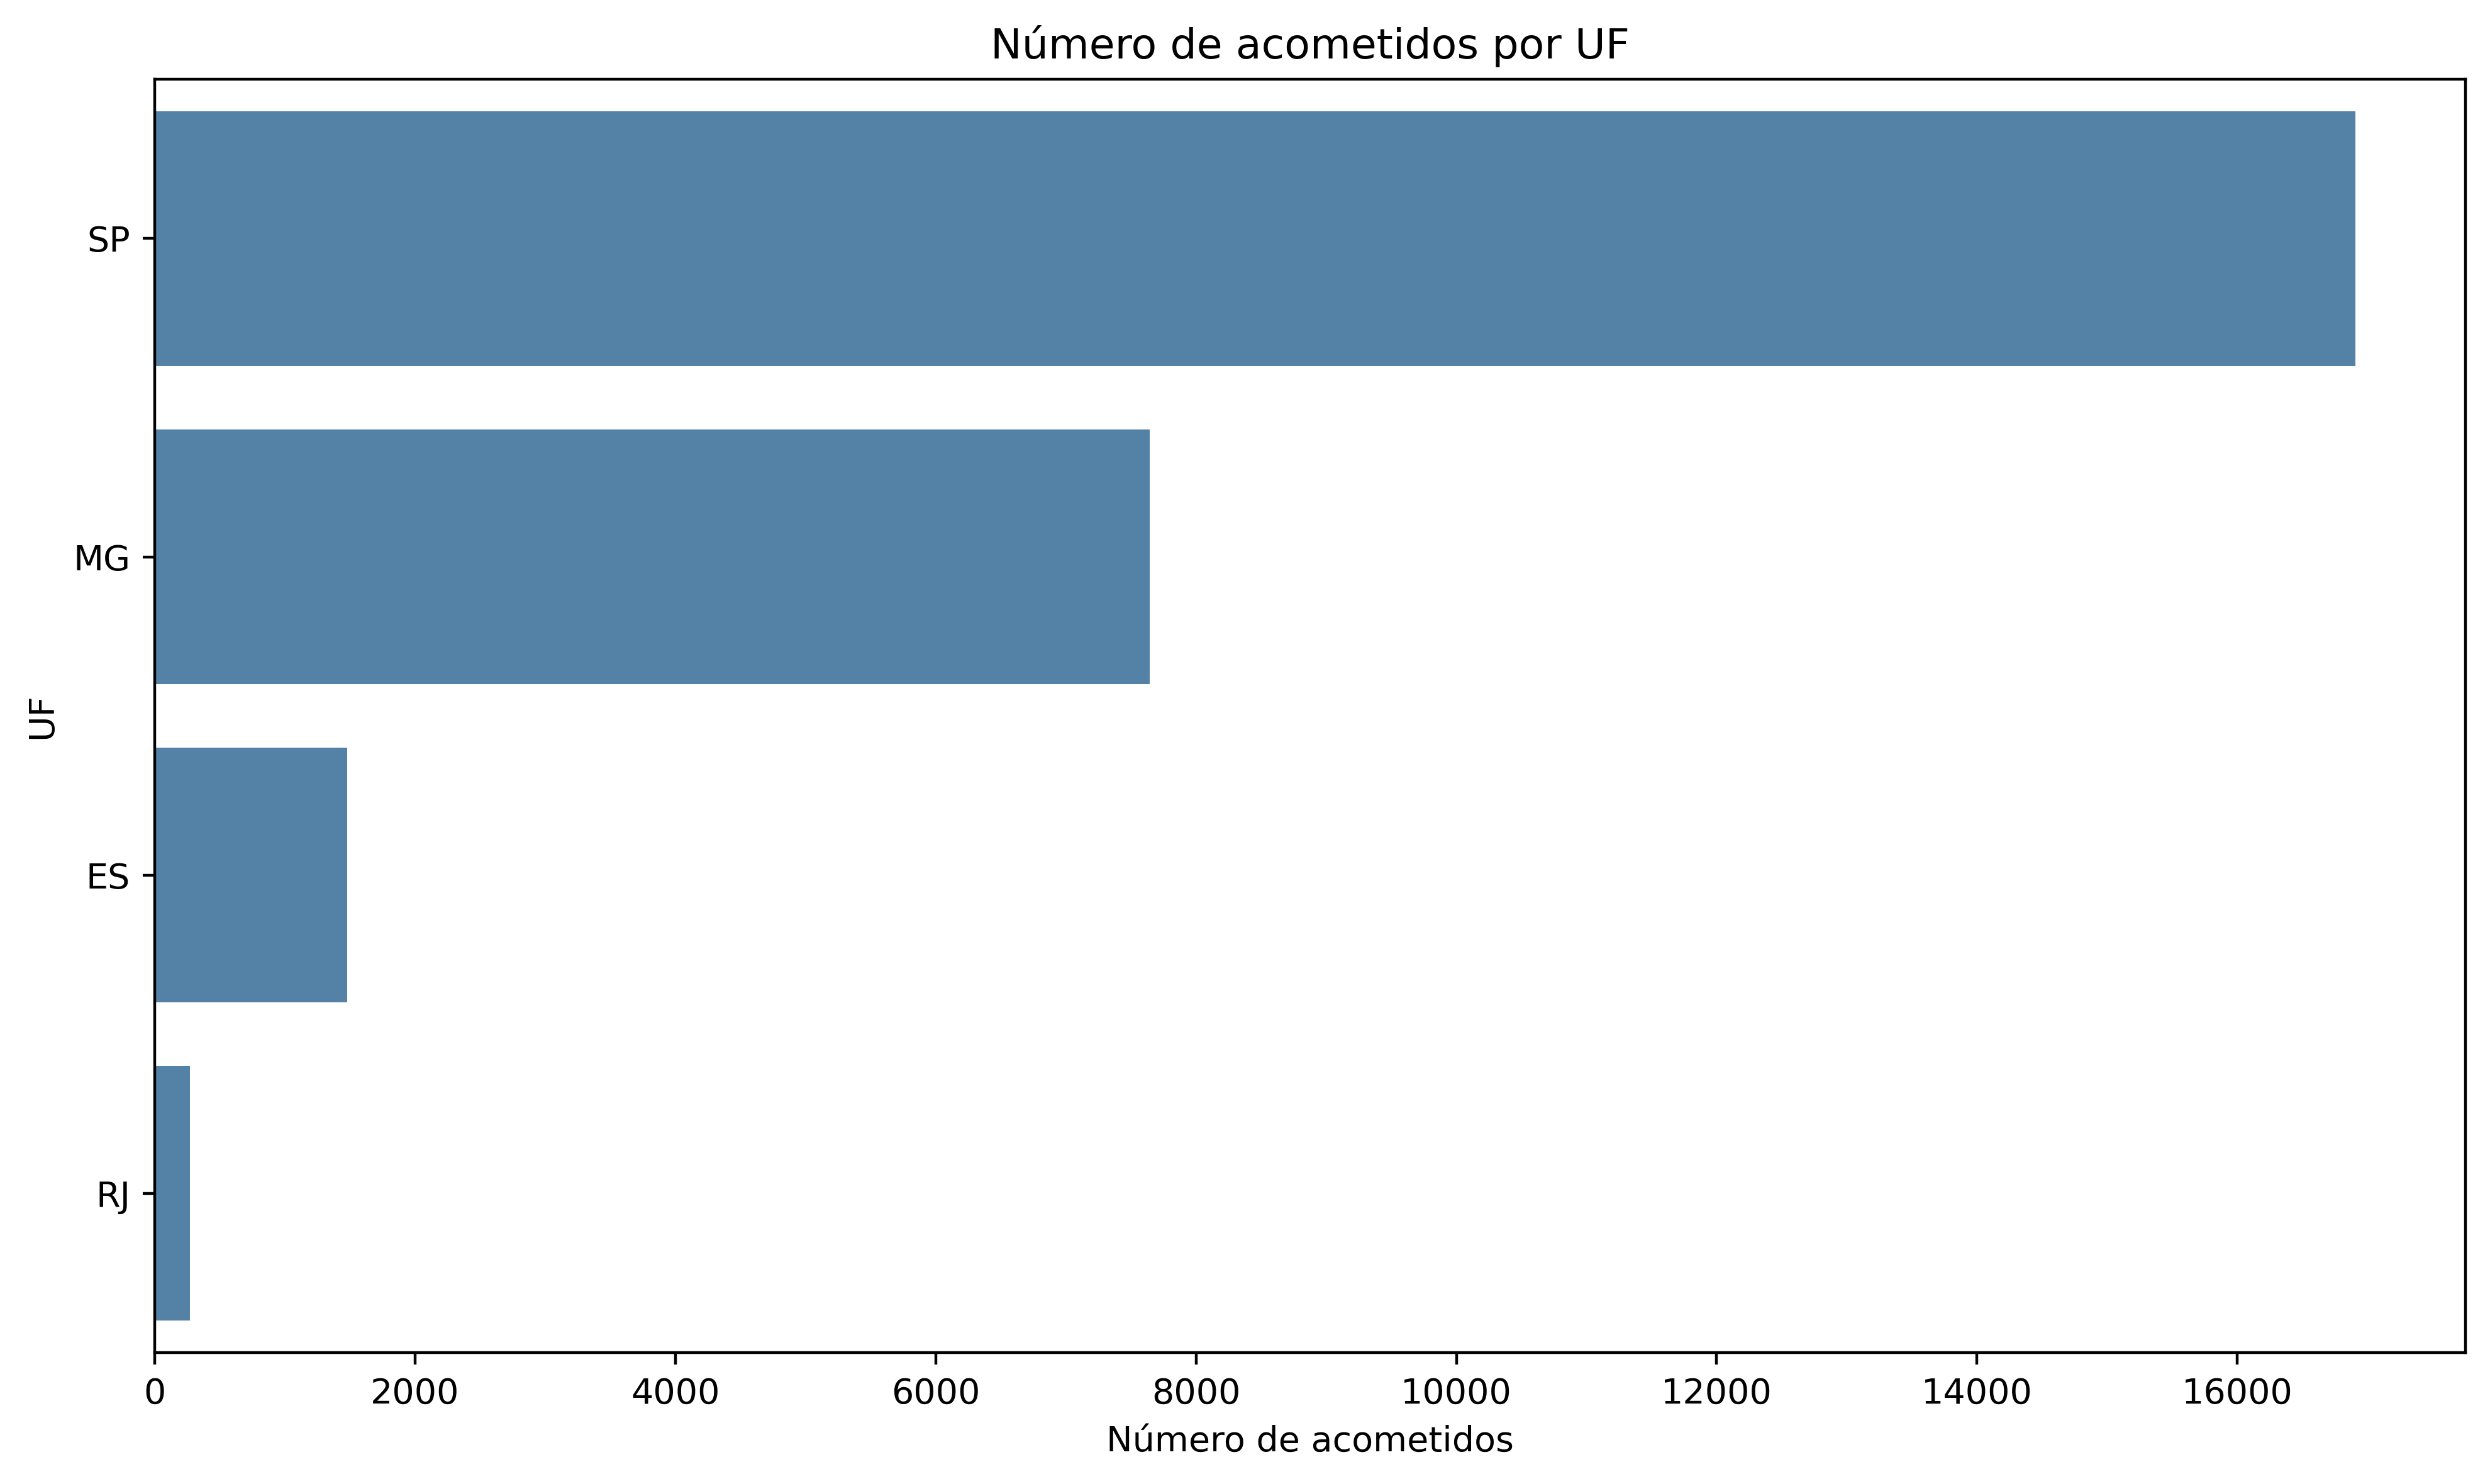

In [98]:
#Criando o gráfico de barras do número de acometidos por UF
pl.figure(figsize=(10, 6))

sns.barplot(
    data=ranking_uf_infecto,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de acometidos por UF")
pl.xlabel("Número de acometidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()

In [103]:
ranking_uf_infecto["percentual"] = (
    ranking_uf_infecto["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_uf_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_uf_infecto

,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS,percentual
3,SP,16908,64.296308
1,MG,7642,29.060349
0,ES,1478,5.620413
2,RJ,269,1.022930


In [105]:
ranking_diagnostico_infecto = (
    df_estat_bovino_se_infecto.groupby("DIAGNOSTICO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"].sum().sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_diagnostico_infecto

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS
1,abscesso (mamíferos),19188
18,lesões tuberculósicas,2472
38,síndrome hemorrágica (suspeito),893
42,tuberculose (notificação sif),640
35,septicemia,632
7,bronquite,559
41,tuberculose (já notificado),474
5,actinomicose (notificação sif),289
0,abscesso,270
22,linfadenite caseosa (notificação sif),251


In [106]:
ranking_diagnostico_infecto["percentual"] = (
    ranking_diagnostico_infecto["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_diagnostico_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_diagnostico_infecto

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
1,abscesso (mamíferos),19188,72.966498
18,lesões tuberculósicas,2472,9.400312
38,síndrome hemorrágica (suspeito),893,3.395825
42,tuberculose (notificação sif),640,2.433738
35,septicemia,632,2.403316
7,bronquite,559,2.125718
41,tuberculose (já notificado),474,1.802487
5,actinomicose (notificação sif),289,1.098985
0,abscesso,270,1.026733
22,linfadenite caseosa (notificação sif),251,0.954481


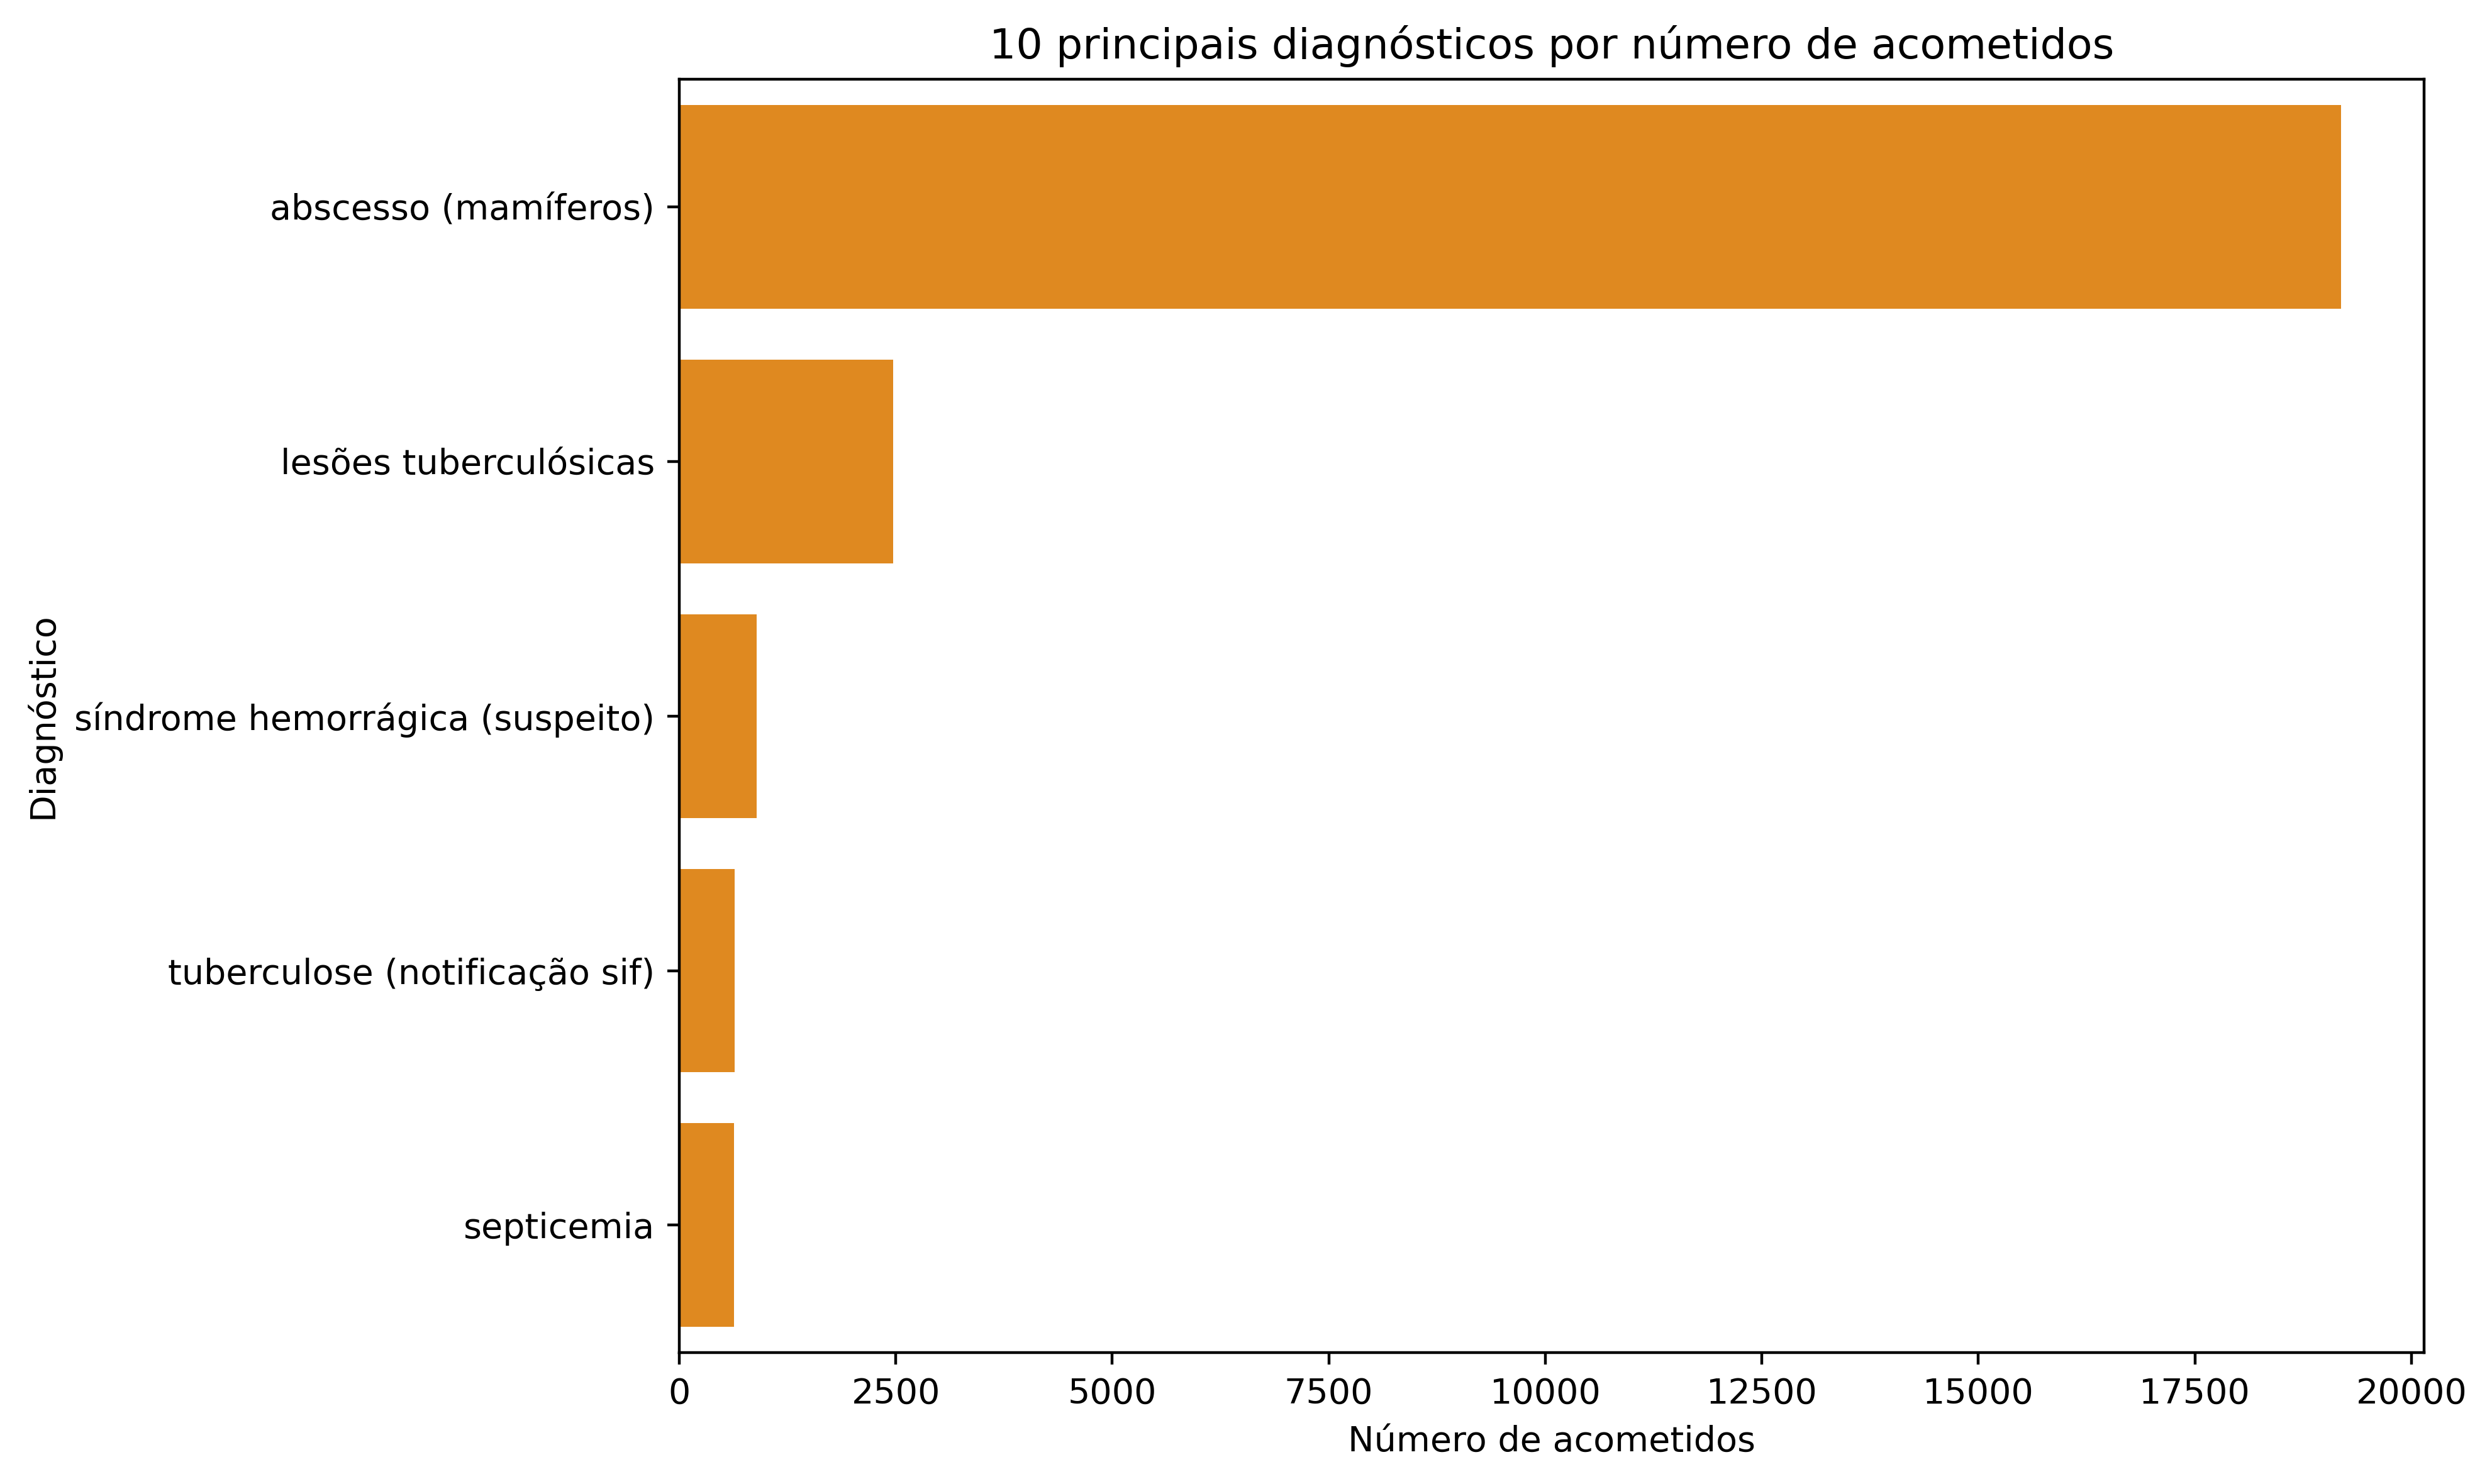

In [107]:
top10_diagnostico_infecto = ranking_diagnostico_infecto.head(5)

pl.figure(figsize=(10, 6))

sns.barplot(
    data=top10_diagnostico_infecto,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="DIAGNOSTICO",
    color="darkorange"
)

pl.title("10 principais diagnósticos por número de acometidos")
pl.xlabel("Número de acometidos")
pl.ylabel("Diagnóstico")
pl.tight_layout()
pl.show()

In [108]:
diagnostico_ano_infecto = (
    df_estat_bovino_se_infecto.groupby(["ANO", "DIAGNOSTICO"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values(["ANO", "NUMERO_ANIMAIS_ACOMETIDOS"], ascending=[True, False])
)

diagnostico_ano_infecto

,ANO,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS
1,2021,abscesso (mamíferos),5680
20,2021,síndrome hemorrágica (suspeito),891
6,2021,bronquite,559
0,2021,abscesso,270
10,2021,lesões tuberculósicas,229
...,...,...,...
133,2026,tuberculose (notificação sif),13
130,2026,pneumonia enzoótica (notificação sif),8
125,2026,acrobustite,4
126,2026,actinomicose (notificação sif),4


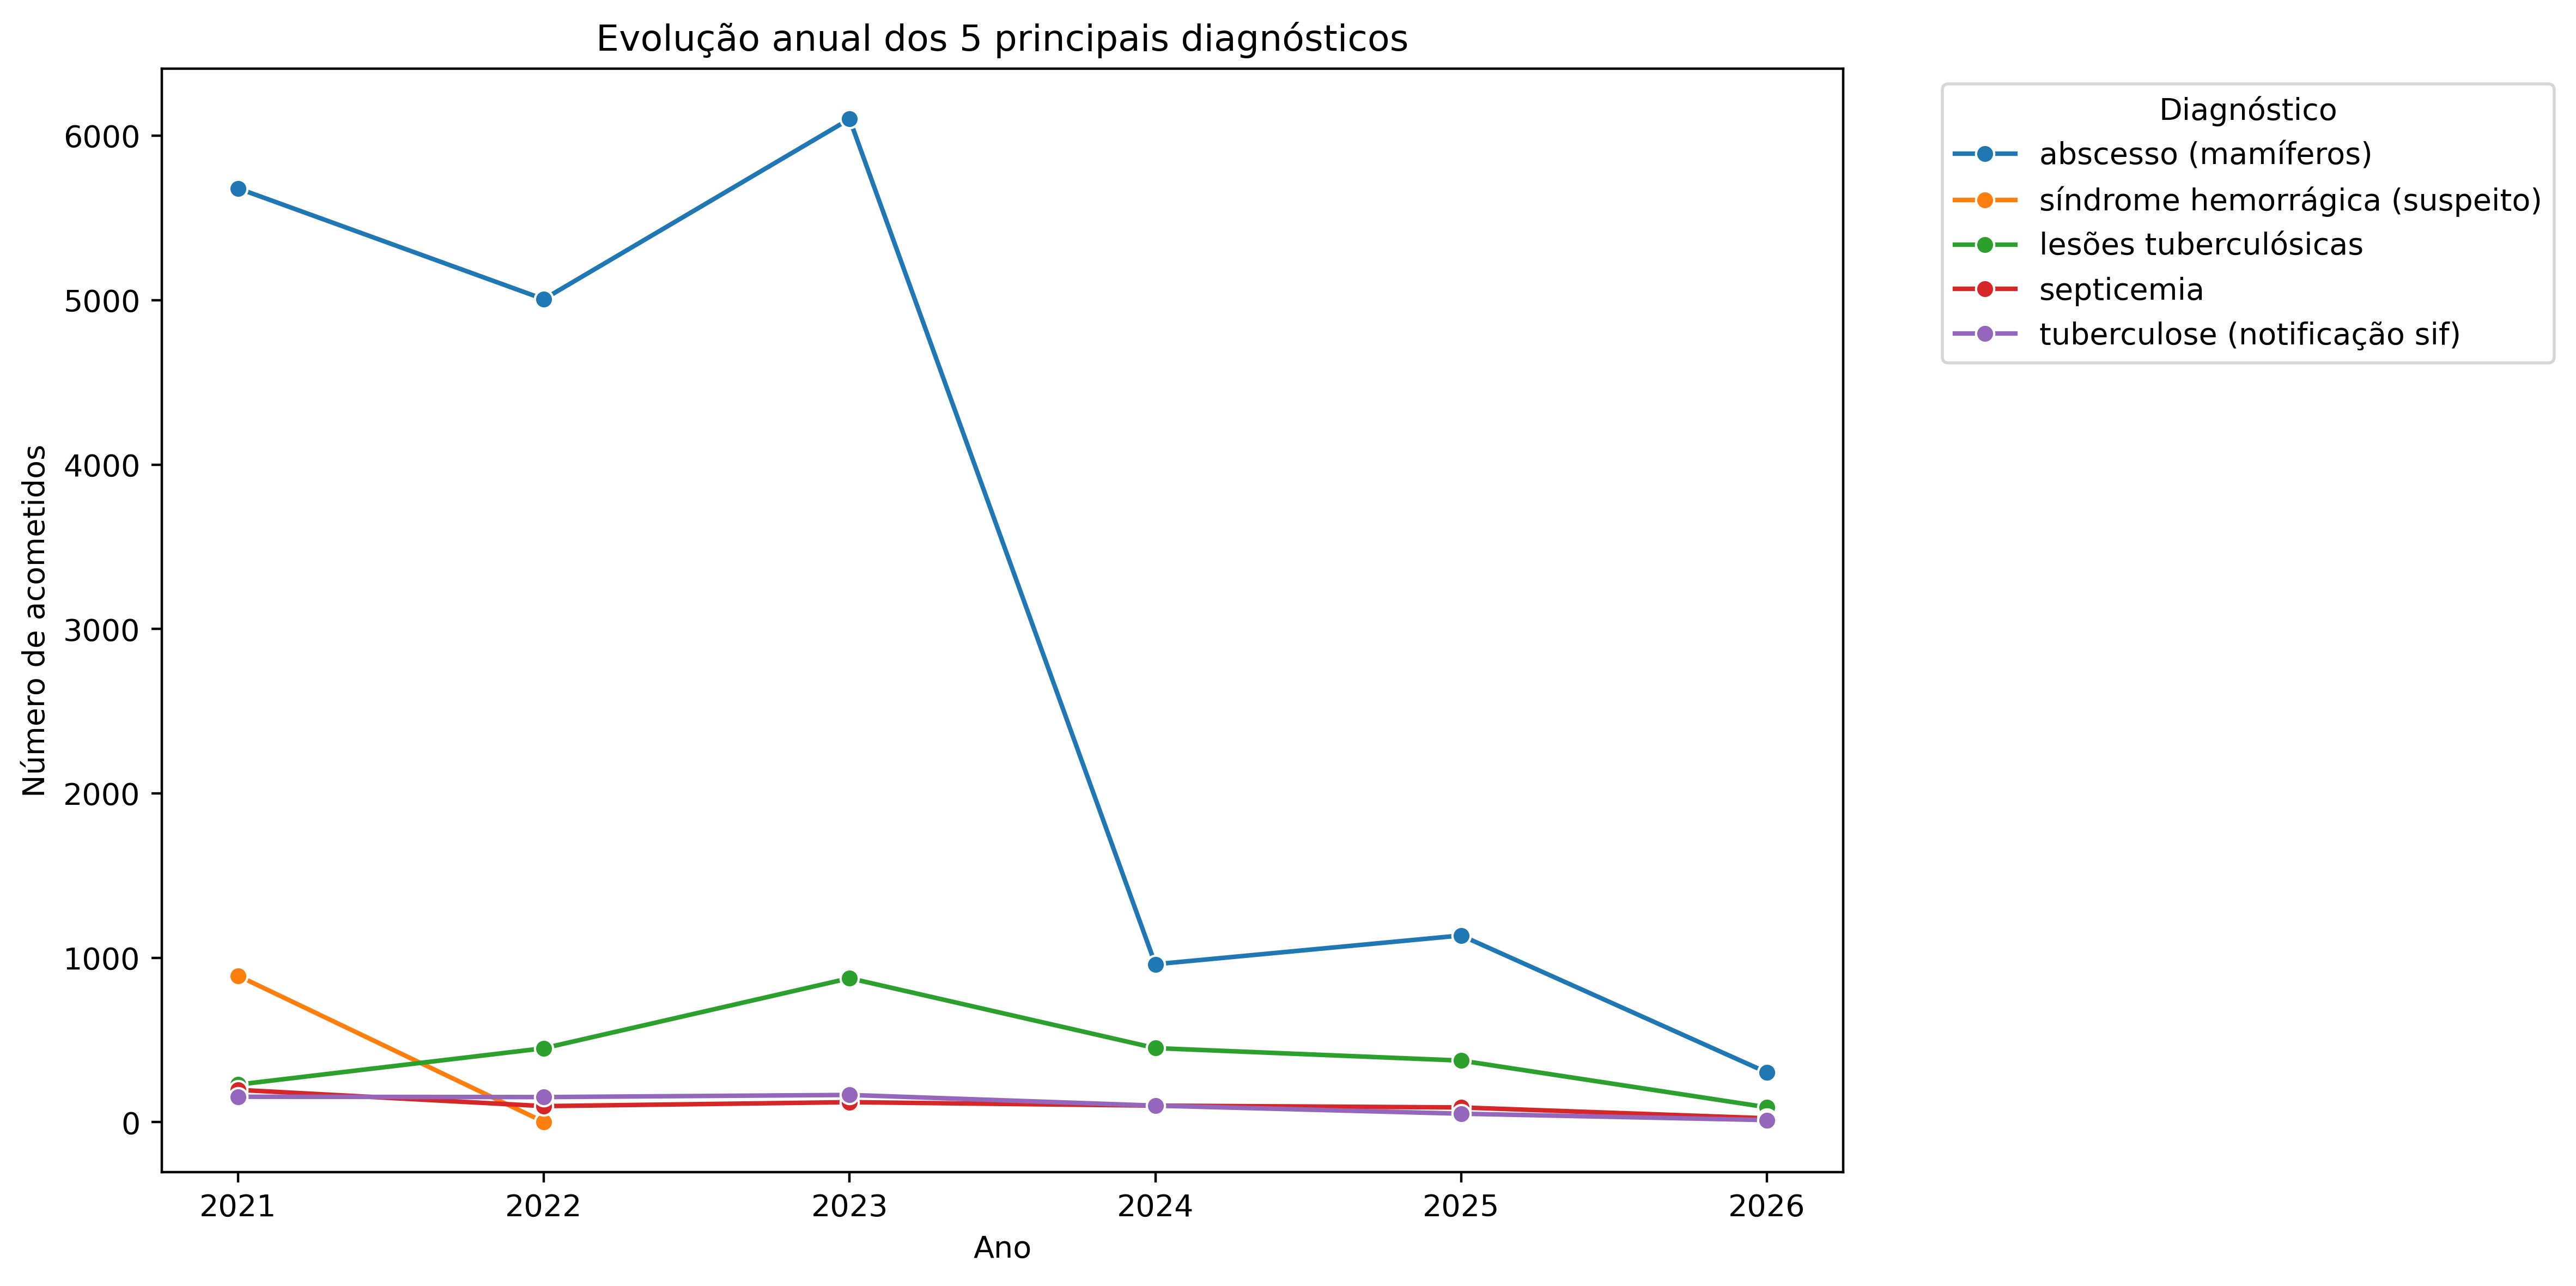

In [109]:
top5_diag_infecto = (
    df_estat_bovino_se_infecto.groupby("DIAGNOSTICO")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values(ascending=False)
      .head(5)
      .index
)

diagnostico_ano_top5_infecto = diagnostico_ano_infecto[
    diagnostico_ano_infecto["DIAGNOSTICO"].isin(top5_diag_infecto)
]

pl.figure(figsize=(12, 6))

sns.lineplot(
    data=diagnostico_ano_top5_infecto,
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    hue="DIAGNOSTICO",
    marker="o"
)

pl.title("Evolução anual dos 5 principais diagnósticos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.xticks(sorted(diagnostico_ano_top5_infecto["ANO"].unique()))
pl.legend(title="Diagnóstico", bbox_to_anchor=(1.05, 1), loc="upper left")
pl.tight_layout()
pl.show()

In [110]:
media = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].mean()
mediana = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].median()
desvio_padrao = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].std()
variancia = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].var()
coef_variacao = desvio_padrao / media * 100
print(f"Média: {media:.2f}")
print(f"Mediana: {mediana:.2f}")
print(f"Desvio Padrão: {desvio_padrao:.2f}")
print(f"Variância: {variancia:.2f}")
print(f"Coeficiente de Variação: {coef_variacao:.2f}%")

Média: 21.07
Mediana: 3.00
Desvio Padrão: 64.02
Variância: 4098.93
Coeficiente de Variação: 303.84%


In [111]:
assimetria = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].skew()
curtose = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].kurtosis()
print(f"Assimetria: {assimetria:.2f}")
print(f"Curtose: {curtose:.2f}")

Assimetria: 5.31
Curtose: 31.95


In [112]:
minimo = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].min()
maximo = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].max()
amplitude = maximo - minimo

q1 = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.25)
q3 = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.75)
iqr = q3 - q1
print(f"Valor mínimo: {minimo}")
print(f"Valor máximo: {maximo}")
print(f"Amplitude: {amplitude}")
print(f"Q1: {q1}")
print(f"Q3: {q3}")
print(f"IQR: {iqr}")

Valor mínimo: 1
Valor máximo: 682
Amplitude: 681
Q1: 1.0
Q3: 10.0
IQR: 9.0


In [113]:
q1 = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.25)
q3 = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.75)
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = df_estat_bovino_se_infecto[
    (df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"] < limite_inferior) |
    (df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"] > limite_superior)
]

print(f"Outliers encontrados:\n{outliers}")

Outliers encontrados:
       MES_ANO UF_PROCEDENCIA ESPECIE                            DIAGNOSTICO  \
0   2023-06-01             SP  Bovino                   abscesso (mamíferos)   
1   2023-05-01             SP  Bovino                   abscesso (mamíferos)   
2   2023-04-01             SP  Bovino                   abscesso (mamíferos)   
3   2023-07-01             SP  Bovino                   abscesso (mamíferos)   
4   2021-11-01             SP  Bovino                   abscesso (mamíferos)   
..         ...            ...     ...                                    ...   
162 2023-10-01             MG  Bovino                  lesões tuberculósicas   
163 2022-09-01             ES  Bovino                   abscesso (mamíferos)   
164 2021-12-01             MG  Bovino         actinomicose (notificação sif)   
165 2021-02-01             MG  Bovino  linfadenite caseosa (notificação sif)   
166 2021-11-01             SP  Bovino        síndrome hemorrágica (suspeito)   

     NUMERO_ANIMA

In [114]:
desc_por_uf_infecto = (
      df_estat_bovino_se_infecto.groupby("UF_PROCEDENCIA")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .agg(["count", "sum", "mean", "median", "std", "min", "max"])
      .sort_values("sum", ascending=False)
)

desc_por_uf_infecto

,count,sum,mean,median,std,min,max
UF_PROCEDENCIA,,,,,,,
SP,406,16908,41.645320,3.0,100.379218,1,682
MG,572,7642,13.360140,3.0,35.960521,1,422
ES,201,1478,7.353234,3.0,11.611184,1,58
RJ,69,269,3.898551,2.0,4.176774,1,21


In [115]:
desc_por_diagnostico_infecto = (
    df_estat_bovino_se_infecto.groupby("DIAGNOSTICO")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .agg(["count", "sum", "mean", "median", "std", "min", "max"])
      .sort_values("sum", ascending=False)
)
desc_por_diagnostico_infecto

,count,sum,mean,median,std,min,max
DIAGNOSTICO,,,,,,,
abscesso (mamíferos),220,19188,87.218182,31.0,128.487434,1,682
lesões tuberculósicas,191,2472,12.942408,7.0,17.942652,1,180
síndrome hemorrágica (suspeito),18,893,49.611111,28.0,45.905451,2,142
tuberculose (notificação sif),138,640,4.637681,3.0,3.952163,1,22
septicemia,156,632,4.051282,3.0,4.513485,1,36
bronquite,3,559,186.333333,188.0,164.506332,21,350
tuberculose (já notificado),85,474,5.576471,3.0,4.909603,1,21
actinomicose (notificação sif),94,289,3.074468,1.0,4.370575,1,27
abscesso,6,270,45.000000,34.5,40.787253,1,115


In [116]:
ranking_diagnostico_infecto = (
    df_estat_bovino_se_infecto.groupby("DIAGNOSTICO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_diagnostico_infecto["percentual"] = (
    ranking_diagnostico_infecto["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_diagnostico_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_diagnostico_infecto["percentual_acumulado"] = ranking_diagnostico_infecto["percentual"].cumsum()

ranking_diagnostico_infecto

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual,percentual_acumulado
1,abscesso (mamíferos),19188,72.966498,72.966498
18,lesões tuberculósicas,2472,9.400312,82.366810
38,síndrome hemorrágica (suspeito),893,3.395825,85.762635
42,tuberculose (notificação sif),640,2.433738,88.196372
35,septicemia,632,2.403316,90.599688
7,bronquite,559,2.125718,92.725406
41,tuberculose (já notificado),474,1.802487,94.527893
5,actinomicose (notificação sif),289,1.098985,95.626878
0,abscesso,270,1.026733,96.653611
22,linfadenite caseosa (notificação sif),251,0.954481,97.608092


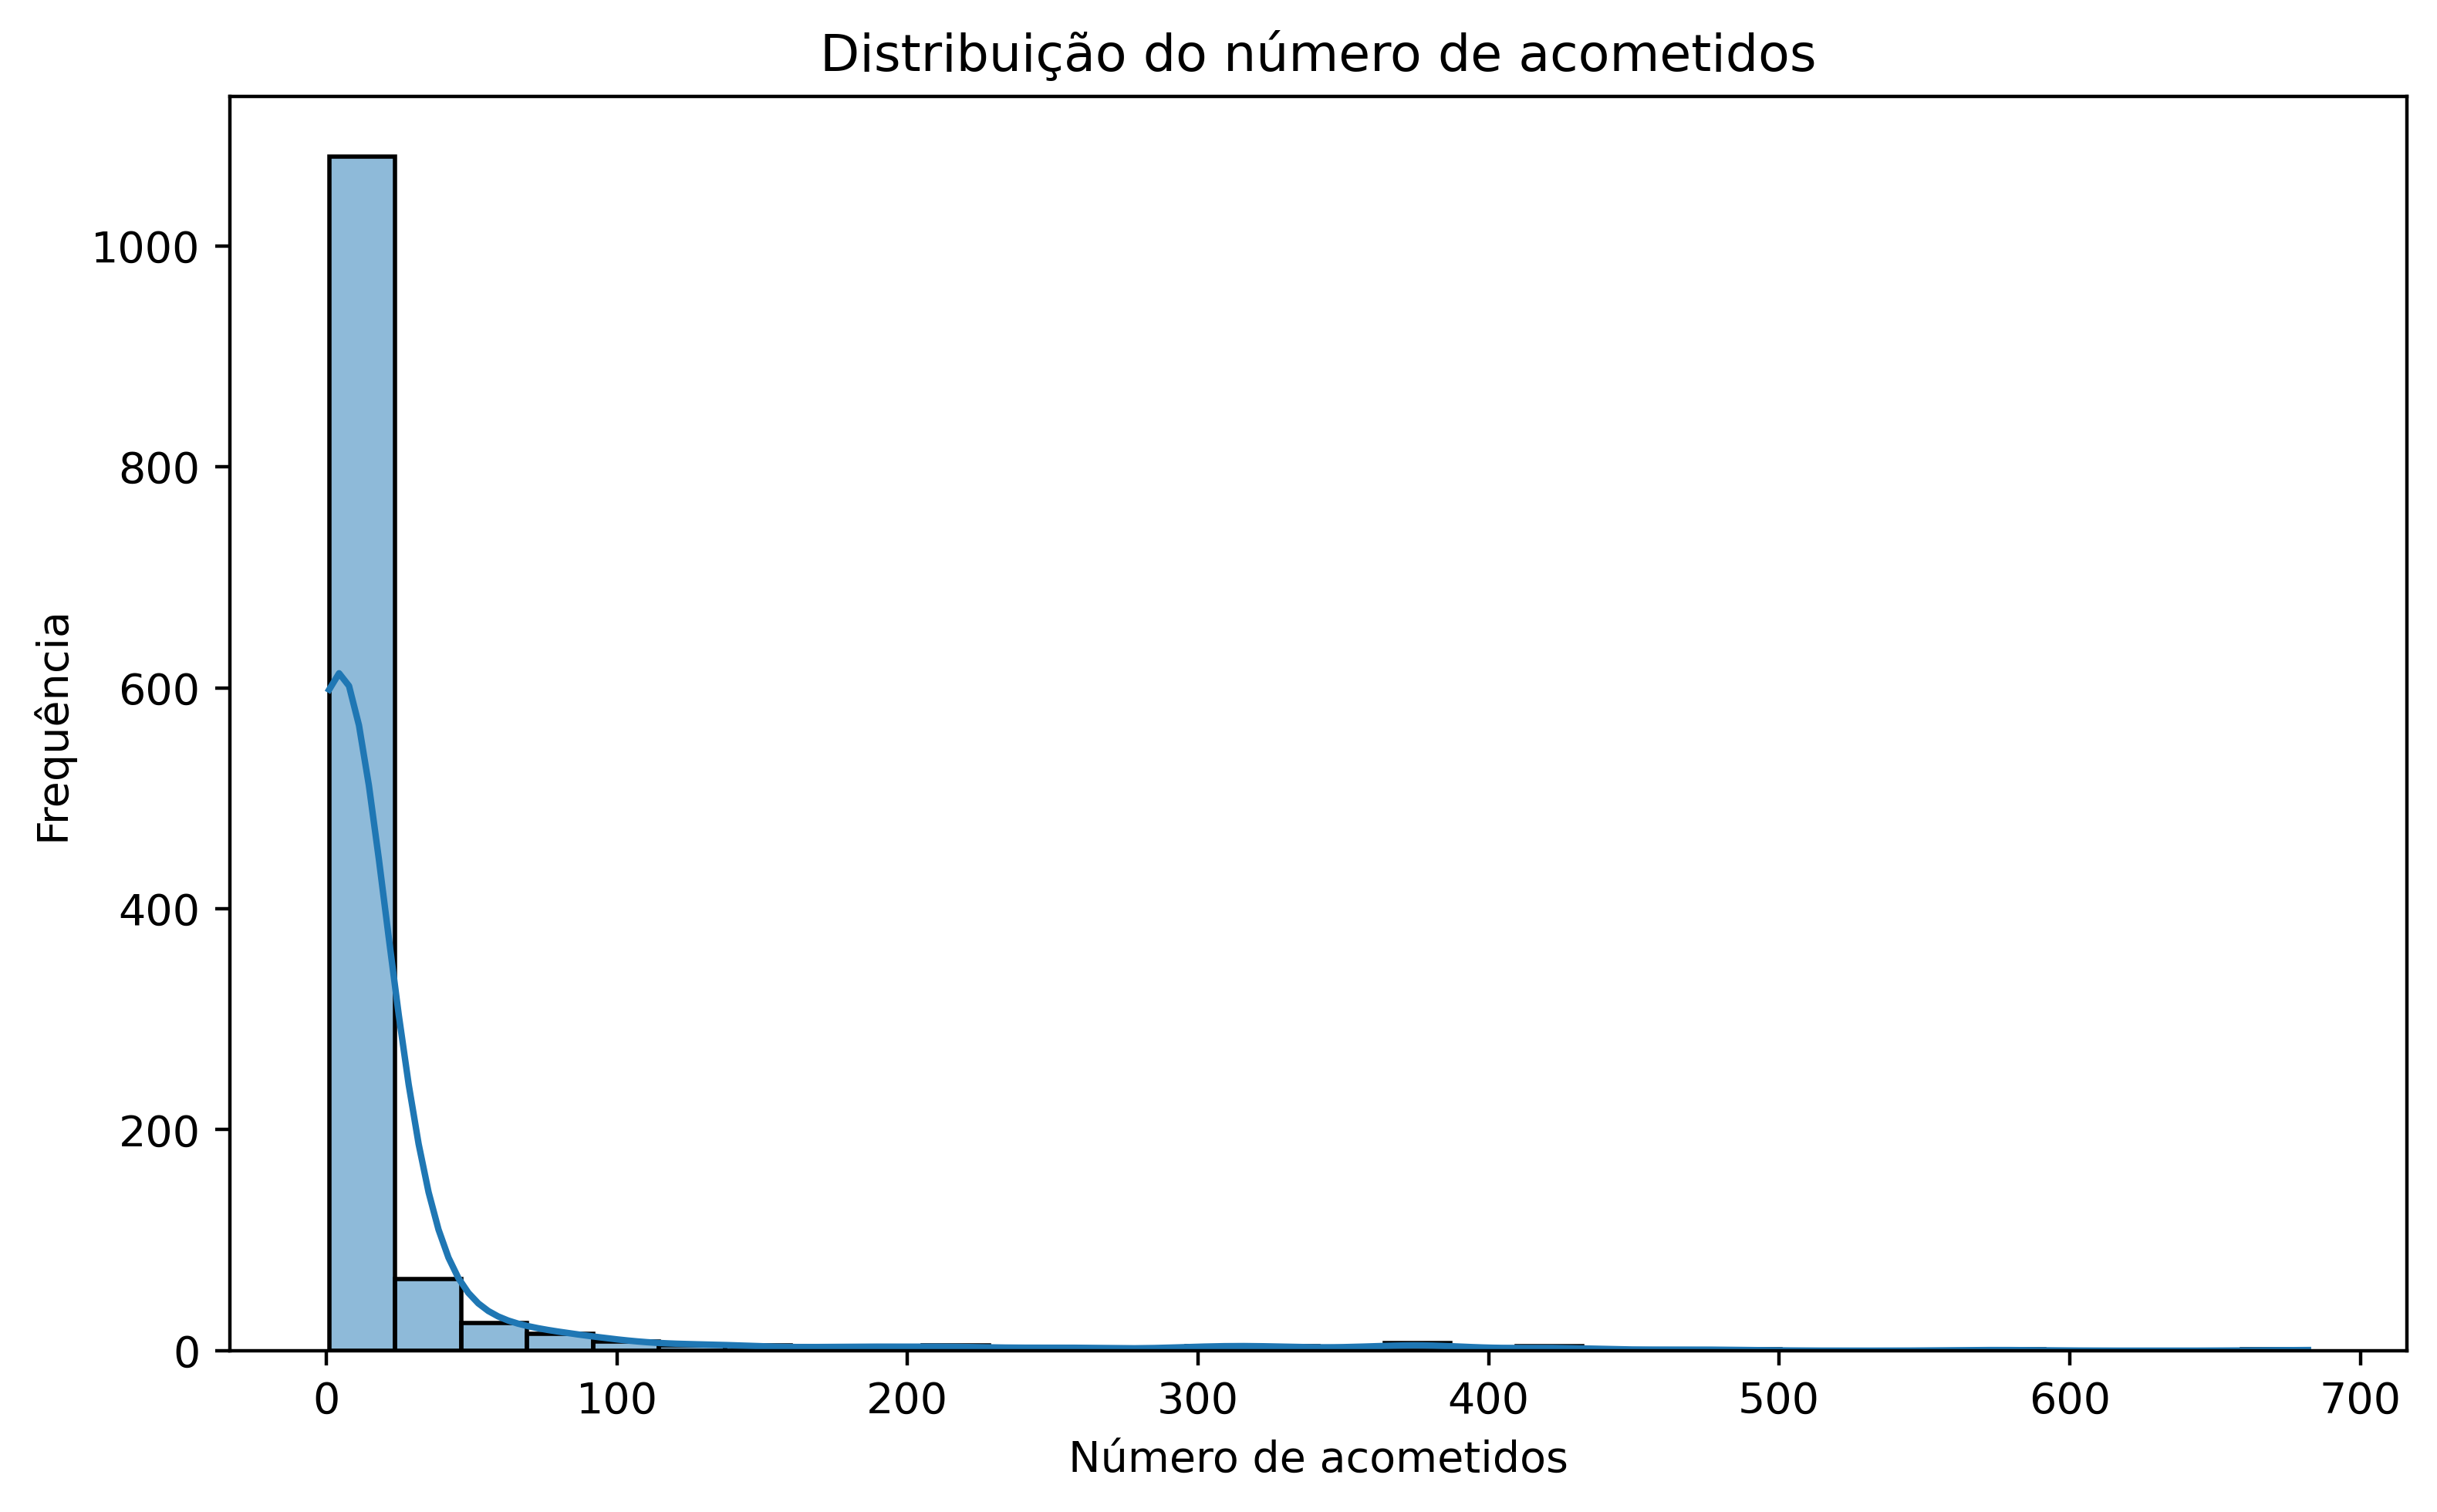

In [117]:
pl.figure(figsize=(8, 5))

sns.histplot(
    data=df_estat_bovino_se_infecto,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    bins=30,
    kde=True
)

pl.title("Distribuição do número de acometidos")
pl.xlabel("Número de acometidos")
pl.ylabel("Frequência")
pl.tight_layout()
pl.show()

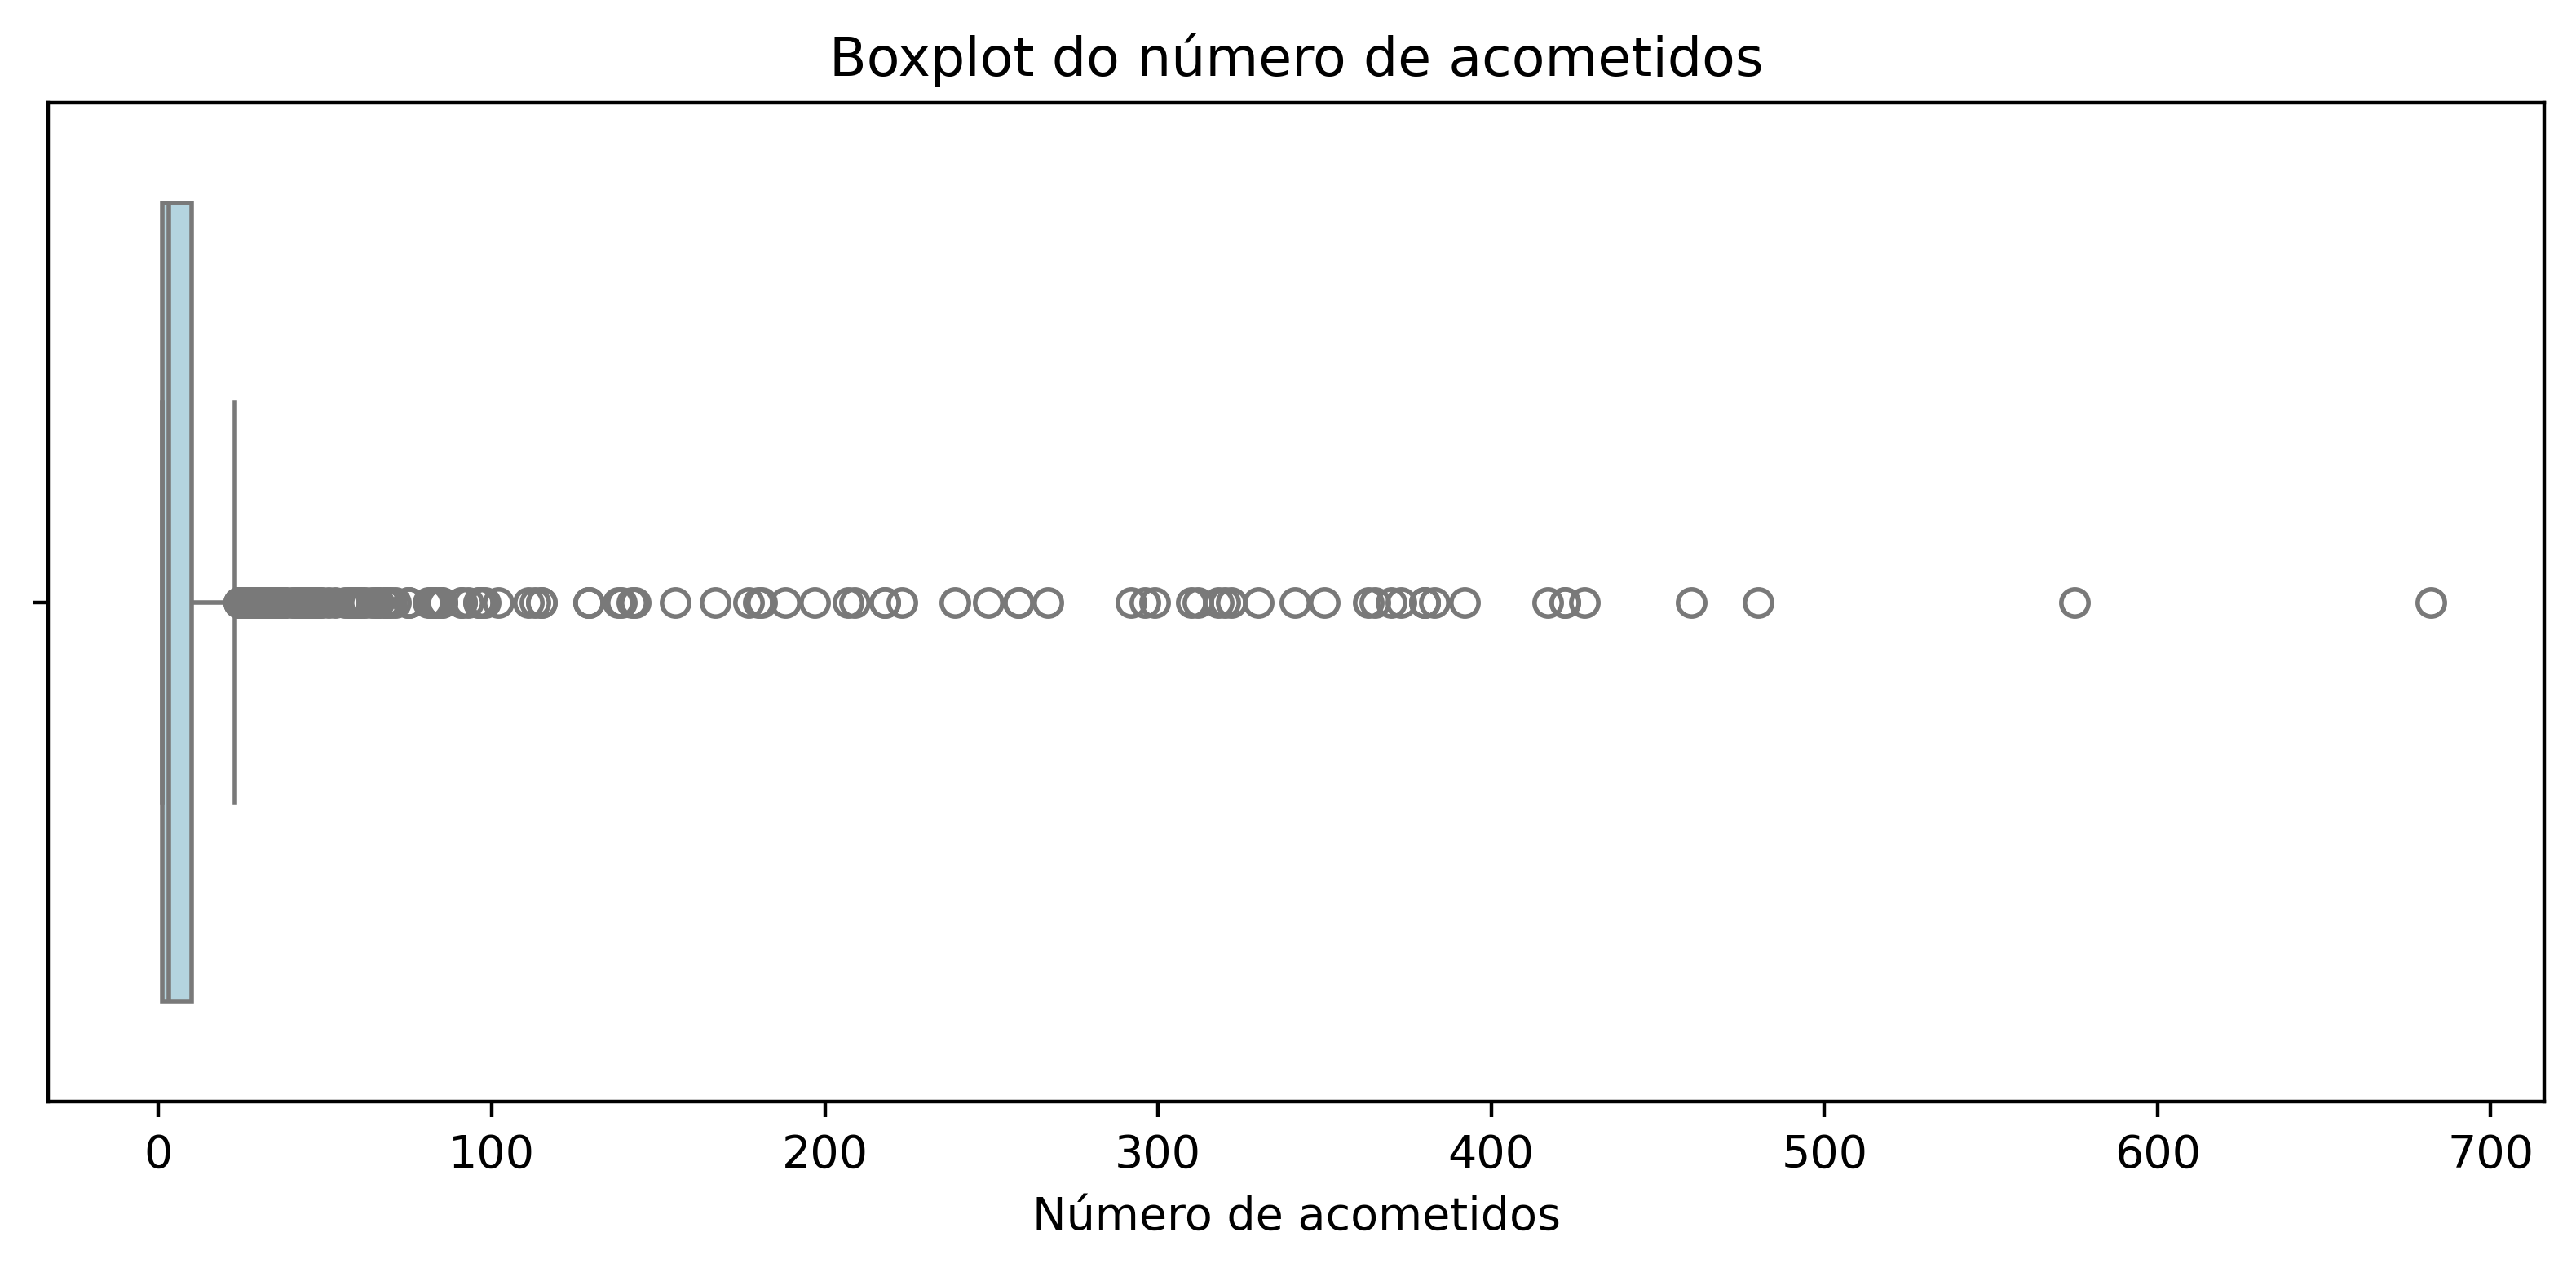

In [118]:
pl.figure(figsize=(8, 4))

sns.boxplot(
    data=df_estat_bovino_se_infecto,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    color="lightblue"
)

pl.title("Boxplot do número de acometidos")
pl.xlabel("Número de acometidos")
pl.tight_layout()
pl.show()

Análise estatística abate sudeste

In [124]:
df_estat_bovino_abate_sudeste.head(10)

,ANO,MES,UF_PROCEDENCIA,MUNICIPIO_PROCEDENCIA,CATEGORIA,Sexo,Espécie,QUANTIDADE
0,2025,8,MG,Araguari,Bovino,Indeterminado,Bovino,3697
1,2025,9,MG,Monte Alegre de Minas,Bovino,Indeterminado,Bovino,1173
2,2025,6,MG,Cascalho Rico,Bovino,Indeterminado,Bovino,412
3,2021,2,MG,Estrela do Sul,Bovino,Indeterminado,Bovino,1576
4,2021,2,MG,Campina Verde,Bovino,Indeterminado,Bovino,7180
5,2021,2,MG,Vazante,Bovino,Indeterminado,Bovino,268
6,2021,3,MG,Tupaciguara,Bovino,Indeterminado,Bovino,1342
7,2021,3,MG,Tiros,Bovino,Indeterminado,Bovino,510
8,2021,2,MG,Sao Gotardo,Bovino,Indeterminado,Bovino,68
9,2021,2,MG,Carmo do Paranaiba,Bovino,Indeterminado,Bovino,417


In [133]:
df_estat_bovino_abate_sudeste_bov = df_estat_bovino_abate_sudeste[df_estat_bovino_abate_sudeste['Espécie'].isin(['Bovino']) & df_estat_bovino_abate_sudeste['ANO'].isin([2021, 2022, 2023, 2024, 2025, 2026])]
print(df_estat_bovino_abate_sudeste_bov)

         ANO  MES UF_PROCEDENCIA  MUNICIPIO_PROCEDENCIA     CATEGORIA  \
0       2025    8             MG               Araguari        Bovino   
1       2025    9             MG  Monte Alegre de Minas        Bovino   
2       2025    6             MG          Cascalho Rico        Bovino   
3       2021    2             MG         Estrela do Sul        Bovino   
4       2021    2             MG          Campina Verde        Bovino   
...      ...  ...            ...                    ...           ...   
516640  2021    1             MG         Carmo De Minas  Bovino Macho   
516641  2021    1             MG               Oliveira  Bovino Macho   
516642  2021    1             MG           Delfinópolis  Bovino Femea   
516643  2021    1             MG                Juruaia  Bovino Femea   
516644  2021    1             MG       Cabeceira Grande  Bovino Femea   

                 Sexo Espécie  QUANTIDADE  
0       Indeterminado  Bovino        3697  
1       Indeterminado  Bovino      

In [134]:
df_estat_bovino_abate_sudeste_bov.info()

<class 'pandas.core.frame.DataFrame'>
Index: 59977 entries, 0 to 516644
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   ANO                    59977 non-null  int64 
 1   MES                    59977 non-null  int64 
 2   UF_PROCEDENCIA         59977 non-null  object
 3   MUNICIPIO_PROCEDENCIA  59977 non-null  object
 4   CATEGORIA              59977 non-null  object
 5   Sexo                   59977 non-null  object
 6   Espécie                59977 non-null  object
 7   QUANTIDADE             59977 non-null  int64 
dtypes: int64(3), object(5)
memory usage: 4.1+ MB


In [135]:
df_estat_bovino_abate_sudeste_bov.describe()

,ANO,MES,QUANTIDADE
count,59977.000000,59977.000000,59977.00000
mean,2023.139370,6.142571,420.81733
std,1.534321,3.475739,1106.76035
min,2021.000000,1.000000,1.00000
25%,2022.000000,3.000000,38.00000
50%,2023.000000,6.000000,99.00000
75%,2024.000000,9.000000,300.00000
max,2026.000000,12.000000,43708.00000


In [136]:
#Realizando o resumo por ano, estado de procedência e diagnóstico
variaveis_abate = ["ANO","UF_PROCEDENCIA", "Sexo"]

for var in variaveis_abate:
    resumo = (
        df_estat_bovino_abate_sudeste_bov.groupby(var, as_index=False)["QUANTIDADE"]
          .sum()
          .sort_values("QUANTIDADE", ascending=False)
    )
    
    resumo["percentual"] = (
        resumo["QUANTIDADE"] / resumo["QUANTIDADE"].sum() * 100
    )
    
    print(f"\nResumo por {var}")
    display(resumo.head(20))



Resumo por ANO


,ANO,QUANTIDADE,percentual
4,2025,5593073,22.160121
3,2024,5125195,20.306358
2,2023,4658337,18.456636
1,2022,4545378,18.009085
0,2021,4061202,16.090748
5,2026,1256176,4.977052



Resumo por UF_PROCEDENCIA


,UF_PROCEDENCIA,QUANTIDADE,percentual
3,SP,13502549,53.497983
1,MG,11129045,44.094005
0,ES,476325,1.887231
2,RJ,131442,0.520782



Resumo por Sexo


,Sexo,QUANTIDADE,percentual
1,Indeterminado,24952074,98.861750
2,Macho,232290,0.920348
0,Femea,54997,0.217902


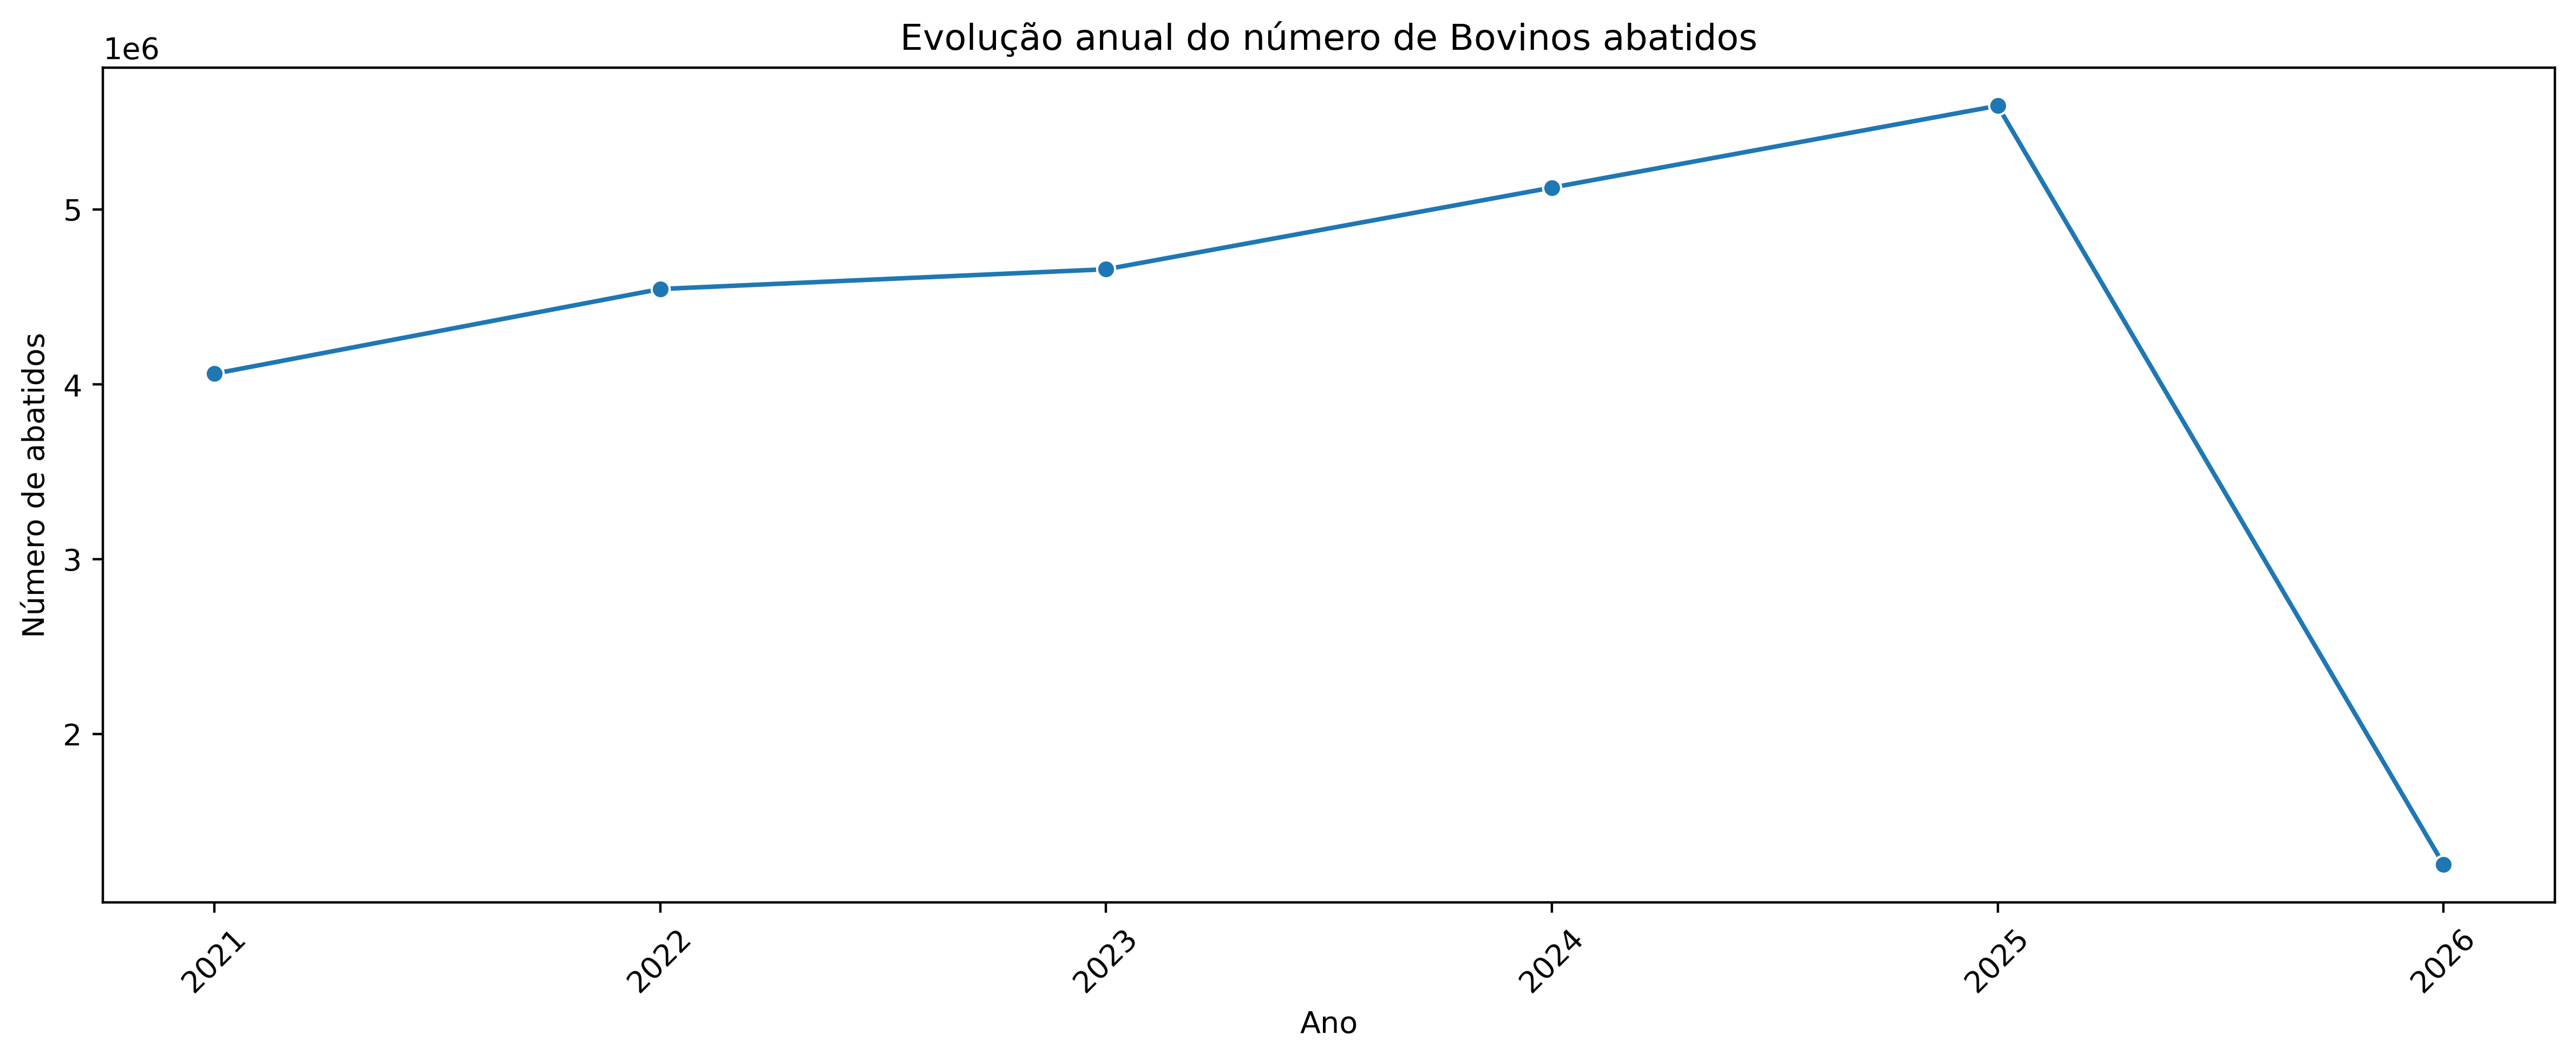

In [137]:
#criando a série anual do número de acometidos por ano
serie_anual_abate = (
   df_estat_bovino_abate_sudeste_bov.groupby("ANO", as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("ANO")
)

pl.figure(figsize=(12, 5))
sns.lineplot(
    data=serie_anual_abate,
    x="ANO",
    y="QUANTIDADE",
    marker="o"
)

pl.title("Evolução anual do número de Bovinos abatidos")
pl.xlabel("Ano")
pl.ylabel("Número de abatidos")
pl.xticks(rotation=45)
pl.tight_layout()
pl.show()


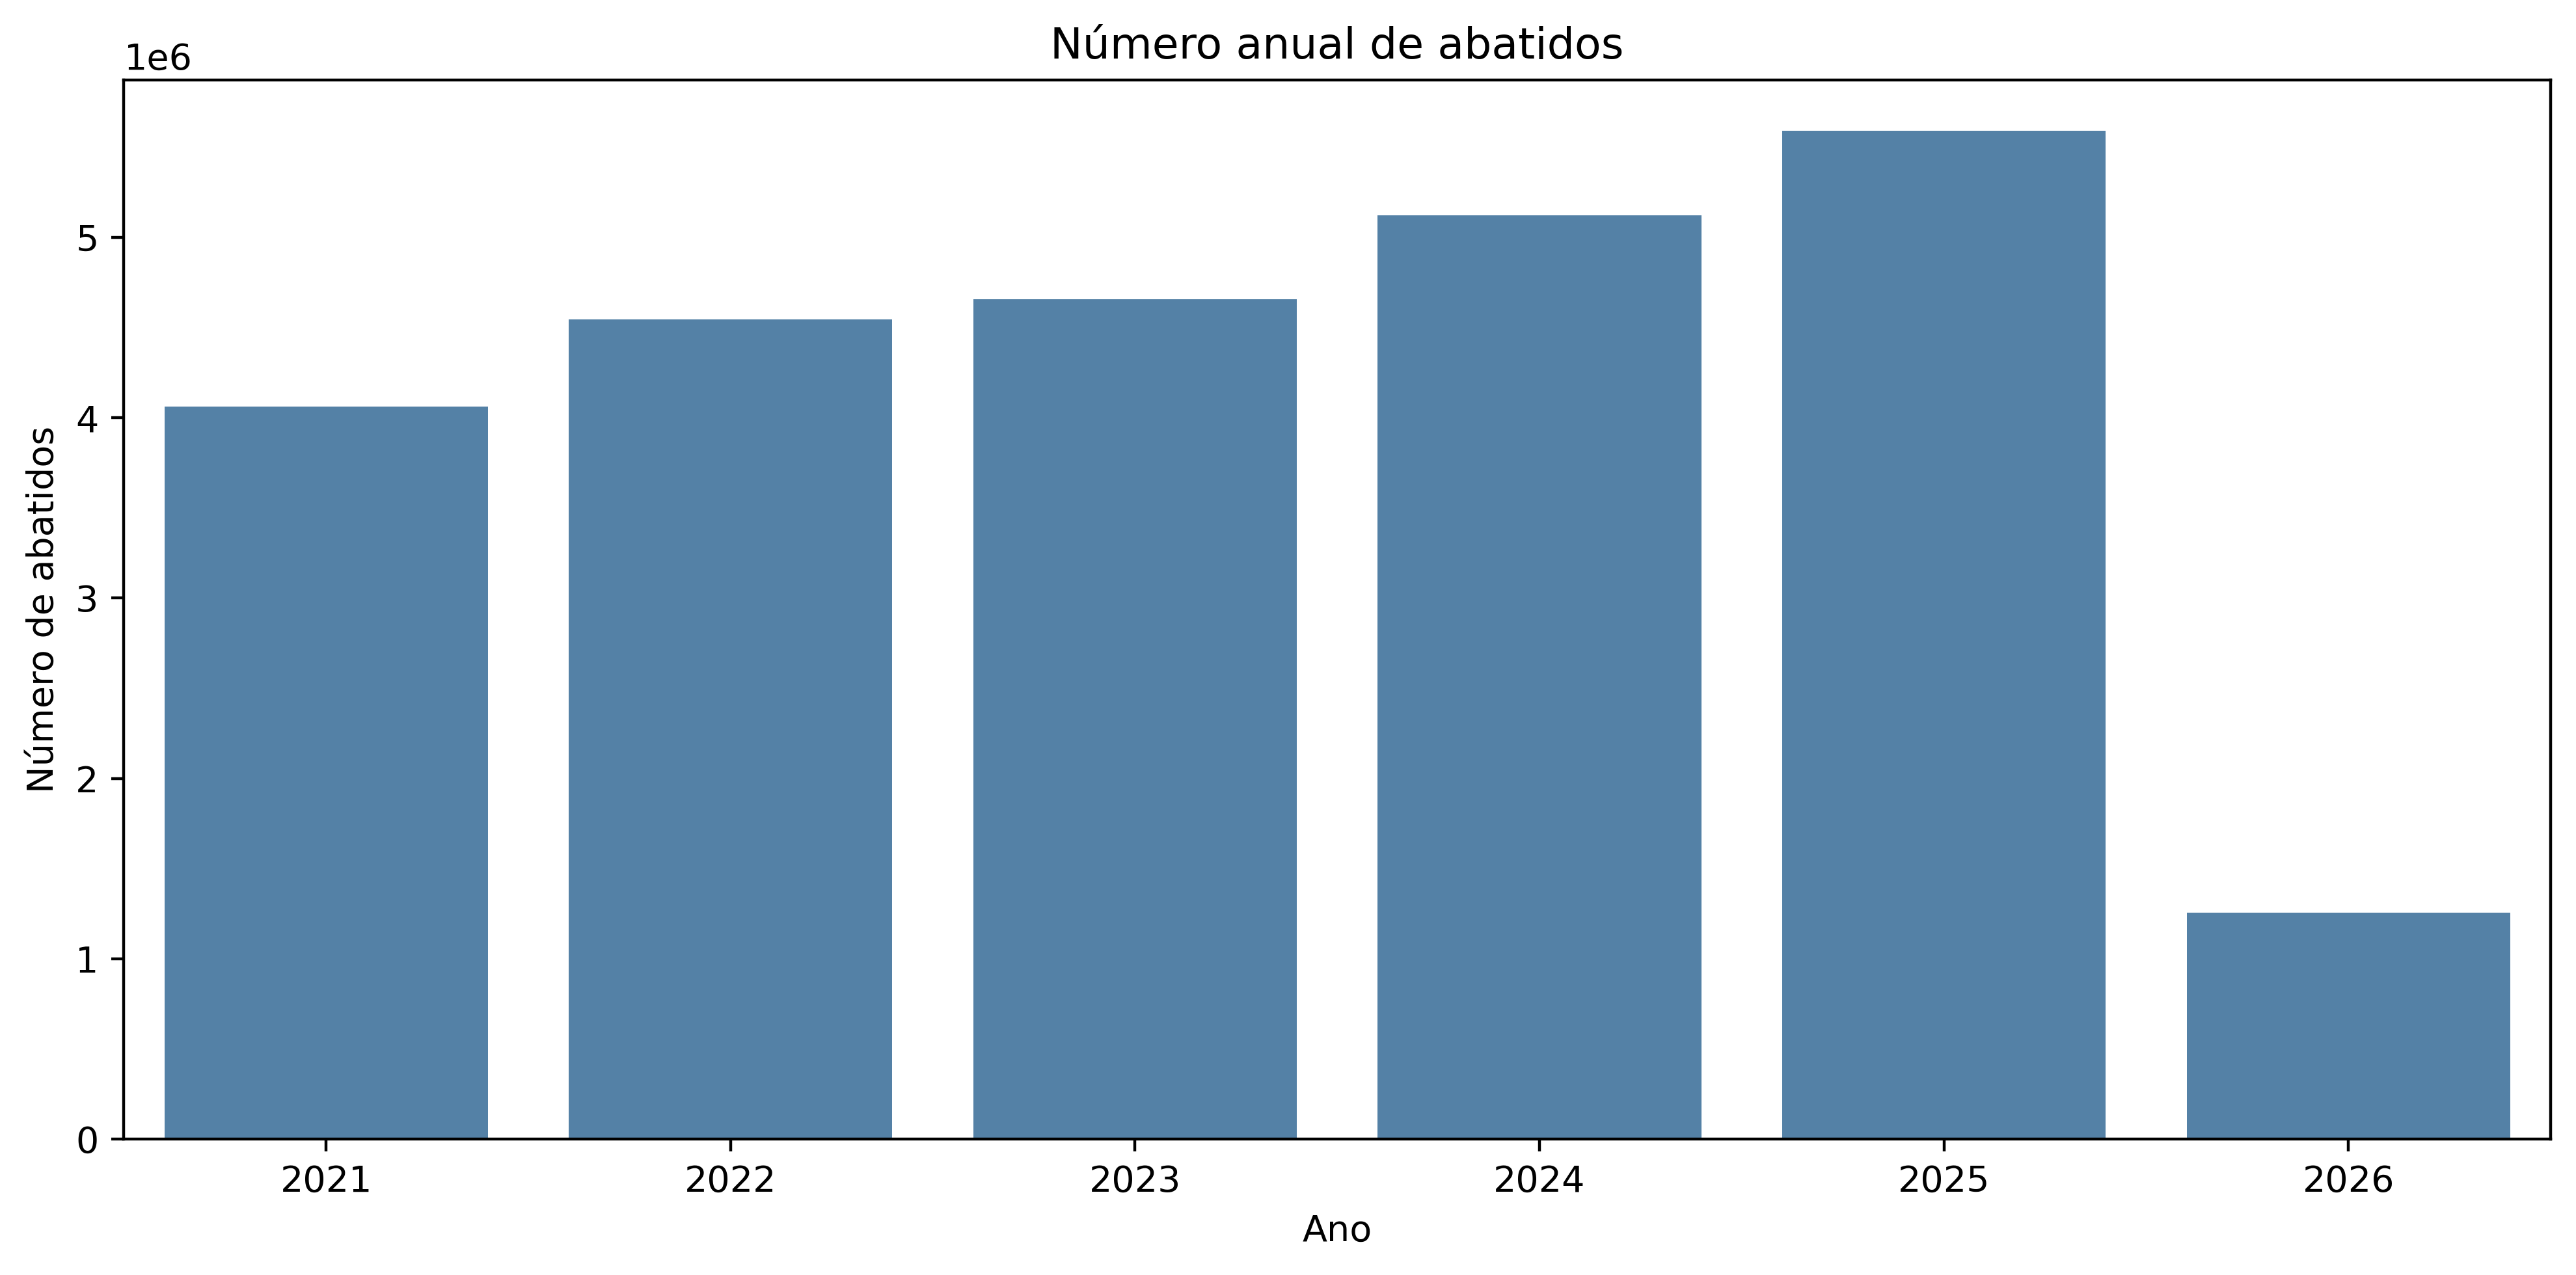

In [138]:
#criando o gráfico de barras do número anual de abatidos
pl.figure(figsize=(10, 5))

sns.barplot(
    data = (
    df_estat_bovino_abate_sudeste_bov.groupby("ANO", as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("ANO")
                        ),
    x="ANO",
    y="QUANTIDADE",
    color="steelblue"
)

pl.title("Número anual de abatidos")
pl.xlabel("Ano")
pl.ylabel("Número de abatidos")
pl.tight_layout()
pl.show()


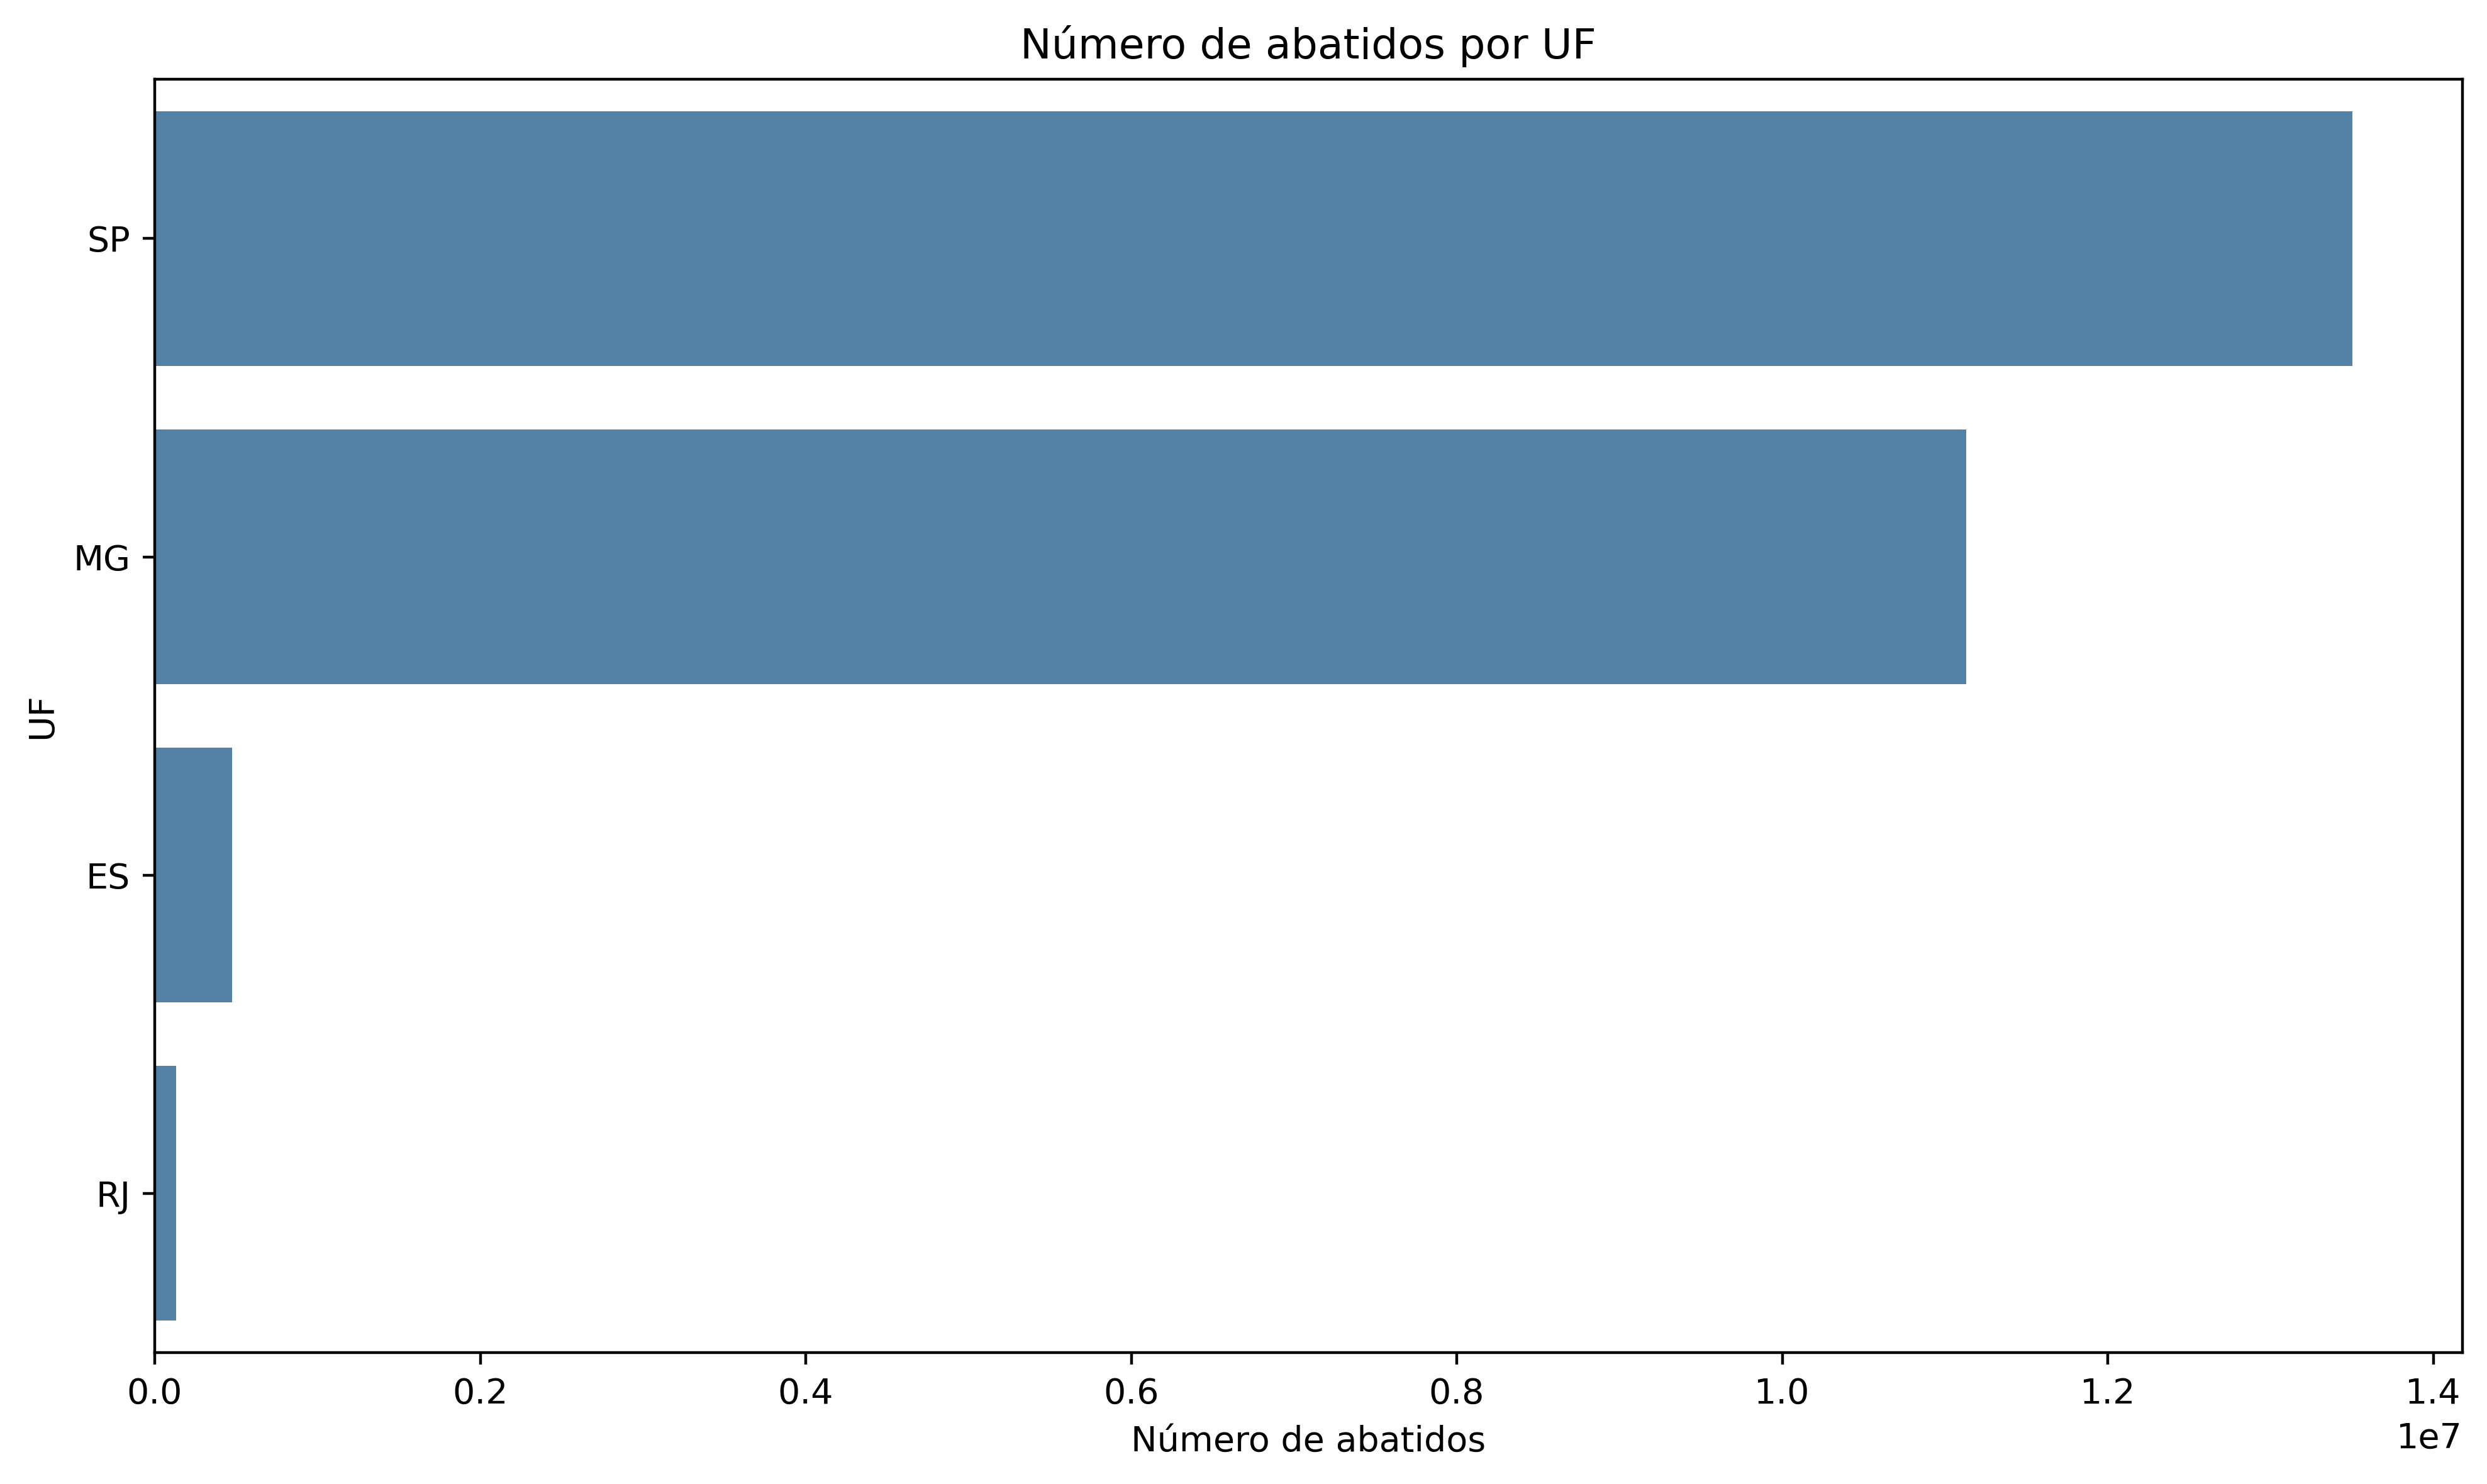

In [139]:
#realiza o ranking por estado de procedência
ranking_uf_abate = (
    df_estat_bovino_abate_sudeste_bov.groupby("UF_PROCEDENCIA", as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("QUANTIDADE", ascending=False)
)

pl.figure(figsize=(10, 6))
sns.barplot(
    data=ranking_uf_abate,
    x="QUANTIDADE",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de abatidos por UF")
pl.xlabel("Número de abatidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()


In [141]:
#criando a tabela cruzada entre estado de procedência e diagnóstico
tabela_uf_abate = pd.pivot_table(
    df_estat_bovino_abate_sudeste_bov,
    values="QUANTIDADE",
    index="UF_PROCEDENCIA",
    columns="CATEGORIA",
    aggfunc="sum",
    fill_value= 0
)

tabela_uf_abate

CATEGORIA,Bovino,Bovino Femea,Bovino Macho,Novilha Precoce,Novilho Precoce,Vaca,Vitelo
UF_PROCEDENCIA,,,,,,,
ES,472095,371,3859,0,0,0,0
MG,11007443,24112,81692,628,15157,0,13
RJ,129273,413,1756,0,0,0,0
SP,13343250,29464,129826,0,0,9,0


In [142]:
#Analisando o ranking por estado de procedência
ranking_uf_abate_tb = (
    df_estat_bovino_abate_sudeste_bov.groupby("UF_PROCEDENCIA", as_index=False)
        ["QUANTIDADE"].sum()
      .sort_values("QUANTIDADE", ascending=False)
)

ranking_uf_abate_tb


,UF_PROCEDENCIA,QUANTIDADE
3,SP,13502549
1,MG,11129045
0,ES,476325
2,RJ,131442


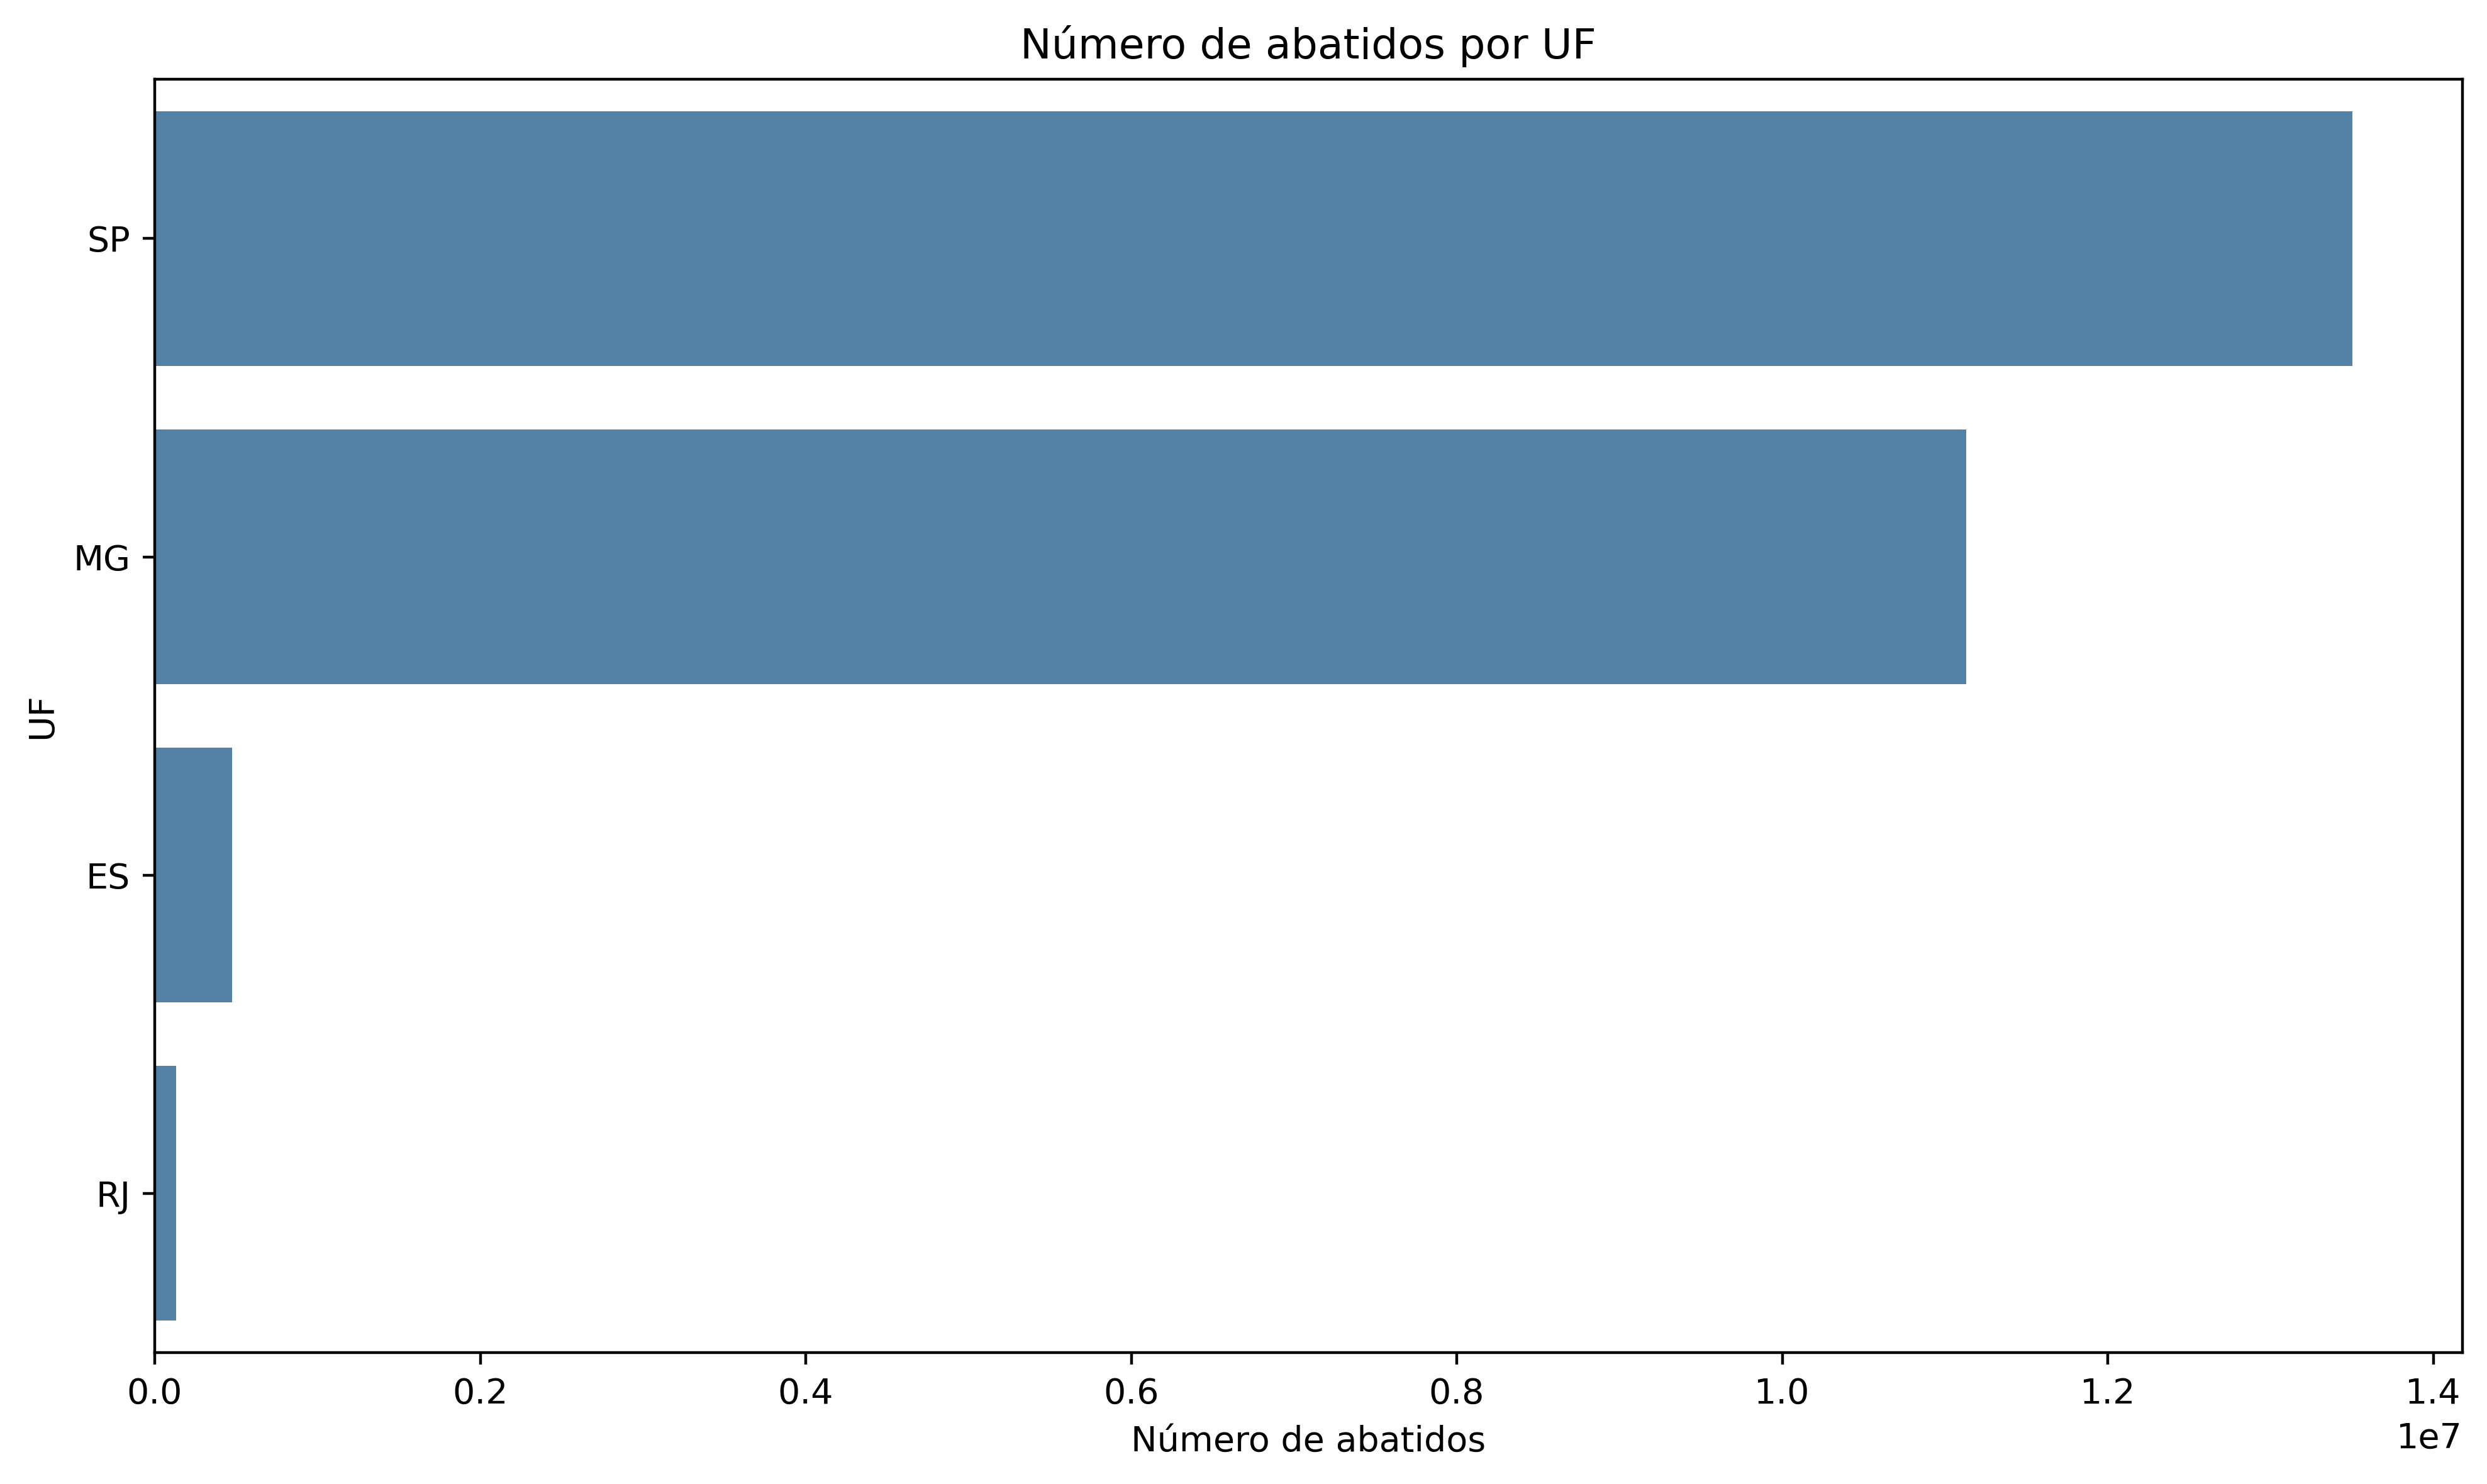

In [143]:
#Criando o gráfico de barras do número de abatidos por UF
pl.figure(figsize=(10, 6))

sns.barplot(
    data=ranking_uf_abate_tb,
    x="QUANTIDADE",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de abatidos por UF")
pl.xlabel("Número de abatidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()


In [144]:
ranking_uf_abate_tb["percentual"] = (
    ranking_uf_abate_tb["QUANTIDADE"] /
    ranking_uf_abate_tb["QUANTIDADE"].sum() * 100
)

ranking_uf_abate_tb


,UF_PROCEDENCIA,QUANTIDADE,percentual
3,SP,13502549,53.497983
1,MG,11129045,44.094005
0,ES,476325,1.887231
2,RJ,131442,0.520782


In [145]:
ranking_abate = (
    df_estat_bovino_abate_sudeste_bov.groupby("CATEGORIA", as_index=False)["QUANTIDADE"].sum().sort_values("QUANTIDADE", ascending=False)
)

ranking_abate
ranking_abate["percentual"] = (
    ranking_abate["QUANTIDADE"] /
    ranking_abate["QUANTIDADE"].sum() * 100
)

ranking_abate


,CATEGORIA,QUANTIDADE,percentual
0,Bovino,24952061,98.861699
2,Bovino Macho,217133,0.860295
1,Bovino Femea,54360,0.215378
4,Novilho Precoce,15157,0.060053
3,Novilha Precoce,628,0.002488
6,Vitelo,13,0.000052
5,Vaca,9,0.000036


In [146]:
media = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].mean()
mediana = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].median()
desvio_padrao = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].std()
variancia = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].var()
coef_variacao = desvio_padrao / media * 100
print(f"Média: {media:.2f}")
print(f"Mediana: {mediana:.2f}")
print(f"Desvio Padrão: {desvio_padrao:.2f}")
print(f"Variância: {variancia:.2f}")
print(f"Coeficiente de Variação: {coef_variacao:.2f}%")


Média: 420.82
Mediana: 99.00
Desvio Padrão: 1106.76
Variância: 1224918.47
Coeficiente de Variação: 263.00%


In [147]:
assimetria = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].skew()
curtose = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].kurtosis()
print(f"Assimetria: {assimetria:.2f}")
print(f"Curtose: {curtose:.2f}")

Assimetria: 7.68
Curtose: 105.60


In [148]:
minimo = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].min()
maximo = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].max()
amplitude = maximo - minimo

q1 = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].quantile(0.25)
q3 = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].quantile(0.75)
iqr = q3 - q1
print(f"Valor mínimo: {minimo}")
print(f"Valor máximo: {maximo}")
print(f"Amplitude: {amplitude}")
print(f"Q1: {q1}")
print(f"Q3: {q3}")
print(f"IQR: {iqr}")


Valor mínimo: 1
Valor máximo: 43708
Amplitude: 43707
Q1: 38.0
Q3: 300.0
IQR: 262.0


In [149]:
q1 = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].quantile(0.25)
q3 = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].quantile(0.75)
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = df_estat_bovino_abate_sudeste_bov[
    (df_estat_bovino_abate_sudeste_bov["QUANTIDADE"] < limite_inferior) |
    (df_estat_bovino_abate_sudeste_bov["QUANTIDADE"] > limite_superior)
]

print(f"Outliers encontrados:\n{outliers}")


Outliers encontrados:
         ANO  MES UF_PROCEDENCIA  MUNICIPIO_PROCEDENCIA     CATEGORIA  \
0       2025    8             MG               Araguari        Bovino   
1       2025    9             MG  Monte Alegre de Minas        Bovino   
3       2021    2             MG         Estrela do Sul        Bovino   
4       2021    2             MG          Campina Verde        Bovino   
6       2021    3             MG            Tupaciguara        Bovino   
...      ...  ...            ...                    ...           ...   
516052  2021    1             MG            Tupaciguara  Bovino Femea   
516063  2021    1             MG              Gurinhatã  Bovino Macho   
516071  2021    1             SP              Bebedouro  Bovino Macho   
516113  2021    1             SP                  Caiuá  Bovino Macho   
516268  2021    1             SP        Pereira Barreto  Bovino Macho   

                 Sexo Espécie  QUANTIDADE  
0       Indeterminado  Bovino        3697  
1       Indet

In [150]:
desc_por_uf_abate = (
      df_estat_bovino_abate_sudeste_bov.groupby("UF_PROCEDENCIA")["QUANTIDADE"]
      .agg(["count", "sum", "mean", "median", "std", "min", "max"])
      .sort_values("sum", ascending=False)
)

desc_por_uf_abate

,count,sum,mean,median,std,min,max
UF_PROCEDENCIA,,,,,,,
SP,21775,13502549,620.094099,176.0,1390.697349,1,43708
MG,34404,11129045,323.481136,79.0,920.482373,1,19694
ES,1977,476325,240.933232,60.0,599.206913,1,9991
RJ,1821,131442,72.181219,41.0,102.825608,1,3182


In [151]:
desc_por_categoria_abate = (
    df_estat_bovino_abate_sudeste_bov.groupby("CATEGORIA")["QUANTIDADE"]
      .agg(["count", "sum", "mean", "median", "std", "min", "max"])
      .sort_values("sum", ascending=False)
)
desc_por_categoria_abate


,count,sum,mean,median,std,min,max
CATEGORIA,,,,,,,
Bovino,58507,24952061,426.479925,100.0,1115.494651,1,43708
Bovino Macho,805,217133,269.730435,56.0,818.949762,1,11271
Bovino Femea,602,54360,90.299003,31.0,223.016583,1,3566
Novilho Precoce,47,15157,322.489362,169.0,391.903375,8,1721
Novilha Precoce,14,628,44.857143,16.5,73.651839,1,266
Vitelo,1,13,13.000000,13.0,NaN,13,13
Vaca,1,9,9.000000,9.0,NaN,9,9


In [154]:
ranking_uf_abate = (
    df_estat_bovino_abate_sudeste_bov.groupby("UF_PROCEDENCIA", as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("QUANTIDADE", ascending=False)
)

ranking_uf_abate["percentual"] = (
    ranking_uf_abate["QUANTIDADE"] /
    ranking_uf_abate["QUANTIDADE"].sum() * 100
)

ranking_uf_abate["percentual_acumulado"] = ranking_uf_abate["percentual"].cumsum()

ranking_uf_abate


,UF_PROCEDENCIA,QUANTIDADE,percentual,percentual_acumulado
3,SP,13502549,53.497983,53.497983
1,MG,11129045,44.094005,97.591987
0,ES,476325,1.887231,99.479218
2,RJ,131442,0.520782,100.000000


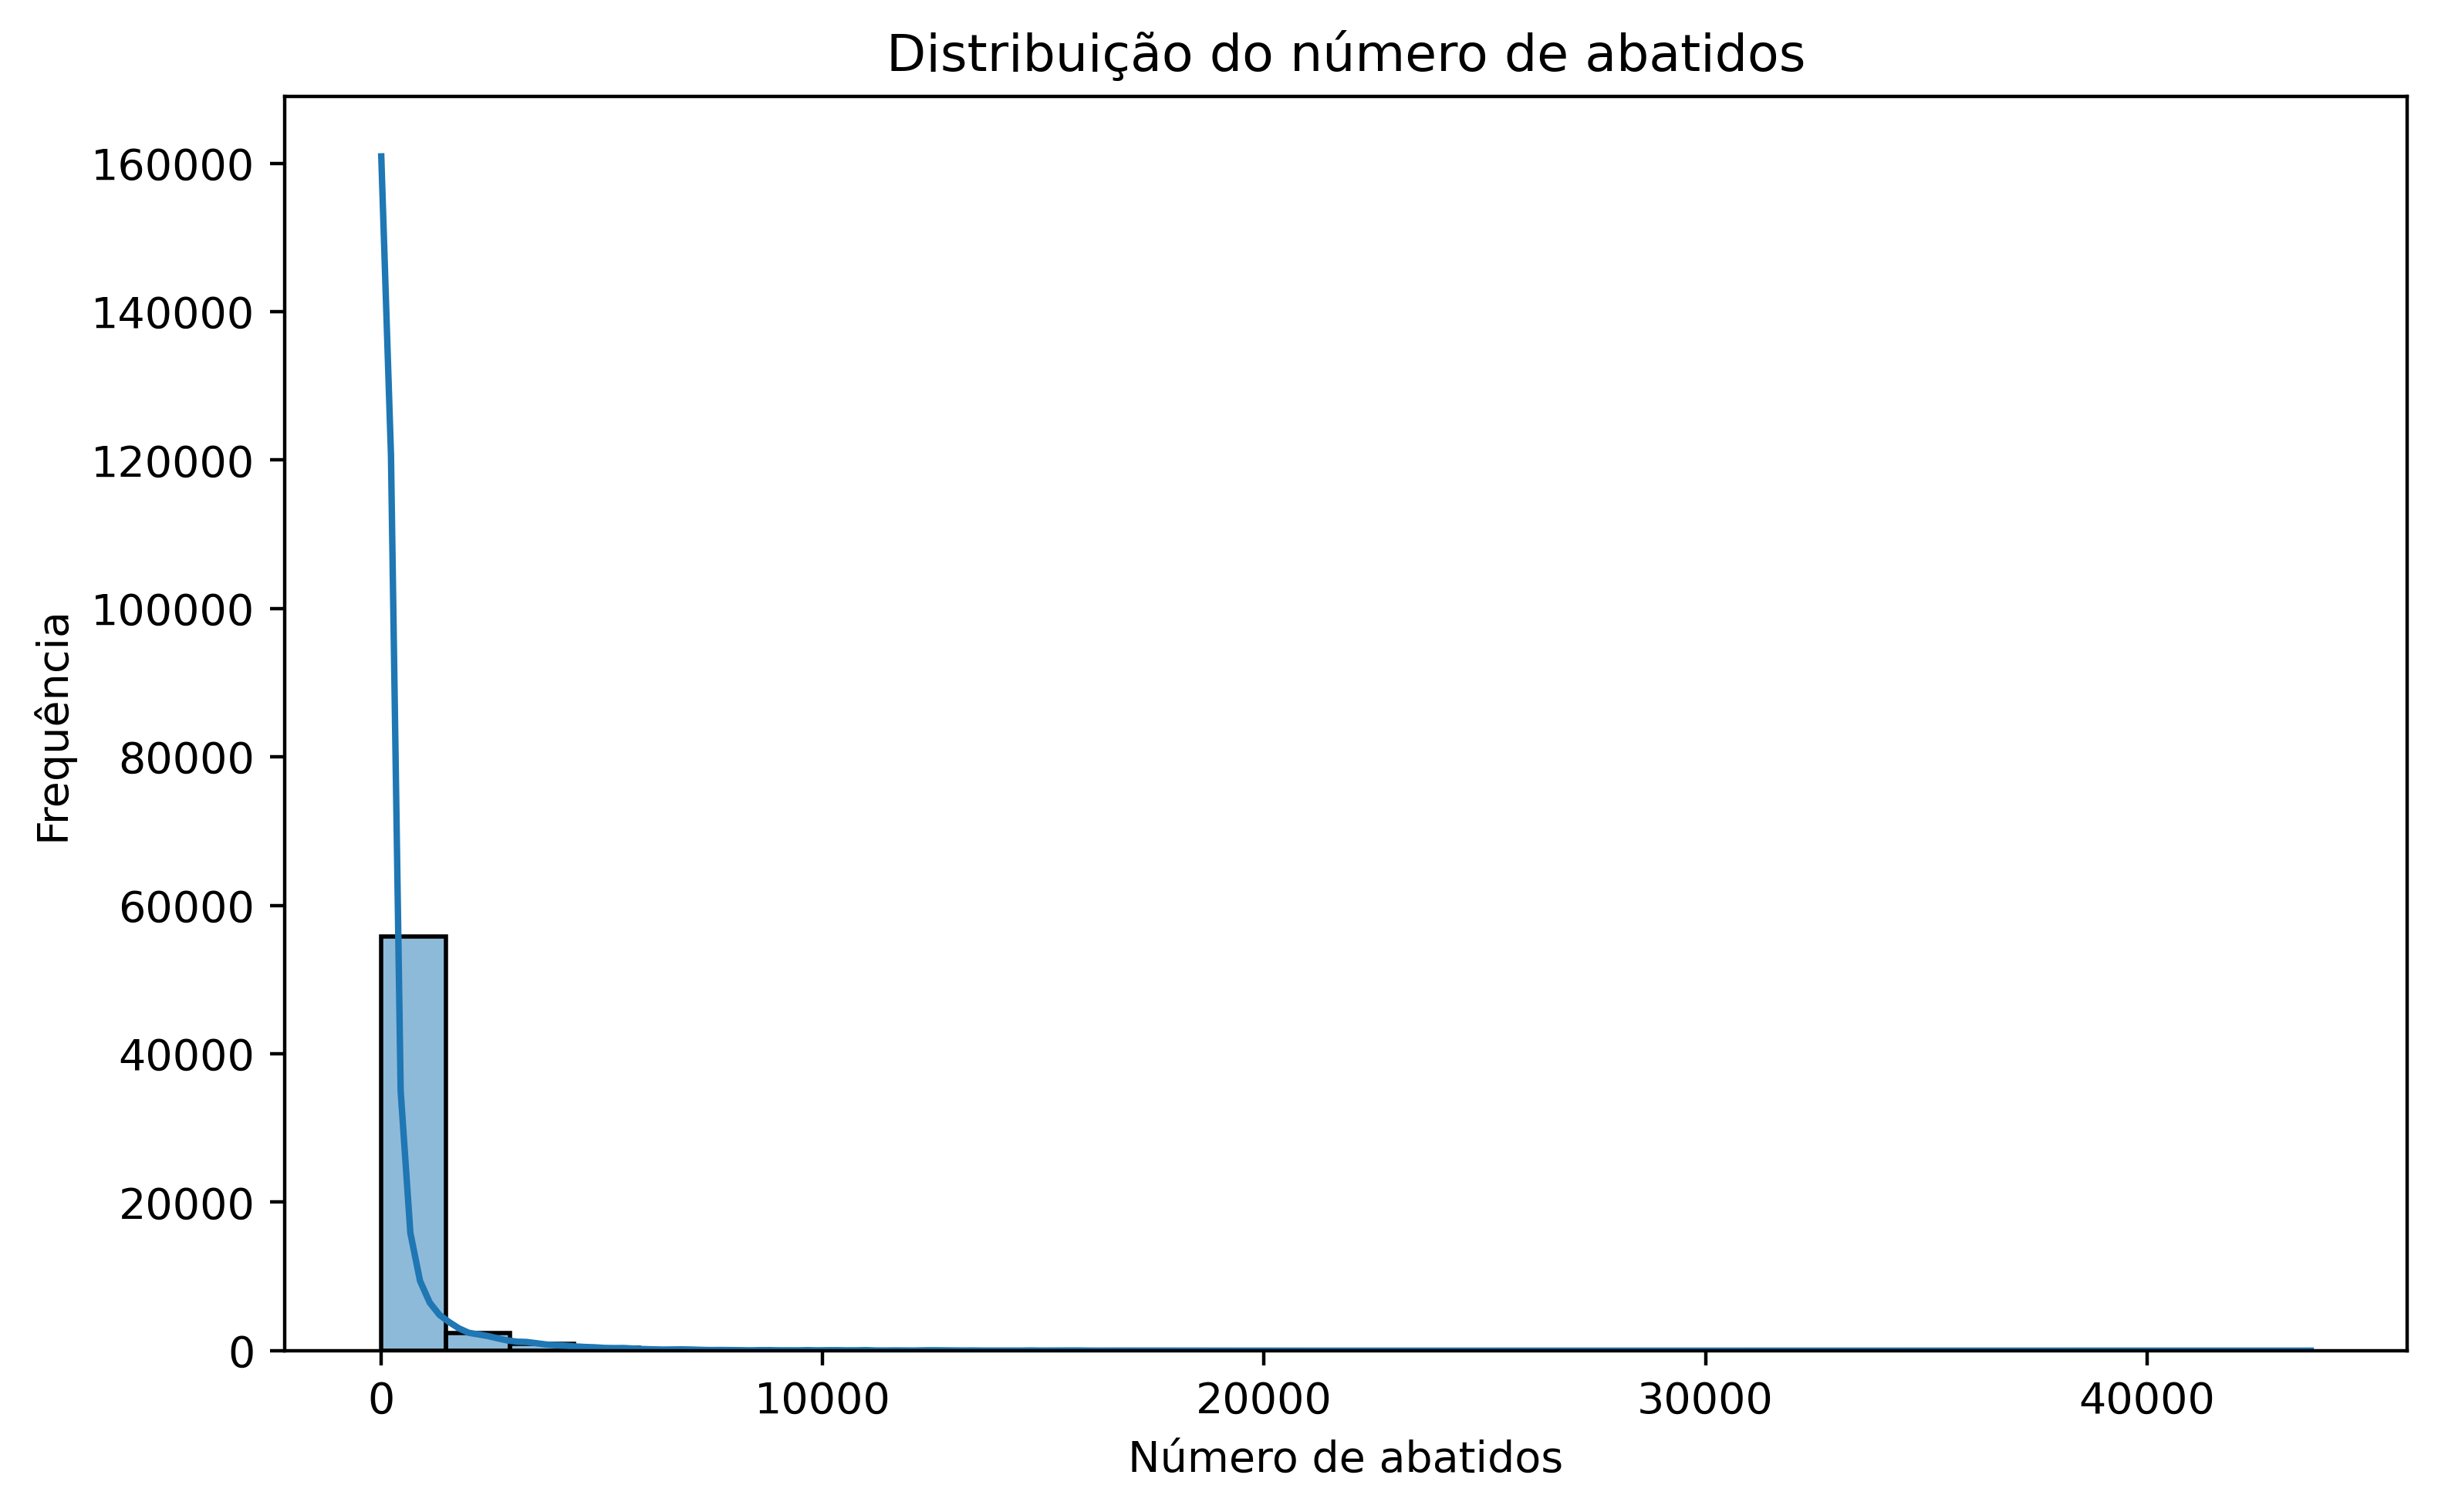

In [155]:
pl.figure(figsize=(8, 5))

sns.histplot(
    data=df_estat_bovino_abate_sudeste_bov,
    x="QUANTIDADE",
    bins=30,
    kde=True
)

pl.title("Distribuição do número de abatidos")
pl.xlabel("Número de abatidos")
pl.ylabel("Frequência")
pl.tight_layout()
pl.show()


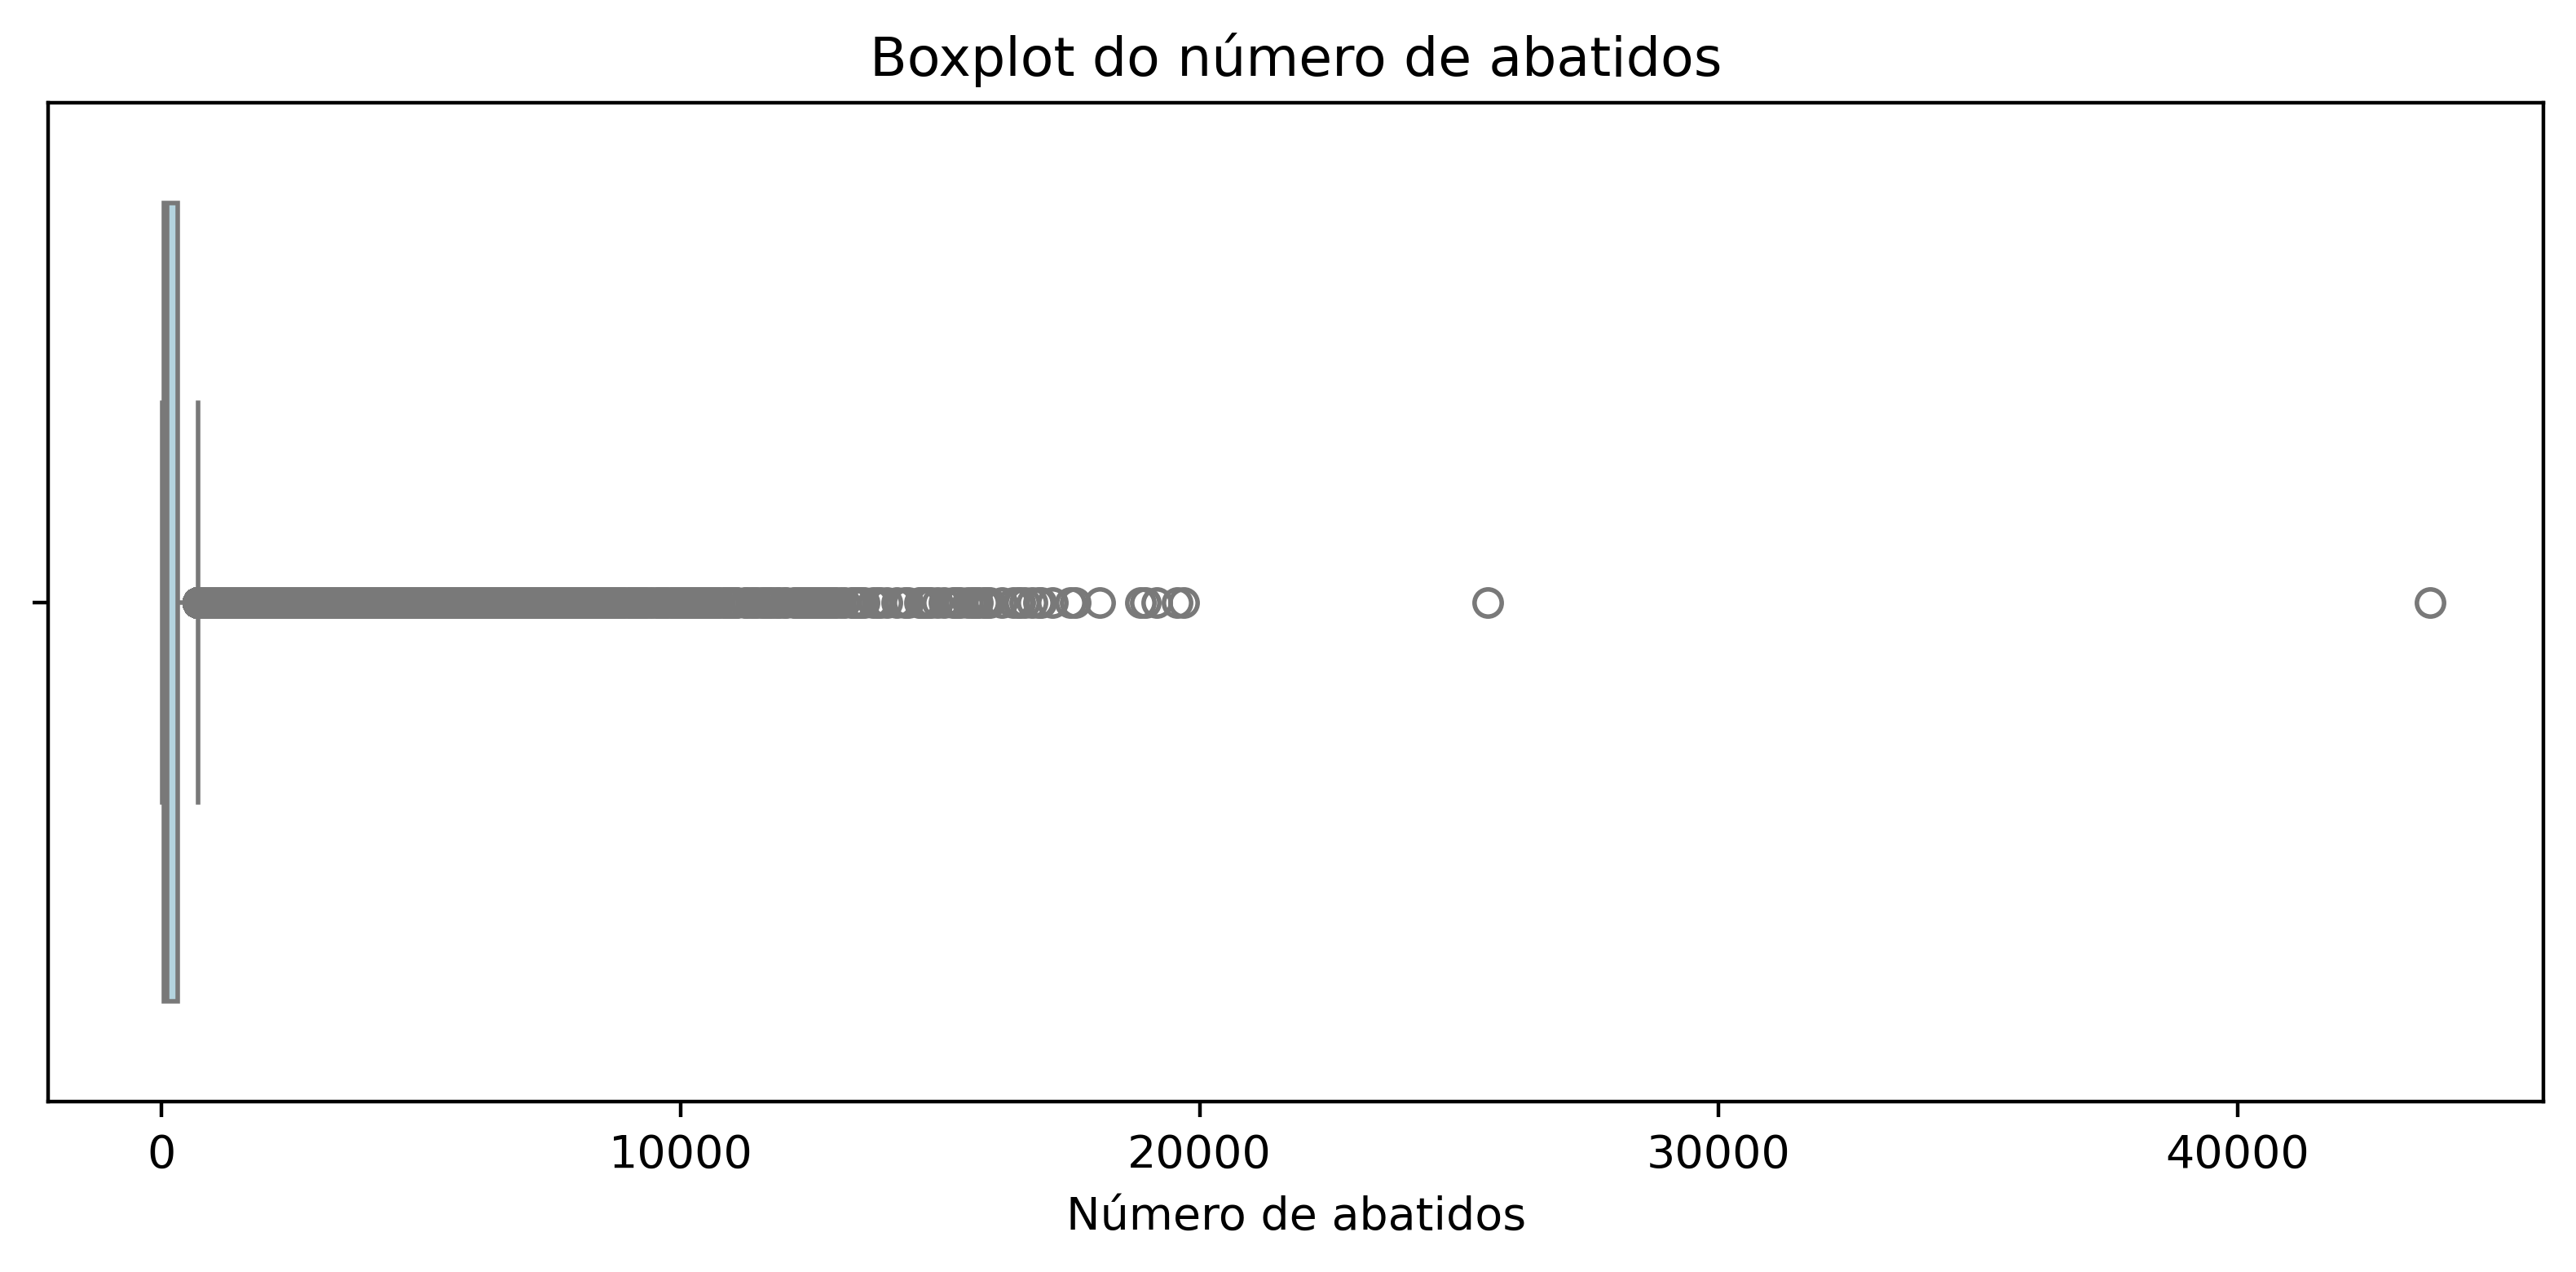

In [156]:
pl.figure(figsize=(8, 4))

sns.boxplot(
    data=df_estat_bovino_abate_sudeste_bov,
    x="QUANTIDADE",
    color="lightblue"
)

pl.title("Boxplot do número de abatidos")
pl.xlabel("Número de abatidos")
pl.tight_layout()
pl.show()